# REPLICA del 04 sulla sessione 19250120T115044

Bin di FALCON; stessi iperparametri del 04, senza sweep né alternative (senza il §6). Generato da rep/make_04.py.

# 04 · Metodi "deep": CEBRA e LFADS · FALCON H1

**Obiettivo.** Nei notebook 02 e 03 ogni metodo seguiva una ricetta fissa per passare dai dati
alle coordinate: proiezioni lineari (PCA, FA, GPFA) o costruzioni sul grafo dei vicini (Isomap,
UMAP). Qui la ricetta la impara una **rete neurale**, cioè una funzione non lineare con molti
parametri regolati sui dati (review, §4.2).

- **Parte A, CEBRA** (Schneider, Lee & Mathis 2023), questo notebook.
- **Parte B, LFADS** (Pandarinath et al. 2018), §9-§15, dopo la parte A.

**CEBRA in una frase.** Una rete impara a mettere **vicini** nella mappa gli istanti che "vanno
insieme" e **lontani** quelli presi a caso. Che cosa vuol dire "vanno insieme" lo decidiamo noi:

- **CEBRA-Time**: istanti vicini nel tempo. Non usa nessuna etichetta;
- **CEBRA-Behavior**: istanti con un comportamento simile. Usa le etichette.

Due precisazioni da tenere presenti in tutto il notebook:

- **CEBRA non è un modello generativo.** Ha solo la metà che va dai dati alla mappa (l'*encoder*),
  non quella che dalla mappa ricostruisce i dati. Per questo lo chiamiamo "deep" o "contrastivo",
  mai "generativo".
- **CEBRA-Time avvicina istanti vicini nel tempo**: è proprio la "catena del tempo" che nel 03
  (§2) abbiamo dovuto evitare. Dovremo dimostrare che la mappa contiene più di quella.

Le domande:

1. Con 2-3 coordinate, CEBRA-Time riconosce le fasi del task meglio di PCA, Isomap e UMAP? E
   rispetto a un "tetto" costruito alla pari, con lo stesso input e la stessa finestra di tempo?
2. Che cosa impara: la struttura del task o solo la catena del tempo?
3. Con le etichette (CEBRA-Behavior), quanto si guadagna rispetto a un metodo lineare che usa le
   stesse etichette?

La pipeline:

```
spike_times ──(come nel 02/03: bin 20 ms, 160 canali attivi, σ = 50 ms, z-score)──► Z    12233 × 160

Z ──(§1: PCA a 25 stimata sui soli trial di training, applicata a tutta la sessione)──► input di CEBRA

input ──(CEBRA: rete che legge una finestra di tempo)──► mappa a poche dimensioni

valutazione: gli stessi 1106 punti del 03 (fasi di movimento, un bin ogni 100 ms), su trial mai visti
```

Il notebook si costruisce **un passo alla volta**: §1 dati e metro comune · §2 l'idea su un
esempio sintetico · §3 CEBRA-Time, un allenamento · §4 valutazione con il metro comune ·
§5 controlli · §6 CEBRA-Behavior · §7 sensibilità e alternative · §8 riepilogo.
**Stato attuale: completo. Parte A (CEBRA), §0-§8; parte B (LFADS), §9-§15.**

Stessa sessione di tutti i notebook (`held-in-calib`, `19250108T110520`).

**Tempo di esecuzione:** circa 6-7 minuti se gli allenamenti sono già salvati su disco (§3.1);
circa 2 ore la prima volta (molto di più con il computer sotto carico: il §7 da solo ha richiesto
quasi 2 ore). Con il computer sotto carico può volerci molto di più (un'esecuzione è
durata 39 minuti).

## 0 · Setup

In [1]:
import os                                         # per impostare variabili d'ambiente prima degli altri import
os.environ.setdefault("KMP_WARNINGS", "off")      # nasconde un messaggio innocuo di OpenMP che comparirebbe con UMAP
os.environ.setdefault("NUMBA_THREADING_LAYER", "workqueue")  # numba (usato da UMAP) non carica una seconda copia di OpenMP: insieme a quella di scikit-learn il kernel a volte si blocca (come nel 03)
import sys                                        # per aggiungere src/ ai percorsi in cui Python cerca i moduli
import warnings                                   # per nascondere avvisi innocui
warnings.filterwarnings("ignore")                 # scikit-learn e UMAP stampano avvisi innocui (anche all'import di UMAP)
from pathlib import Path                          # percorsi dei file, indipendenti dal sistema operativo

import numpy as np                                # array e algebra lineare
import pandas as pd                               # tabelle per i riepiloghi
import matplotlib.pyplot as plt                   # figure
from joblib import Parallel, delayed              # per far girare in parallelo le ripetizioni con semi diversi
from sklearn.decomposition import PCA             # PCA (input dei metodi e metodo di confronto)
from sklearn.preprocessing import StandardScaler  # z-score colonna per colonna
from sklearn.manifold import Isomap               # Isomap, metodo di confronto (notebook 03)
from sklearn.neighbors import KNeighborsClassifier  # il classificatore "a vicini" del metro comune
from sklearn.model_selection import GroupKFold    # cross-validation che tiene insieme i bin dello stesso trial
from sklearn.metrics import balanced_accuracy_score  # accuratezza che pesa allo stesso modo tutte le fasi
from umap import UMAP                             # UMAP, metodo di confronto (notebook 03, §9)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # radice del progetto, da qualunque cartella parta il notebook
sys.path.insert(0, str(ROOT / "src"))             # rende importabile il pacchetto del progetto
from tesi_h1 import io                            # caricamento dei dati, fasi, colori (verificati passo per passo nel 02_new)

FIGS = ROOT / "figures"                           # cartella delle figure in PNG
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})  # stesso stile grafico degli altri notebook

SESS = ROOT / "data/raw/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-19250108T110520.nwb"  # sessione analizzata

In [2]:
# ===== REPLICA (aggiunta): sessione 19250120T115044, bin di FALCON =====
SID = "19250120T115044"
REP = Path("/Users/valerio/tesi_h1_work/rep") / SID                            # risultati e figure di questa sessione
REP.mkdir(parents=True, exist_ok=True)
SESS = ROOT / f"data/raw/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-{SID}.nwb"
FIGS = REP / "figures"; FIGS.mkdir(exist_ok=True)
exec(open("/Users/valerio/tesi_h1_work/rep/falcon_patch.py", encoding="utf-8").read())
OUT_NAME = "04_rep"
SMOKE = False

REPLICA sub-HumanPitt-held-in-calib_ses-19250120T115044.nwb: bin di FALCON (controllo con load_nwb superato), figure in /Users/valerio/tesi_h1_work/rep/19250120T115044/figures


## 1 · I dati e il metro comune

Prima di introdurre CEBRA rifacciamo il punto di partenza del 03: stessi dati, stessi punti di
valutazione, stessa cross-validation, stessi numeri. Poi prendiamo le tre decisioni sui dati che
riguardano solo CEBRA (§1.3-§1.5).

### 1.1 · Gli stessi dati del notebook 03

Bin da 20 ms, 160 canali attivi (≥ 0.5 Hz), smoothing gaussiano con σ = 50 ms, z-score per
canale: è la pipeline ricostruita a mano nel 02_new e usata nel 03 (§1). A ogni bin associamo due
etichette che **non** entrano in CEBRA-Time ma servono a valutarlo: la **fase del task** e il
**trial**.

I **punti di valutazione** sono quelli del 03 (§2): i bin delle 8 fasi di movimento, uno ogni 5
(uno ogni 100 ms), per non misurare la catena del tempo. La **cross-validation** è la stessa:
5 blocchi da 3 trial (`GroupKFold`), così ogni trial finisce nel test una volta sola.

In [3]:
s = io.load_session(SESS)                                   # conteggi a 20 ms, cinematica, fasi del task
ACTIVE = io.active_units(s, min_hz=0.5)                     # i 160 canali attivi
Z = StandardScaler().fit_transform(                         # z-score per canale...
    io.smooth_rates(s.spikes, sigma_ms=50)[:, ACTIVE].astype(float))  # ...dei firing rate smussati con σ = 50 ms
n_bins = s.n_bins                                           # numero di bin della sessione

def base_tag(tag):                                          # "Presentation3" -> "Presentation": un'etichetta per tutte le presentazioni
    return "Presentation" if tag.startswith("Presentation") else tag

phase = np.array([base_tag(p) for p in io.phase_per_bin(s)], dtype=object)  # fase di ogni bin ("" se nessuna fase lo copre)
trial = s.trial_num                                         # trial di ogni bin (da 1 a 15)
MOV = np.isin(phase, io.MOVEMENT_PHASES)                    # vero per i bin che cadono in una fase di movimento

STEP = 5                                                    # un bin ogni 5 = uno ogni 100 ms (03, §2)
K_PCA = 25                                                  # dimensioni della PCA iniziale (03, §2: il numero di fattori scelto per la GPFA)
K_NN = 10                                                   # vicini del classificatore e di Isomap/UMAP (03)
bins_all = np.flatnonzero(MOV)                              # tutti i bin delle fasi di movimento
bins = bins_all[bins_all % STEP == 0]                       # i punti di valutazione: uno ogni 100 ms
FOLDS = list(GroupKFold(n_splits=5).split(bins, groups=trial[bins]))  # i 5 blocchi del 03: (indici di training, indici di test) tra i punti
TEST_TRIALS = [np.unique(trial[bins[tst]]) for _, tst in FOLDS]       # i 3 trial di test di ogni blocco

print(f"Z: {Z.shape[0]} bin × {Z.shape[1]} canali, {len(np.unique(trial))} trial, {n_bins * io.BIN_S / 60:.1f} minuti")
print(f"Punti di valutazione: {len(bins)} (bin di movimento: {len(bins_all)})")
print("Trial di test per blocco:", {k: t.tolist() for k, t in enumerate(TEST_TRIALS)})

Z: 12078 bin × 165 canali, 15 trial, 4.0 minuti
Punti di valutazione: 1137 (bin di movimento: 5668)
Trial di test per blocco: {0: [5, 8, 9], 1: [3, 4, 15], 2: [2, 12, 14], 3: [7, 10, 11], 4: [1, 6, 13]}


**La cinematica.** Al §6 (CEBRA-Behavior) potremo usare la cinematica come etichetta. Il file ne
contiene due versioni, entrambe a 7 gradi di libertà (traslazione x, y, z, orientamento, tre
gradi della presa): la **posizione** (`s.kin`) e la **velocità** (`s.vel`, il bersaglio ufficiale
del benchmark FALCON). Controlliamo che la seconda sia davvero la variazione della prima.

In [4]:
dkin = np.diff(s.kin, axis=0) / io.BIN_S                    # variazione della posizione da un bin al successivo, per secondo
r_vel = [np.corrcoef(dkin[:, j], s.vel[1:, j])[0, 1] for j in range(7)]  # correlazione con la velocità del file, grado per grado
print(f"Posizione {s.kin.shape}, velocità {s.vel.shape}")
print("Correlazione tra variazione della posizione e velocità:", dict(zip(io.KIN_LABELS, np.round(r_vel, 2))))

Posizione (12078, 7), velocità (12078, 7)
Correlazione tra variazione della posizione e velocità: {'tx': np.float64(0.59), 'ty': np.float64(0.76), 'tz': np.float64(0.46), 'rx': np.float64(0.76), 'g1': np.float64(0.7), 'g2': np.float64(0.68), 'g3': np.float64(0.86)}


**Lettura.** La correlazione è alta per tutti e 7 i gradi di libertà (da 0.73 a 0.91): `s.vel` è
la velocità della posizione `s.kin`. Non vale 1, probabilmente perché il file calcola la velocità
con un filtro o uno sfasamento diverso dalla semplice differenza tra bin consecutivi; non l'abbiamo
verificato, e per il §6 non cambia nulla.

### 1.2 · Il metro comune: rifacciamo i numeri del 03

Per confrontare CEBRA con tutto il resto usiamo **una sola misura**, quella del 03 (§6 e §9.1):

- **riconoscimento della fase**: un classificatore a 10 vicini guarda le coordinate di un punto e
  dice in che fase del task si trova. **Accuratezza bilanciata**: la media, sulle 8 fasi, della
  frazione di punti riconosciuti; a caso vale 1/8 = 12.5%;
- **stima pulita**: in ogni blocco il metodo (PCA iniziale compresa) si stima **solo sui trial di
  training**; i punti dei trial di test si proiettano dopo, con `transform`. La "scorciatoia" del
  03 (§7), cioè stimare il metodo su tutti i trial e fare la cross-validation solo sul
  classificatore, gonfia il risultato ed è vietata;
- il **tetto**: lo stesso classificatore senza nessuna mappa, sulle 25 dimensioni.

Le funzioni sono riscritte dal 03 (§9.1). Le facciamo girare con 2 e 3 dimensioni: al §4 servono
entrambe, perché "3 dimensioni" di CEBRA non equivalgono a 3 componenti della PCA (lo vedremo).
I numeri devono coincidere con quelli del 03.

In [5]:
PCA_F = [PCA(K_PCA).fit(Z[bins_all[~np.isin(trial[bins_all], tt)]])  # in ogni blocco, la PCA a 25 vede solo i bin di movimento dei trial di training (03, §9.1)
         for tt in TEST_TRIALS]
X25 = [p.transform(Z) for p in PCA_F]                       # per ogni blocco, tutta la sessione proiettata sulle sue 25 direzioni (12233 × 25)
INP_PC = (bins, [(X25[k][bins[trn]], X25[k][bins[tst]], trn, tst)  # l'input del metro comune: punti, e per ogni blocco (training, test, indici)
                 for k, (trn, tst) in enumerate(FOLDS)])

def decode_map(inp, embed):                                 # accuratezza bilanciata (%) con una mappa qualsiasi, stima pulita (03, §9.1)
    b, folds = inp
    pred = np.empty(len(b), dtype=object)                   # la fase prevista per ogni punto, quando è nel test
    for Xtr, Xte, trn, tst in folds:
        Etr, Ete = embed(Xtr, Xte)                          # la mappa si stima sul training; i punti di test si proiettano
        pred[tst] = KNeighborsClassifier(n_neighbors=K_NN).fit(Etr, phase[b[trn]]).predict(Ete)
    return balanced_accuracy_score(phase[b], pred) * 100

def emb_pca(d):                                             # PCA a d dimensioni sui 25 PC di training (03, §9.1)
    def f(Xtr, Xte):
        p_ = PCA(d).fit(Xtr)
        return p_.transform(Xtr), p_.transform(Xte)
    return f

def emb_isomap(d):                                          # Isomap con k = 10 (03, §6)
    def f(Xtr, Xte):
        i_ = Isomap(n_neighbors=K_NN, n_components=d).fit(Xtr)
        return i_.embedding_, i_.transform(Xte)
    return f

def emb_umap(d, seed=0):                                    # UMAP con n_neighbors = 10, min_dist = 0.1 (03, §9.1)
    def f(Xtr, Xte):
        u = UMAP(n_neighbors=K_NN, n_components=d, min_dist=0.1, random_state=seed, n_jobs=1).fit(Xtr)
        return u.embedding_, u.transform(Xte)
    return f

def emb_none(Xtr, Xte):                                     # nessuna mappa: il classificatore lavora sulle 25 dimensioni (il tetto)
    return Xtr, Xte

SEEDS = range(5)                                            # i 5 semi delle misure che dipendono dal caso

def mean_range(a):                                          # "media (minimo-massimo)" di una serie di ripetizioni
    return f"{np.mean(a):.1f} ({np.min(a):.1f}-{np.max(a):.1f})"

REF_03 = {"PCA, d = 2": "26.0", "PCA, d = 3": "32.4", "Isomap, d = 2": "31.8", "Isomap, d = 3": "36.0",  # i numeri del 03 (§6 e §9.1), da riprodurre
          "UMAP, d = 2": "41.2 (40.4-42.3)", "UMAP, d = 3": "42.6 (41.9-43.2)", "tetto, 25 dimensioni": "42.2"}

ACC = {}                                                    # le accuratezze di questo notebook: nome -> valore (o lista di 5 valori)
for d in (2, 3):
    ACC[f"PCA, d = {d}"] = decode_map(INP_PC, emb_pca(d))
    ACC[f"Isomap, d = {d}"] = decode_map(INP_PC, emb_isomap(d))
    ACC[f"UMAP, d = {d}"] = Parallel(n_jobs=5)(delayed(decode_map)(INP_PC, emb_umap(d, sd)) for sd in SEEDS)  # 5 semi in parallelo
ACC["tetto, 25 dimensioni"] = decode_map(INP_PC, emb_none)

tab_ref = pd.DataFrame({"qui": {k: mean_range(v) if isinstance(v, list) else f"{v:.1f}" for k, v in ACC.items()},
                        "notebook 03": REF_03})
display(tab_ref)

,qui,notebook 03
"PCA, d = 2",23.8,26.0
"Isomap, d = 2",26.5,31.8
"UMAP, d = 2",35.5 (34.6-36.3),41.2 (40.4-42.3)
"PCA, d = 3",28.3,32.4
"Isomap, d = 3",30.2,36.0
"UMAP, d = 3",36.7 (35.9-37.4),42.6 (41.9-43.2)
"tetto, 25 dimensioni",36.9,42.2


**Lettura.** Tutti i numeri coincidono con quelli del 03 al decimale, compresi minimo e massimo dei
5 semi di UMAP: il metro comune è lo stesso. Il punto di partenza per CEBRA è quindi: con 3
dimensioni, PCA 32.4%, Isomap 36.0%, UMAP 42.6%; senza mappa, sulle 25 dimensioni, 42.2%.

### 1.3 · Scelta A: che cosa riceve CEBRA

Tre possibilità:

| input | pro | contro |
|---|---|---|
| **25 PC dei firing rate smussati** (PCA stimata sui trial di training) | è l'input di PCA, Isomap e UMAP nella tabella del 03: cambia solo il metodo | la PCA potrebbe togliere informazione che una rete saprebbe usare |
| 160 canali smussati | nessuna pre-riduzione: la rete sceglie da sola quali combinazioni usare | input diverso da quello della tabella del 03 |
| 160 canali, conteggi grezzi | è l'input più "grezzo", spesso usato con CEBRA: la finestra di tempo della rete può fare da smoothing | nel 03 i conteggi grezzi davano il 17% (§9.1) |

**Scegliamo i 25 PC**: è l'unico modo per attribuire a CEBRA, e non all'input, una differenza
rispetto alla tabella del 03. Le altre due possibilità sono tra le alternative del §7.

Una differenza rispetto al 03: lì i metodi ricevevano solo i punti di valutazione, qui CEBRA
legge una **sequenza continua** nel tempo (§1.4). La PCA di ogni blocco resta stimata sui soli
bin di movimento dei trial di training, come al §1.2, ma la applichiamo a **tutta la sessione**.
Sono quindi esattamente gli stessi 25 PC del metro comune.

In [6]:
same = all(np.array_equal(X25[k][bins[trn]], Xtr) and np.array_equal(X25[k][bins[tst]], Xte)  # i punti di valutazione presi dalla sequenza continua...
           for k, (Xtr, Xte, trn, tst) in enumerate(INP_PC[1]))                               # ...coincidono con quelli del metro comune?
print(f"Input di CEBRA: 5 sequenze (una per blocco) da {X25[0].shape[0]} bin × {X25[0].shape[1]} PC; "
      f"punti di valutazione identici a quelli del §1.2: {same}")
print("Varianza dei bin di movimento tenuta dalle 25 componenti, per blocco (%):",
      np.round([p.explained_variance_ratio_.sum() * 100 for p in PCA_F], 1))

Input di CEBRA: 5 sequenze (una per blocco) da 12078 bin × 25 PC; punti di valutazione identici a quelli del §1.2: True
Varianza dei bin di movimento tenuta dalle 25 componenti, per blocco (%): [40.3 40.  39.8 39.6 39.8]


**Lettura.** I punti di valutazione presi dalla sequenza continua sono identici, al bit, a quelli
usati dal metro comune: CEBRA e gli altri metodi vengono giudicati sugli stessi numeri. In ogni
blocco le 25 componenti tengono circa il 40% della varianza dei bin di movimento.

### 1.4 · Scelta B: su quali bin impara CEBRA

CEBRA-Time impara da coppie di istanti vicini nel tempo, quindi ha bisogno di un "film" continuo.
Due possibilità:

- **tutti i bin dei trial di training**, comprese le pause (`Presentation`, `Intertrial`): il film
  è intero;
- solo i bin di movimento: il film sarebbe tagliato a pezzi, con un salto a ogni cambio di fase.

**Scegliamo tutti i bin dei trial di training.** I bin di movimento da soli sono l'alternativa del
§7. In entrambi i casi la valutazione resta sugli stessi punti di movimento del §1.2, e il
classificatore impara solo dai punti dei trial di training.

In [7]:
TRAIN_BINS = [np.flatnonzero(~np.isin(trial, tt)) for tt in TEST_TRIALS]  # per ogni blocco, tutti i bin dei 12 trial di training, in ordine di tempo
tab_bins = pd.DataFrame([{"trial di test": ", ".join(map(str, tt)),
                          "bin di training (tutti)": len(tb),
                          "di cui di movimento": int(MOV[tb].sum()),
                          "di cui di pausa": int((~MOV[tb]).sum()),
                          "punti di valutazione, training": len(trn),
                          "punti di valutazione, test": len(tst)}
                         for tt, tb, (trn, tst) in zip(TEST_TRIALS, TRAIN_BINS, FOLDS)],
                        index=pd.Index(range(5), name="blocco"))
display(tab_bins)

,trial di test,bin di training (tutti),di cui di movimento,di cui di pausa,"punti di valutazione, training","punti di valutazione, test"
blocco,,,,,,
0,"5, 8, 9",9600,4500,5100,904,233
1,"3, 4, 15",9634,4565,5069,915,222
2,"2, 12, 14",9638,4529,5109,908,229
3,"7, 10, 11",9714,4527,5187,909,228
4,"1, 6, 13",9726,4551,5175,912,225


**Lettura.** In ogni blocco CEBRA impara da circa 9700-9900 bin (poco più di 3 minuti), e **solo
il 45% è movimento**: più di metà del film sono pause, soprattutto `Presentation`, quando il
partecipante guarda il cue con il braccio fermo. È da tenere a mente: una parte di quello che
CEBRA impara servirà a descrivere le pause, che non valutiamo. Il classificatore impara da 879-892
punti e viene giudicato su 214-227 punti per blocco.

### 1.5 · Scelta C: il tempo continuo e le "giunte"

Togliendo i 3 trial di test e incollando i 12 di training, dove c'era un trial di test due pezzi
di sessione lontani nel tempo finiscono uno dopo l'altro: è una **giunta**, come in una pellicola
tagliata e rincollata. CEBRA può "guardare attraverso" una giunta in due modi:

- la **coppia positiva** di CEBRA-Time (un istante e quello Δ bin dopo): se tra i due c'è una
  giunta, la rete crede vicini nel tempo due istanti che non lo sono;
- la **finestra di tempo** della rete: per ogni punto la rete legge alcuni bin prima e dopo, e
  vicino a una giunta la finestra mescola due pezzi di sessione.

Le possibilità sono due: accettare le giunte, oppure tagliare la sequenza a ogni trial e vietare
coppie e finestre a cavallo. La seconda non è prevista dall'interfaccia semplice di CEBRA (servirebbe
quella di basso livello). Prima di scegliere misuriamo quanto pesano le giunte, con i valori
standard che useremo al §3 (Δ = 10 bin, finestra di 10 bin) e che varieremo al §7.

**I trial di test** non hanno questo problema: li proiettiamo **uno alla volta**, così la finestra
della rete non vede mai bin di altri trial. Ai bordi del trial la libreria ripete il primo e
l'ultimo bin (`pad_before_transform`).

In [8]:
DELTA, WIN = 10, 10                                         # coppia positiva a 10 bin (200 ms) e finestra di 10 bin: i valori standard del §3

def seam_stats(tb):                                         # giunte di una sequenza di training e quanto pesano
    seams = np.flatnonzero(np.diff(tb) > 1) + 1             # posizioni nella sequenza in cui il bin precedente non è quello di 20 ms prima
    i = np.arange(len(tb) - DELTA)                          # i possibili primi elementi di una coppia (istante, istante + Δ)
    pair_cross = np.isin(i[:, None] + np.arange(1, DELTA + 1)[None, :], seams).any(1)  # la coppia scavalca una giunta?
    j = np.arange(WIN // 2, len(tb) - WIN // 2)             # i punti la cui finestra (5 bin prima, 5 dopo) sta tutta nella sequenza
    win_cross = np.isin(j[:, None] + np.arange(-WIN // 2 + 1, WIN // 2)[None, :], seams).any(1)  # la finestra contiene una giunta?
    return {"giunte": len(seams), "coppie a cavallo (%)": pair_cross.mean() * 100,
            "finestre a cavallo (%)": win_cross.mean() * 100}

tab_seams = pd.DataFrame([seam_stats(tb) for tb in TRAIN_BINS], index=pd.Index(range(5), name="blocco"))
display(tab_seams.round(2))
sides = [(phase[tb[sp - 1]], phase[tb[sp]]) for tb in TRAIN_BINS for sp in np.flatnonzero(np.diff(tb) > 1) + 1]  # fase subito prima e subito dopo ogni giunta
print("Fase ai due lati delle giunte (prima, dopo):", pd.Series(sides).value_counts().to_dict())

,giunte,coppie a cavallo (%),finestre a cavallo (%)
blocco,,,
0,2,0.21,0.19
1,1,0.10,0.09
2,3,0.31,0.28
3,2,0.21,0.19
4,2,0.21,0.19


Fase ai due lati delle giunte (prima, dopo): {('Release', 'Release'): 10}


**Lettura.** Le giunte sono da 1 a 3 per blocco (nel blocco 4 una sola: i trial 1 e 2 sono
all'inizio della sessione, e toglierli non crea giunte) e toccano **al massimo lo 0.3%** delle
coppie e delle finestre: circa 3 su 1000. Cadono tutte dentro `Release` (per il motivo che vediamo qui
sotto): una coppia a cavallo unisce la fine di un `Release` alla fine di un altro `Release`, due
momenti simili del task ma lontani nel tempo. **Accettiamo le giunte** e lo dichiariamo: l'effetto
è troppo piccolo per giustificare l'interfaccia di basso livello.

**Il confine tra due trial.** Guardando dove cambia il numero del trial abbiamo trovato una cosa
che nei notebook precedenti non era emersa: il confine **cade dentro la fase `Release`** del trial
precedente, pochi bin prima della sua fine. Gli ultimi bin di ogni `Release` portano quindi il
numero del trial successivo. Misuriamo quanti dei punti di valutazione ne sono toccati, e quanti
sono così vicini a un confine che lo smoothing (σ = 50 ms, che arriva a circa 150 ms) mescola i
conteggi dei due trial.

In [9]:
starts = np.flatnonzero(np.diff(trial) != 0) + 1            # primo bin di ogni trial (dal secondo in poi)
tail = [int(np.argmax(phase[a:] != "Release")) for a in starts]  # quanti bin di Release ci sono dopo il confine, nel trial nuovo
print(f"Il confine cade in Release in {np.mean(phase[starts] == 'Release') * 100:.0f}% dei casi; "
      f"bin di Release dopo il confine: da {min(tail)} a {max(tail)} (da {min(tail) * 20} a {max(tail) * 20} ms)")

run_start = np.r_[0, np.flatnonzero(phase[1:] != phase[:-1]) + 1]  # inizio di ogni tratto di fase costante
first_of_run = run_start[np.searchsorted(run_start, np.arange(n_bins), side="right") - 1]  # per ogni bin, il primo bin del suo tratto di fase
split_pts = trial[bins] != trial[first_of_run[bins]]        # punti la cui fase è iniziata nel trial precedente
near = np.min(np.abs(bins[:, None] - starts[None, :]), axis=1) <= 7  # punti a non più di 7 bin (140 ms) da un confine
print(f"Punti di valutazione in una Release 'spezzata' dal confine: {split_pts.sum()} su {len(bins)}")
print(f"Punti di valutazione a meno di 150 ms da un confine di trial: {near.sum()} su {len(bins)} "
      f"({pd.Series(phase[bins][near]).value_counts().to_dict()})")

Il confine cade in Release in 100% dei casi; bin di Release dopo il confine: da 4 a 12 (da 80 a 240 ms)
Punti di valutazione in una Release 'spezzata' dal confine: 14 su 1137
Punti di valutazione a meno di 150 ms da un confine di trial: 34 su 1137 ({'Release': 34})


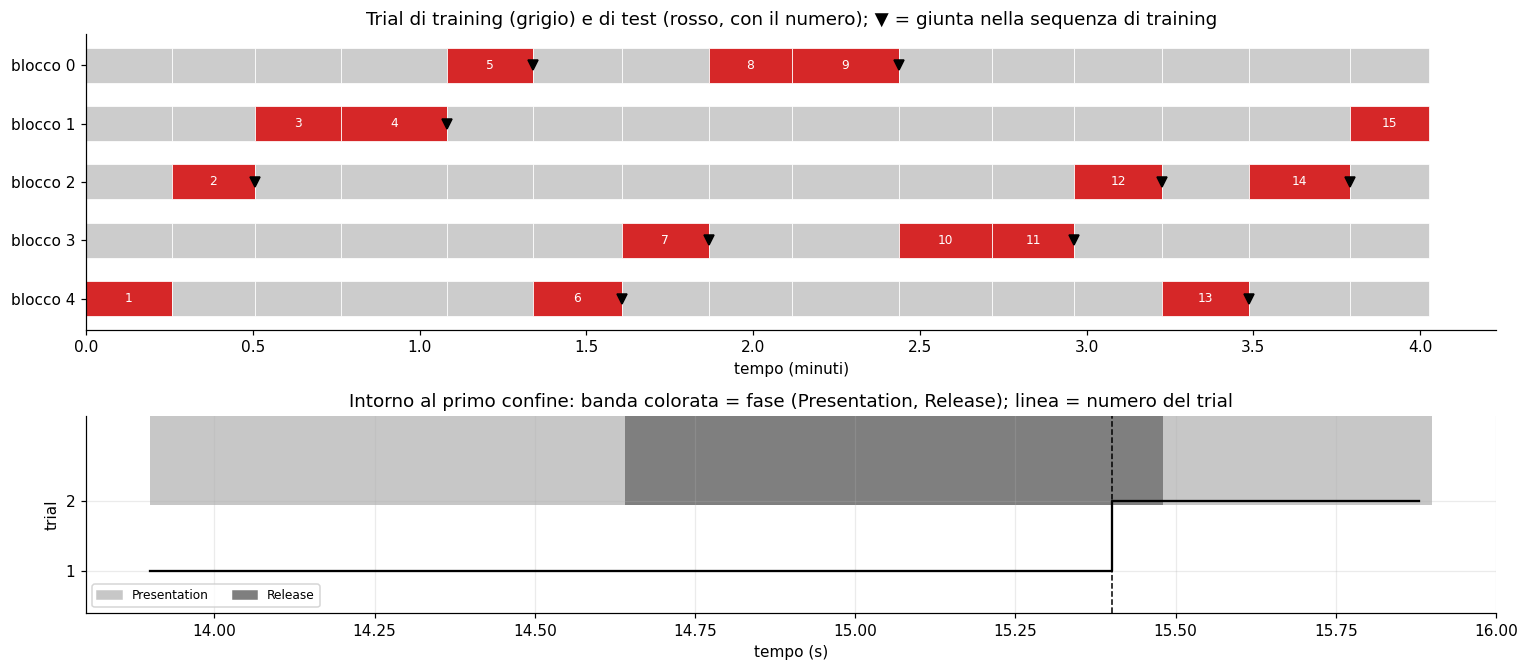

In [10]:
fig = plt.figure(figsize=(14, 6.2))
gs = fig.add_gridspec(2, 1, height_ratios=(1.5, 1))
ax = fig.add_subplot(gs[0])                                 # in alto: i 5 blocchi, trial per trial
t_min = np.arange(n_bins) * io.BIN_S / 60                   # tempo di ogni bin, in minuti
for k, tt in enumerate(TEST_TRIALS):
    for t_ in np.unique(trial):                             # un rettangolo per trial: grigio = training, rosso = test
        m = trial == t_
        ax.barh(k, t_min[m][-1] - t_min[m][0] + io.BIN_S / 60, left=t_min[m][0], height=0.6,
                color="C3" if t_ in tt else "0.8", edgecolor="white", lw=0.5)
        if t_ in tt:
            ax.text(t_min[m].mean(), k, str(t_), ha="center", va="center", fontsize=8, color="white")
    tb = TRAIN_BINS[k]
    for sp in np.flatnonzero(np.diff(tb) > 1) + 1:          # le giunte: dove la sequenza di training salta un trial di test
        ax.plot(t_min[tb[sp]], k, marker="v", color="k", ms=7)
ax.set(yticks=range(5), yticklabels=[f"blocco {k}" for k in range(5)], xlabel="tempo (minuti)",
       title="Trial di training (grigio) e di test (rosso, con il numero); ▼ = giunta nella sequenza di training")
ax.invert_yaxis(); ax.grid(False)

ax2 = fig.add_subplot(gs[1])                                # in basso: ingrandimento intorno al primo confine
a0 = starts[0]
win_b = np.arange(a0 - 75, a0 + 25)                         # 1.5 s prima e 0.5 s dopo il confine
for b_ in win_b:
    ax2.axvspan(b_ * io.BIN_S, (b_ + 1) * io.BIN_S, ymin=0.55, ymax=1, color=io.PHASE_COLORS.get(phase[b_], "white"), lw=0)
ax2.step(win_b * io.BIN_S, trial[win_b], where="post", color="k", lw=1.5)  # il numero del trial
ax2.axvline(a0 * io.BIN_S, color="k", ls="--", lw=1)
ax2.set(ylim=(trial[a0] - 1.6, trial[a0] + 1.2), yticks=[trial[a0] - 1, trial[a0]], xlabel="tempo (s)", ylabel="trial",
        title=f"Intorno al primo confine: banda colorata = fase ({', '.join(sorted(set(phase[win_b]) - {''}))}); linea = numero del trial")
handles = [plt.Rectangle((0, 0), 1, 1, color=io.PHASE_COLORS[p]) for p in sorted(set(phase[win_b]) - {""})]
ax2.legend(handles, sorted(set(phase[win_b]) - {""}), loc="lower left", fontsize=8, ncol=3)
fig.tight_layout(); fig.savefig(FIGS / "04_folds.png", bbox_inches="tight"); plt.show()

**Lettura.**

- Il confine tra due trial cade **sempre** dentro `Release`, da 1 a 4 bin (20-80 ms) prima della
  sua fine: nel file, ogni trial comincia con la coda del `Release` precedente (figura in basso).
- **6 punti su 1106** appartengono a un `Release` cominciato nel trial precedente. Se uno dei due
  trial è nel test e l'altro nel training, quella ripetizione di `Release` è divisa tra training e
  test. **27 punti** (tutti di `Release`) sono abbastanza vicini a un confine perché lo smoothing
  mescoli i conteggi dei due trial.
- È poco (al massimo il 2.4% dei punti) e valeva identico nel 03, che usava gli stessi blocchi:
  non cambia il confronto. Lo lasciamo così per non cambiare il metro comune. Una correzione
  possibile sarebbe spostare il confine alla fine di `Release`; non l'abbiamo fatta.
- Per CEBRA non si aggiunge niente: i trial di test si proiettano da soli, quindi la finestra della
  rete non li collega mai ai trial di training.

In [11]:
# REPLICA: solo le definizioni della cella tolta 21
from scipy.ndimage import gaussian_filter1d, uniform_filter1d

T_SYN, N_CH, NOISE = 10_000, 30, 2.0

In [12]:
# REPLICA: solo le definizioni della cella tolta 24
DELTA_SYN = 10

ref0 = 2_000

### 2.3 · Come alleniamo CEBRA in questo notebook

Tre accorgimenti, uguali per tutti gli allenamenti del notebook:

- **Un processo separato.** Le reti di CEBRA usano la libreria `torch`, che porta con sé una sua
  copia di OpenMP, il sistema che divide i calcoli tra i core; scikit-learn ne ha un'altra. Due
  copie nello stesso processo possono bloccarlo, come era successo con UMAP nel 03. Per questo
  ogni allenamento gira in un **processo a parte** (`ProcessPoolExecutor`), e il notebook non
  importa mai `torch`. Il codice dell'allenamento resta scritto qui sotto: viene solo eseguito
  altrove. (Il processo separato contiene comunque tutte e due le copie, perché CEBRA importa a sua
  volta scikit-learn; ma lì lavora solo `torch`.)
- **Due allenamenti alla volta, sulla GPU del Mac** (MPS). Misurato prima di cominciare, su dati finti della stessa
  forma: circa 10 volte più veloce della CPU; due allenamenti insieme vanno ciascuno alla stessa velocità di uno solo.
- **Il seme fissato davvero.** CEBRA 0.6.0 ignora il seme che gli diamo: lo vediamo, e lo
  correggiamo, al §2.7.

**I parametri** sono quelli degli esempi ufficiali di CEBRA per i dati di ippocampo: rete
`offset10-model` (finestra di 10 bin), gruppi da 512 riferimenti, passo di apprendimento 3·10⁻⁴,
τ = 1, Δ = 10 bin, distanza coseno, mappa a 3 dimensioni. Al §3 li confrontiamo con quelli
riportati nell'articolo. Qui facciamo 5000 iterazioni.

In [13]:
from joblib.externals.loky import ProcessPoolExecutor      # un gruppo di processi separati, solo per CEBRA (diverso da quello usato da joblib per UMAP)

POOL = ProcessPoolExecutor(max_workers=2)                   # due allenamenti alla volta
CEBRA_STD = dict(model_architecture="offset10-model",       # rete convoluzionale con una finestra di 10 bin (5 prima, 5 dopo)
                 batch_size=512,                            # riferimenti per ogni passo (e altrettanti negativi)
                 learning_rate=3e-4,                        # quanto si correggono i pesi della rete a ogni passo
                 temperature=1.0,                           # τ della funzione di costo
                 time_offsets=10,                           # Δ: il positivo è 10 bin (200 ms) dopo il riferimento
                 distance="cosine",                         # somiglianza = coseno; i punti stanno su una sfera
                 output_dimension=3,                        # dimensioni della mappa
                 max_iterations=5000)                       # passi di allenamento (per i dati veri si decide al §3)

def cebra_fit(X_train, X_apply, cfg, seed, fix_seed=True, monitor=None, every=None, model_path=None):
    """Allena CEBRA-Time su X_train; restituisce la mappa di ogni array in X_apply, la funzione di costo
    a ogni passo e la durata. Gira in un processo separato (vedi sopra).
    Dal §3: monitor(passo, solver) viene chiamato ogni `every` passi; model_path = dove salvare il modello."""
    import time                                             # per misurare la durata
    import numpy as np                                      # array
    import torch                                            # la libreria delle reti neurali usata da CEBRA
    import cebra                                            # CEBRA
    import cebra.distributions.base as cdb                  # la classe che crea i generatori di numeri casuali di CEBRA (§2.7)
    torch.set_num_threads(1)                                # i calcoli pesanti sono sulla GPU: un solo thread di CPU, meno OpenMP in azione
    if not hasattr(cdb.HasGenerator, "orig_init"):          # la correzione del seme (§2.7), installata una volta per processo
        cdb.HasGenerator.orig_init = cdb.HasGenerator.__init__  # il metodo originale, che sceglie un seme a caso
        def seeded_init(self, device, seed):                # il metodo corretto
            cdb.HasGenerator.orig_init(self, device=device, seed=seed)  # fa tutto quello che faceva prima...
            if cdb.HasGenerator.fixed_seed is not None:     # ...poi, se abbiamo fissato un seme, sostituisce il generatore
                self._seed = cdb.HasGenerator.fixed_seed * 1000 + cdb.HasGenerator.counter  # un seme diverso per ogni generatore, ma sempre lo stesso
                cdb.HasGenerator.counter += 1               # il prossimo generatore avrà il seme successivo
                self._generator = torch.Generator(device=self.device).manual_seed(self._seed)
        cdb.HasGenerator.__init__ = seeded_init
    cdb.HasGenerator.fixed_seed = seed if fix_seed else None  # fix_seed=False: la libreria si comporta come in origine
    cdb.HasGenerator.counter = 0                            # i generatori di questo allenamento si numerano da 0
    torch.manual_seed(seed); np.random.seed(seed)           # semi dei pesi iniziali della rete e di numpy
    device = "mps" if torch.backends.mps.is_available() else "cpu"  # la GPU del Mac, se c'è
    model = cebra.CEBRA(**cfg, device=device, verbose=False)  # il modello con i parametri scelti
    t0 = time.time()
    if monitor is None:
        model.fit(X_train)                                  # l'allenamento: senza etichette, quindi CEBRA-Time
    else:
        model.fit(X_train, callback=monitor, callback_frequency=every)  # lo stesso, chiamando monitor(passo, solver) ogni `every` passi (§3)
        monitor(cfg["max_iterations"], model.solver_)       # e un'ultima volta alla fine
    seconds = time.time() - t0
    if model_path is not None:
        model.save(str(model_path))                         # il modello allenato, su disco (§3.1)
    out = {"maps": [model.transform(x) for x in X_apply],   # ogni sequenza proiettata da sola (bordi: si ripete il primo/ultimo bin)
           "loss": np.asarray(model.state_dict_["loss"]),   # la funzione di costo a ogni passo dell'allenamento
           "seconds": seconds, "device": device}
    if monitor is not None:
        out["monitor"] = monitor.history                    # le misure raccolte durante l'allenamento (§3)
    return out

def run_cebra(jobs, fn=None):                               # esegue una lista di allenamenti (dizionari di argomenti), due alla volta
    fn = cebra_fit if fn is None else fn                    # la funzione di allenamento (dal §6 anche quella con le etichette)
    futures = [POOL.submit(fn, **j) for j in jobs]          # li manda tutti in coda...
    return [f.result() for f in futures]                    # ...e aspetta i risultati, nello stesso ordine

In [14]:
# REPLICA: solo le definizioni della cella tolta 28
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import r2_score

def r2_uv(E_tr, E_te):                                      # R² di u e v stimati con 10 vicini nella mappa (training -> test)
    pred = KNeighborsRegressor(n_neighbors=10).fit(E_tr, UV[:N_TR]).predict(E_te)
    return {"R² di u (lunghezza)": r2_score(UV[N_TR:, 0], pred[:, 0]), "R² di v (larghezza)": r2_score(UV[N_TR:, 1], pred[:, 1])}

In [15]:
# REPLICA: solo le definizioni della cella tolta 31
N_B, TAU = 512, 1.0

def logsumexp(a, axis=1):                                   # log Σ exp(a), calcolato senza superare i limiti dei numeri (si toglie il massimo)
    m = a.max(axis=axis, keepdims=True)
    return (m + np.log(np.exp(a - m).sum(axis=axis, keepdims=True))).squeeze(axis)

def infonce_library(ref_e, pos_e, neg_e, tau):              # la funzione della libreria (gira nel processo separato)
    import torch, cebra
    crit = cebra.models.criterions.FixedCosineInfoNCE(temperature=tau)
    loss, align, uniform = crit(torch.from_numpy(ref_e), torch.from_numpy(pos_e), torch.from_numpy(neg_e))
    return float(loss), float(align), float(uniform)

def bits(L, n=N_B):                                         # goodness of fit: quanto si scende sotto il livello del caso, in bit
    return (np.log(n) - L) * np.log2(np.e)

In [16]:
# REPLICA: solo le definizioni della cella tolta 33
rows_t = []

**Lettura.**

- **Senza la correzione, lo stesso seme dà mappe diverse**: un punto si sposta di qualche decimo,
  su una sfera di raggio 1, e anche la funzione di costo finale è diversa. I numeri esatti cambiano
  a ogni esecuzione del notebook (nelle esecuzioni fatte finora la differenza massima è andata da
  0.13 a 0.74), ed è proprio il problema.
- **Con la correzione i due allenamenti sono identici**, bit per bit: stessa mappa e stessa funzione
  di costo a ogni passo.
- **Verificato anche sul notebook intero**: eseguendolo due volte di seguito, tutti i risultati di
  CEBRA ottenuti con la correzione (R² del §2.4, funzione di costo, InfoNCE del §2.5) sono
  identici; cambia solo l'esempio senza correzione qui sopra.
- Da qui **tutti gli allenamenti usano la correzione**. Un risultato si può quindi rifare identico
  su questo computer con queste versioni (cebra 0.6.0, torch 2.7.1, GPU del Mac). Su un'altra
  macchina o con altre versioni non è garantito: per questo, dal §3, i modelli allenati si salvano
  su disco.
- La correzione **non** toglie la dipendenza dal caso: con semi diversi le mappe restano diverse.
  Quanto contino lo misuriamo con 5 semi.

## 3 · CEBRA-Time sui dati veri: un primo allenamento

Un allenamento principale, più alcuni controlli, per rispondere a due domande prima di misurare
qualunque cosa:

1. **Quante iterazioni servono?** Lo decidiamo con dei trial di **validazione**, mai con quelli di
   test (§3.2).
2. **Che aspetto ha la mappa?** (§3.3)

### I parametri, e da dove vengono

Li abbiamo controllati nell'articolo (Schneider, Lee & Mathis 2023, testo completo su PubMed
Central, PMC10172131):

| parametro | valore qui | che cosa dice l'articolo |
|---|---|---|
| rete | `offset10-model`: finestra di 10 bin (200 ms), **centrata** (100 ms prima e 100 dopo) | Methods, *CEBRA model parameters used*: `offset10-model` per i dati neurali di ippocampo di ratto, S1 di primate e Allen (2 fotoni) |
| Δ (`time_offsets`) | 10 bin (200 ms) | stessa sezione: `time_offsets=10` per gli stessi dati (lì con bin da 25 ms nell'ippocampo, quindi 250 ms) |
| gruppo (`batch_size`) | 512 | stessa sezione: `batch_size=512` |
| temperatura τ | 1 | Extended Data Fig. 3 (ippocampo): τ = 1 per CEBRA-Behaviour, **τ = 2.25 per CEBRA-Time**. Teniamo 1, il valore predefinito della libreria, per usare la stessa τ anche con CEBRA-Behavior al §6; 2.25 è tra le prove del §7 |
| passo di apprendimento | 3·10⁻⁴ | valore predefinito della libreria; nelle parti dell'articolo che abbiamo letto non è riportato per questi dati |
| iterazioni | **da decidere qui** | Extended Data Fig. 3 (ippocampo): 10 000 per CEBRA-Behaviour, 4000 per CEBRA-Time. Nei Methods il numero di passi è l'unico parametro **non** scelto con la validazione |
| dimensioni | 3 | Extended Data Fig. 3: *"latent dimension three (the minimum)"* |
| distanza | coseno | Methods: prodotto scalare tra vettori normalizzati |
| ottimizzatore | Adam | valore predefinito della libreria; l'articolo non lo nomina nelle parti lette |

**La finestra centrata usa 100 ms di futuro.** Per analizzare i dati va bene; un'interfaccia
cervello-computer in tempo reale non potrebbe farlo.

### 3.1 · Salvare i modelli su disco

Dal §4 servono molti allenamenti (5 blocchi × 5 semi per ogni configurazione). Ogni modello
allenato si salva su disco, e la volta successiva si rilegge invece di riallenarlo, come un piatto
già cucinato messo in freezer:

- il **nome del file** è un'impronta (*hash*) di tutto ciò che determina il risultato: il codice di
  `cebra_fit`, i parametri, il seme, e i dati (training, sequenze da proiettare, trial di
  validazione). Se cambia anche un solo numero dei dati, cambia il nome, e il modello si riallena;
- si salvano il modello (`.pt`, per poterlo riusare) e i risultati (`.npz`: mappe, funzione di
  costo, misure di validazione, durata);
- la cartella è **fuori dal Desktop** (`~/tesi_h1_work/cache_04`): il Desktop è sincronizzato con
  iCloud, che può togliere i file dal disco;
- `RETRAIN = True` rifà tutti gli allenamenti da capo. Con la correzione del seme (§2.7) devono
  dare gli stessi risultati, almeno su questo computer e con queste versioni.

In [17]:
import hashlib, inspect, json                               # impronte dei dati, testo del codice, salvataggio delle misure

CACHE = (REP / "cache_prova") if SMOKE else Path.home() / "tesi_h1_work" / "cache_04"  # REPLICA: in prova, cache a parte           # dove si salvano i modelli: fuori dal Desktop (iCloud)
CACHE.mkdir(parents=True, exist_ok=True)
RETRAIN = False                                             # True = rifà tutti gli allenamenti invece di rileggerli

def job_key(job, fn=None):                                  # impronta di un allenamento: cambia se cambia qualunque cosa che lo determina
    h = hashlib.sha1()
    for f in (cebra_fit, ValMonitor.__init__, ValMonitor.__call__, ValMonitor.infonce):
        h.update(inspect.getsource(f).encode())             # il codice dell'allenamento e delle misure
    if fn is not None and fn is not cebra_fit:
        h.update(inspect.getsource(fn).encode())            # dal §6: anche il codice della funzione con le etichette
    h.update(json.dumps({k: job.get(k) for k in ("cfg", "seed", "fix_seed", "every")},
                        sort_keys=True, default=str).encode())  # parametri, seme, frequenza delle misure
    arrays = [job["X_train"], *job["X_apply"]]              # i dati...
    if job.get("monitor") is not None:
        h.update(job["monitor"].key.encode())               # ...le impostazioni delle misure di validazione...
        arrays += [s_ for seqs in job["monitor"].sets.values() for s_ in seqs]  # ...e i loro trial
    if job.get("y_train") is not None:
        arrays.append(job["y_train"])                       # dal §6: le etichette...
    for name, (Xv, yv) in sorted((job.get("val") or {}).items()):
        h.update(name.encode()); arrays += [Xv, yv]         # ...e i trial di validazione con le loro etichette
    for a in arrays:
        h.update(np.ascontiguousarray(a).tobytes())         # ogni numero dei dati entra nell'impronta
    return h.hexdigest()[:16]

def run_cebra_cached(jobs, fn=None):                        # come run_cebra (§2.3), ma rilegge dal disco gli allenamenti già fatti
    keys = [job_key(j, fn) for j in jobs]
    todo = [i for i, k in enumerate(keys) if RETRAIN or not (CACHE / f"{k}.npz").exists()]  # quelli da fare davvero
    fresh = run_cebra([dict(jobs[i], model_path=CACHE / f"{keys[i]}.pt") for i in todo], fn)  # due alla volta, nel processo separato
    for i, r in zip(todo, fresh):                           # i risultati nuovi si salvano subito
        np.savez(CACHE / f"{keys[i]}.npz", loss=r["loss"], seconds=r["seconds"], device=r["device"],
                 monitor=json.dumps(r.get("monitor")), extra=json.dumps(r.get("extra")),
                 **{f"map_{j}": m for j, m in enumerate(r["maps"])})
    out = []
    for k in keys:                                          # tutti i risultati, nell'ordine dei lavori, letti dal disco
        z = np.load(CACHE / f"{k}.npz")
        out.append({"maps": [z[f"map_{j}"] for j in range(sum(n.startswith("map_") for n in z.files))],
                    "loss": z["loss"], "seconds": float(z["seconds"]), "device": str(z["device"]),
                    "monitor": json.loads(str(z["monitor"])), "key": k,
                    "extra": json.loads(str(z["extra"])) if "extra" in z.files else None})  # misure in più (dal §6)
    print(f"Allenamenti: {len(todo)} eseguiti ora, {len(jobs) - len(todo)} riletti dal disco")
    return out

In [18]:
K0 = 0                                                      # il blocco usato in questa sezione
VAL_TRIALS, VAL_TRIALS_B, CHECK_TRIALS = (12, 15), (6, 7), (4, 5)  # due coppie di trial di validazione e una di training su cui si misura (uno pari e uno dispari)
TRIALS = np.unique(trial)                                   # i 15 trial
fit_trials = [t for t in TRIALS if t not in TEST_TRIALS[K0] and t not in VAL_TRIALS]      # i 10 trial su cui CEBRA si allena (validazione 12, 15)
fit_trials_b = [t for t in TRIALS if t not in TEST_TRIALS[K0] and t not in VAL_TRIALS_B]  # i 10 trial su cui CEBRA si allena (validazione 6, 7)

def pca_seqs(fit_tr):                                       # PCA a 25 stimata sui bin di movimento dei soli trial fit_tr
    p_ = PCA(K_PCA).fit(Z[bins_all[np.isin(trial[bins_all], fit_tr)]])
    X_ = p_.transform(Z)                                    # tutta la sessione sulle sue 25 direzioni
    return p_, X_, {t: X_[trial == t].astype(np.float32) for t in TRIALS}  # e ogni trial separato, nel formato delle reti

def var_kept(p_, Xv):                                       # frazione (%) della varianza di Xv che sta nelle 25 direzioni della PCA p_
    Xc = Xv - p_.mean_
    return ((Xc @ p_.components_.T) ** 2).sum() / (Xc ** 2).sum() * 100

PCA_A, XA, SEQ_A = pca_seqs(fit_trials)                     # la PCA per la validazione con i trial 12 e 15
PCA_B, XB, SEQ_B = pca_seqs(fit_trials_b)                   # la PCA per la validazione con i trial 6 e 7

def mov(trs):                                               # i bin di movimento di alcuni trial
    return Z[bins_all[np.isin(trial[bins_all], trs)]]

display(pd.DataFrame({str(vt): {"PCA del §1.3 (12 trial: li ha visti)": var_kept(PCA_F[K0], mov(vt)),
                                "PCA sui soli 10 trial di allenamento": var_kept(p_, mov(vt))}
                      for vt, p_ in ((VAL_TRIALS, PCA_A), (VAL_TRIALS_B, PCA_B))}).T.rename_axis("trial di validazione").round(1))
print(f"Per confronto: sui 10 trial su cui è stimata, la PCA tiene il {var_kept(PCA_A, mov(fit_trials)):.1f}% della varianza; "
      f"sui trial di test del blocco 0, la PCA del §1.3 ne tiene il {var_kept(PCA_F[K0], mov(TEST_TRIALS[K0])):.1f}%")

,PCA del §1.3 (12 trial: li ha visti),PCA sui soli 10 trial di allenamento
trial di validazione,,
"(12, 15)",38.0,27.2
"(6, 7)",39.1,27.2


Per confronto: sui 10 trial su cui è stimata, la PCA tiene il 41.5% della varianza; sui trial di test del blocco 0, la PCA del §1.3 ne tiene il 27.9%


In [19]:
# REPLICA: solo le definizioni della cella tolta 42
class ValMonitor:
    """Durante l'allenamento misura InfoNCE (come al §2.5) su gruppi di istanti fissati in anticipo, in
    alcuni insiemi di trial proiettati uno alla volta. Viene eseguito nel processo separato."""

    def __init__(self, sets, delta=10, tau=1.0, n_batches=20, batch=512, seed=0):
        rng_m = np.random.default_rng(seed)                 # seme fisso: gli stessi gruppi a ogni misura
        self.sets, self.delta, self.tau, self.history = sets, delta, tau, []
        self.idx = {}                                       # per ogni insieme: 20 coppie (riferimenti, negativi)
        for name, seqs in sets.items():
            lens = [len(s_) for s_ in seqs]                 # lunghezza di ogni trial
            starts = np.cumsum([0] + lens[:-1])             # dove comincia ogni trial, una volta messi in fila
            refs = np.concatenate([a + np.arange(n - delta) for a, n in zip(starts, lens)])  # riferimenti con il positivo nello stesso trial
            self.idx[name] = [(rng_m.choice(refs, batch), rng_m.integers(0, sum(lens), batch)) for _ in range(n_batches)]
        self.key = f"ValMonitor({ {k: [len(s_) for s_ in v] for k, v in sets.items()} }, {delta}, {tau}, {n_batches}, {batch}, {seed})"

    def __call__(self, num_steps, solver):                  # chiamato da CEBRA ogni `every` passi
        import torch                                        # (siamo nel processo separato)
        was_training = solver.model.training                # proiettare mette la rete in modalità "uso": dopo la rimettiamo com'era
        row = {"passo": int(num_steps)}
        for name, seqs in self.sets.items():
            E = np.concatenate([solver.transform(torch.from_numpy(s_)).cpu().numpy() for s_ in seqs])  # ogni trial proiettato da solo
            row[name] = float(np.mean([self.infonce(E[r], E[r + self.delta], E[n]) for r, n in self.idx[name]]))
        solver.model.train(was_training)
        self.history.append(row)

    def infonce(self, ref, pos, neg):                       # la formula del §2.5 (coseno: i punti sono già sulla sfera)
        s_pos = (ref * pos).sum(1) / self.tau
        s_neg = ref @ neg.T / self.tau
        m = s_neg.max(1, keepdims=True)                     # si toglie il massimo per non far "esplodere" gli esponenziali
        return float(np.mean(-s_pos + m[:, 0] + np.log(np.exp(s_neg - m).sum(1))))

def rule98(v):                                              # la regola: primo passo con il 98% della discesa, arrotondato alle migliaia
    reached = v.values <= v.min() + 0.02 * (v.iloc[0] - v.min())  # dove la curva ha già fatto il 98% della discesa fino al minimo
    return int(np.ceil(v.index[np.argmax(reached)] / 1000) * 1000)

STEPS_SHOW = [0, 500, 1000, 1500, 2000, 3000, 4000, 6000, 8000, 10_000]

In [20]:
# REPLICA: solo le definizioni della cella tolta 47
def val_acc(E):                                             # metro comune, ma training = 10 trial, giudizio = 2 trial di validazione
    clf = KNeighborsClassifier(n_neighbors=K_NN).fit(E[ev_fit], phase[ev_fit])
    return balanced_accuracy_score(phase[ev_val], clf.predict(E[ev_val])) * 100

In [21]:
# REPLICA: solo le definizioni della cella tolta 49
def to_lonlat(E):                                           # longitudine e latitudine di ogni punto della sfera
    return np.arctan2(E[:, 1], E[:, 0]), np.arcsin(np.clip(E[:, 2], -1, 1))

In [22]:
N_ITER = 20 if SMOKE else 1000                            # REPLICA: il numero di passi del §3.2

## 4 · CEBRA-Time con il metro comune

Ora la misura vera, la stessa per tutti i metodi (§1.2): riconoscimento della fase con il
classificatore a 10 vicini, accuratezza bilanciata, gli stessi 1106 punti e gli stessi 5 blocchi
del 03. In ogni blocco **CEBRA si allena solo sui 12 trial di training** (il film del §1.4, con le
sue giunte) e i trial di test si proiettano uno alla volta. Parametri del §3, con **N_ITER = 1000**
passi. **5 semi** per ogni misura: media e minimo-massimo.

Tre questioni da risolvere prima di confrontare i numeri.

**1. La sfera: confronto a parità di coordinate libere.** Con la distanza coseno i punti di CEBRA
stanno su una sfera: 3 dimensioni sono 2 coordinate libere, come latitudine e longitudine. Il §2.4
ha mostrato che non è un dettaglio: sul foglio sintetico la sfera a 3 dimensioni perdeva una delle
due direzioni del foglio. La regola: **CEBRA a 3 dimensioni si confronta con PCA, Isomap e UMAP a
d = 2; CEBRA a 4 dimensioni (3 coordinate libere) con d = 3.** Alleniamo entrambe le versioni.

**2. Il classificatore sulla sfera.** L'articolo di CEBRA decodifica con un classificatore a vicini
che usa la distanza coseno (Methods, *Decoding analysis*); il nostro metro comune usa la distanza
in linea d'aria. Per punti sulla sfera è la stessa cosa: la distanza in linea d'aria al quadrato
vale 2 − 2 · coseno, quindi l'ordine dei vicini è identico. Lo verifichiamo.

**3. Un tetto alla pari.** Il tetto del 03 (il classificatore sulle 25 dimensioni di un solo bin)
vale per metodi che vedono un istante alla volta. CEBRA vede una **finestra di 200 ms** (5 bin
prima e 5 dopo, dal bin b − 5 al bin b + 4): può superare quel tetto in modo legittimo, solo perché
guarda di più. Costruiamo quindi due tetti con la stessa finestra, senza nessun apprendimento
(l'idea della media mobile del §2.4):

- **finestra in fila**: per ogni punto, i 10 bin della finestra uno accanto all'altro, 10 × 25 =
  250 numeri. Contiene tutto quello che vede CEBRA;
- **media sulla finestra**: la media dei 10 bin, 25 numeri.

Come per CEBRA, la finestra non esce dal trial: ai bordi si ripete il primo o l'ultimo bin. Va
ricordato che lo smoothing (σ = 50 ms) dà già a **tutti** i metodi una finestra di circa ±150 ms:
quella di CEBRA si aggiunge a questa.

### 4.1 · Il riconoscimento della fase

50 allenamenti (2 versioni × 5 semi × 5 blocchi) da 1000 passi, due alla volta: circa 5 minuti la
prima volta, poi si rileggono dal disco.

In [23]:
from itertools import product                               # tutte le combinazioni di più elenchi

CEBRA_T = dict(CEBRA_STD, max_iterations=N_ITER)            # CEBRA-Time con i parametri del §3
OUT_DIMS = (3, 4)                                           # 3 dimensioni = 2 coordinate libere; 4 dimensioni = 3 coordinate libere
COMBOS = list(product(OUT_DIMS, SEEDS, range(5)))           # (dimensioni, seme, blocco): 50 allenamenti
res4 = run_cebra_cached([dict(X_train=X25[k][TRAIN_BINS[k]].astype(np.float32),  # il film di training del blocco k (§1.4)
                              X_apply=[X25[k][trial == t].astype(np.float32) for t in TRIALS],  # tutti i 15 trial, uno alla volta
                              cfg=dict(CEBRA_T, output_dimension=od), seed=sd)
                         for od, sd, k in COMBOS])
MAPS4 = {c: np.concatenate(r["maps"]) for c, r in zip(COMBOS, res4)}  # per ogni combinazione, la mappa di tutti i 12233 bin
print(f"Durata media di un allenamento: {np.mean([r['seconds'] for r in res4]):.0f} s")

def decode_cebra(od, sd):                                   # metro comune: in ogni blocco, punti di training e di test dalla mappa di quel blocco
    inp = (bins, [(MAPS4[(od, sd, k)][bins[trn]], MAPS4[(od, sd, k)][bins[tst]], trn, tst)
                  for k, (trn, tst) in enumerate(FOLDS)])
    return decode_map(inp, emb_none)                        # la mappa è già fatta: il classificatore lavora direttamente sulle sue coordinate

for od in OUT_DIMS:
    ACC[f"CEBRA-Time, {od} dimensioni"] = [decode_cebra(od, sd) for sd in SEEDS]  # 5 semi

E0 = MAPS4[(3, 0, 0)]; trn0, tst0 = FOLDS[0]                # controllo della questione 2, sulla mappa a 3 dimensioni (seme 0, blocco 0)
pred_euc = KNeighborsClassifier(n_neighbors=K_NN).fit(E0[bins[trn0]], phase[bins[trn0]]).predict(E0[bins[tst0]])
pred_cos = KNeighborsClassifier(n_neighbors=K_NN, metric="cosine").fit(E0[bins[trn0]], phase[bins[trn0]]).predict(E0[bins[tst0]])
print(f"Distanza in linea d'aria contro coseno: previsioni uguali per il {np.mean(pred_euc == pred_cos) * 100:.1f}% dei punti di test")

Allenamenti: 0 eseguiti ora, 50 riletti dal disco
Durata media di un allenamento: 14 s
Distanza in linea d'aria contro coseno: previsioni uguali per il 100.0% dei punti di test


In [24]:
HALF = 5                                                    # la finestra di offset10-model: dal bin b − 5 al bin b + 4
first_last = {t: np.flatnonzero(trial == t)[[0, -1]] for t in TRIALS}  # primo e ultimo bin di ogni trial

def window_idx(b):                                          # per ogni punto, i 10 bin della sua finestra, senza uscire dal trial
    lo = np.array([first_last[trial[x]][0] for x in b])     # primo bin del trial di ogni punto
    hi = np.array([first_last[trial[x]][1] for x in b])     # ultimo bin
    return np.clip(b[:, None] + np.arange(-HALF, HALF)[None, :], lo[:, None], hi[:, None])  # ai bordi si ripete il bin del bordo

W_IDX = window_idx(bins)                                    # (1106 punti, 10 bin)
INP_STACK = (bins, [(X25[k][W_IDX[trn]].reshape(len(trn), -1), X25[k][W_IDX[tst]].reshape(len(tst), -1), trn, tst)
                    for k, (trn, tst) in enumerate(FOLDS)])  # i 10 bin in fila: 250 numeri per punto
INP_MEAN = (bins, [(X25[k][W_IDX[trn]].mean(1), X25[k][W_IDX[tst]].mean(1), trn, tst)
                   for k, (trn, tst) in enumerate(FOLDS)])   # la media dei 10 bin: 25 numeri per punto
ACC["tetto alla pari: finestra in fila (250 numeri)"] = decode_map(INP_STACK, emb_none)
ACC["tetto alla pari: media sulla finestra (25 numeri)"] = decode_map(INP_MEAN, emb_none)

ROWS_4 = [("PCA, d = 2", 2), ("Isomap, d = 2", 2), ("UMAP, d = 2", 2), ("CEBRA-Time, 3 dimensioni", 2),
          ("PCA, d = 3", 3), ("Isomap, d = 3", 3), ("UMAP, d = 3", 3), ("CEBRA-Time, 4 dimensioni", 3),
          ("tetto, 25 dimensioni", 25), ("tetto alla pari: media sulla finestra (25 numeri)", 25),
          ("tetto alla pari: finestra in fila (250 numeri)", 250)]
tab_4 = pd.DataFrame([{"metodo": name, "coordinate libere": free,
                       "fase riconosciuta (%)": mean_range(ACC[name]) if isinstance(ACC[name], list) else f"{ACC[name]:.1f}"}
                      for name, free in ROWS_4]).set_index("metodo")
display(tab_4)

,coordinate libere,fase riconosciuta (%)
metodo,,
"PCA, d = 2",2,23.8
"Isomap, d = 2",2,26.5
"UMAP, d = 2",2,35.5 (34.6-36.3)
"CEBRA-Time, 3 dimensioni",2,31.2 (29.6-33.0)
"PCA, d = 3",3,28.3
"Isomap, d = 3",3,30.2
"UMAP, d = 3",3,36.7 (35.9-37.4)
"CEBRA-Time, 4 dimensioni",3,34.9 (33.3-37.0)
"tetto, 25 dimensioni",25,36.9


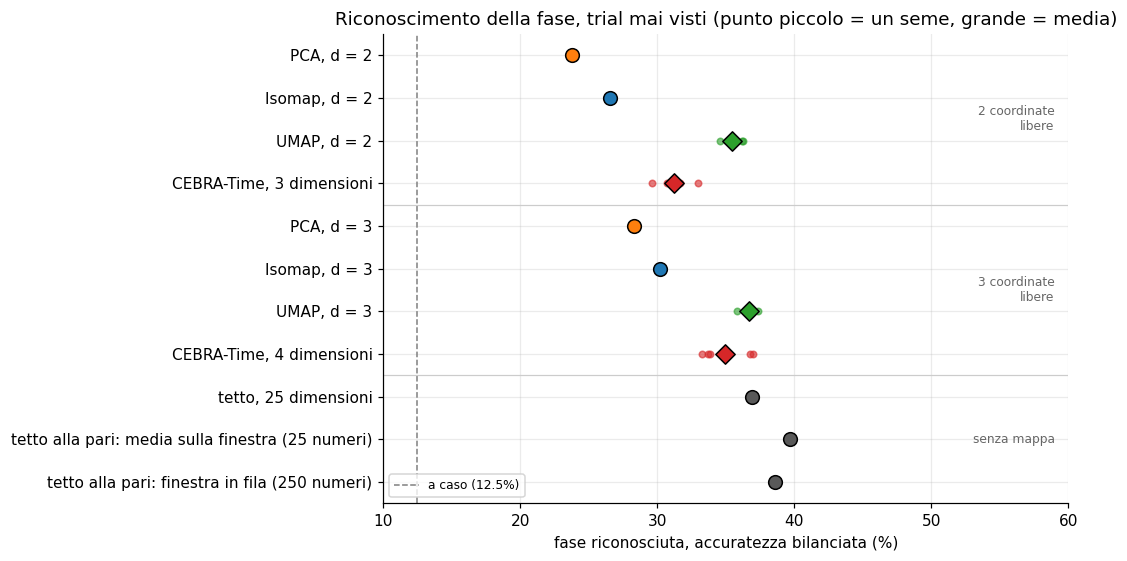

In [25]:
fig, ax = plt.subplots(figsize=(10, 5.2))
names_plot = [n for n, _ in ROWS_4][::-1]                   # dall'alto in basso nell'ordine della tabella
for yi, name in enumerate(names_plot):
    v = np.atleast_1d(ACC[name])                            # 1 valore, o 5 (uno per seme)
    col = "C3" if name.startswith("CEBRA") else ("C2" if name.startswith("UMAP") else
                                                 ("0.35" if name.startswith("tetto") else "C0" if name.startswith("Isomap") else "C1"))
    ax.scatter(v, np.full(len(v), yi), color=col, s=18, alpha=0.6, zorder=2)  # i semi, uno per punto
    ax.scatter(v.mean(), yi, color=col, s=80, marker="D" if len(v) > 1 else "o", edgecolor="k", zorder=3)  # la media
ax.axvline(12.5, color="0.5", ls="--", lw=1, label="a caso (12.5%)")
ax.axhline(2.5, color="0.8", lw=0.8); ax.axhline(6.5, color="0.8", lw=0.8)  # separa i tre gruppi
ax.set(yticks=range(len(names_plot)), yticklabels=names_plot, xlim=(10, 60), xlabel="fase riconosciuta, accuratezza bilanciata (%)",
       title="Riconoscimento della fase, trial mai visti (punto piccolo = un seme, grande = media)")
ax.text(59, 8.5, "2 coordinate\nlibere", ha="right", va="center", fontsize=8, color="0.4")
ax.text(59, 4.5, "3 coordinate\nlibere", ha="right", va="center", fontsize=8, color="0.4")
ax.text(59, 1, "senza mappa", ha="right", va="center", fontsize=8, color="0.4")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "04_phase_decoding.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Il classificatore sulla sfera** (questione 2): con la distanza coseno e con quella in linea
  d'aria le previsioni sono uguali per il 100% dei punti, come previsto.
- **Con 2 coordinate libere CEBRA-Time arriva al 37.7%** (35.3-40.6 tra i semi): molto meglio della
  PCA (26.0%) e di Isomap (31.8%), **peggio di UMAP** (41.2%, 40.4-42.3). Il seme migliore di CEBRA
  arriva appena al peggiore di UMAP.
- **Con 3 coordinate libere: 40.4%** (38.5-42.7), contro 42.6% di UMAP (41.9-43.2), 36.0% di
  Isomap e 32.4% della PCA. Ancora sotto UMAP in media; qui gli intervalli si sovrappongono.
- **La sfera costa**: passare da 3 a 4 dimensioni (da 2 a 3 coordinate libere) fa guadagnare 2.7
  punti, come nel foglio sintetico del §2.4.
- **CEBRA dipende dal seme più di UMAP**: 5 punti tra il seme migliore e il peggiore, contro 1-2.
- **I tetti alla pari.** Guardare 200 ms invece di un bin alza il tetto da 42.2% a **44.9%** (media
  sulla finestra) e a 43.9% (finestra in fila). La finestra quindi aggiunge un po' di
  informazione, 2-3 punti, ma CEBRA non la sfrutta: resta 4.5 punti sotto il suo tetto alla pari
  con 3 coordinate libere. La finestra in fila, che contiene più informazione, fa un po' peggio
  della media: con 250 numeri per punto il classificatore a vicini fatica a trovare i vicini giusti.

**In sintesi: su questa sessione, con il metro comune, CEBRA-Time non batte UMAP.** Fa meglio di
PCA e Isomap, ma non conserva in 2-3 coordinate tutta l'informazione sulle fasi che UMAP conserva,
e non usa quella in più della sua finestra di tempo. È un risultato valido, con due avvertenze:
i parametri di CEBRA sono quelli standard (solo il numero di passi è stato scelto sui nostri
dati), e al §7 ne proveremo altri; e non sappiamo ancora che cosa contenga la mappa oltre alla
catena del tempo (§5).

### 4.2 · Le traiettorie single-trial

La misura del 03 (§6.1 e §9.4), sulle 119 finestre da 1 s dall'inizio di ogni fase: **seghettatura**
(quanto la traiettoria salta da un bin all'altro: più bassa = meglio) e **consistenza** (quanto si
somigliano le ripetizioni della stessa fase: più alta = meglio).

- **Modelli stimati su tutti i 15 trial**, come Isomap e UMAP nel 03: le 5 mappe dei blocchi non si
  possono mescolare, perché ognuna ha il suo orientamento sulla sfera, e la consistenza
  confronterebbe ripetizioni proiettate in mappe diverse. Questa misura quindi **descrive** le
  mappe, non dice quanto generalizzano a trial nuovi (per quello c'è il §4.1). Input: i 25 PC
  stimati su tutti i trial, come nel 03. 5 semi per ogni versione, 1000 passi: circa 1 minuto.
- **Tutte le coordinate della mappa**: 3 per CEBRA a 3 dimensioni, 4 per CEBRA a 4 dimensioni; le
  prime 3 per PCA, Isomap e UMAP (03). Le due misure sono medie sulle dimensioni, quindi il numero
  di dimensioni non le avvantaggia.
- **Le due versioni del task.** Nel 03 (§9.2) abbiamo scoperto che il task alterna due versioni
  tra trial dispari e pari: le 15 ripetizioni di una fase non sono repliche. Calcoliamo quindi la
  consistenza anche **dentro** ciascuna versione (solo le ripetizioni dei trial dispari, solo
  quelle dei pari) e ne facciamo la media. È una correzione che nel 03 mancava; la applichiamo qui
  anche a PCA, Isomap e UMAP, ricalcolati con lo stesso codice del 03. La GPFA (02_new, §10.5) la
  citiamo dal 03 senza ricalcolarla: richiederebbe di ristimarla, e per lei la consistenza per
  versione non c'è.

In [26]:
windows = io.phase_windows(s, win_s=1.0, align="start")     # le 119 finestre da 1 s del 02 e del 03
WIN_TAG = np.array([w["tag"] for w in windows])             # la fase di ogni finestra
WIN_ODD = np.array([w["trial"] % 2 == 1 for w in windows])  # vero per le finestre dei trial dispari (una delle due versioni)

def roughness(trajs):                                       # seghettatura media (03, §6.1)
    return float(np.mean([(np.diff((T_ - T_.mean(0)) / (T_.std(0) + 1e-9), n=2, axis=0) ** 2).mean()
                          for T_ in trajs]))                # z-score di ogni dimensione, poi differenza seconda al quadrato

def consistency(trajs, keep=None):                          # correlazione media tra ripetizioni della stessa fase (03, §6.1); keep = quali finestre usare
    keep = np.ones(len(windows), bool) if keep is None else keep
    out = []
    for p in io.MOVEMENT_PHASES:
        R = np.stack([trajs[i] for i in np.flatnonzero((WIN_TAG == p) & keep)])  # (ripetizioni, 50 bin, dimensioni)
        out.append(np.mean([np.corrcoef(R[:, :, j])[np.triu_indices(len(R), 1)].mean() for j in range(R.shape[2])]))
    return float(np.mean(out))

def traj_stats(trajs):                                      # le misure di una lista di traiettorie
    odd, even = consistency(trajs, WIN_ODD), consistency(trajs, ~WIN_ODD)
    return {"seghettatura": roughness(trajs), "consistenza, tutte le ripetizioni": consistency(trajs),
            "consistenza, solo trial dispari": odd, "consistenza, solo trial pari": even,
            "consistenza per versione (media delle due)": (odd + even) / 2}

def cut(E):                                                 # dalla mappa di tutta la sessione, le 119 finestre
    return [E[w["start"]:w["stop"]] for w in windows]

pca_all = PCA(n_components=K_PCA).fit(Z[bins_all])          # la PCA a 25 su tutti i trial (03, §2)
Z25 = pca_all.transform(Z)                                  # tutta la sessione sulle 25 direzioni
X_all = Z25[bins]                                           # i 1106 punti (03, §2)
win_X = cut(Z25)                                            # le finestre nello spazio a 25 dimensioni
iso_all = Isomap(n_neighbors=K_NN, n_components=15).fit(X_all)  # Isomap come nel 03 (§4: 15 coordinate, ne usiamo 3)
TRAJ = {"PCA": [traj_stats([w_[:, :3] for w_ in cut(PCA(3).fit(X_all).transform(Z25))])],
        "Isomap": [traj_stats([iso_all.transform(x_)[:, :3] for x_ in win_X])],
        "UMAP": [traj_stats(np.split(UMAP(n_neighbors=K_NN, n_components=3, random_state=sd, n_jobs=1).fit(X_all)
                                     .transform(np.concatenate(win_X)), len(win_X))) for sd in SEEDS]}
res4t = run_cebra_cached([dict(X_train=Z25.astype(np.float32), X_apply=[Z25.astype(np.float32)],  # tutta la sessione, una sola sequenza
                               cfg=dict(CEBRA_T, output_dimension=od), seed=sd) for od in OUT_DIMS for sd in SEEDS])
MAPS4T = dict(zip(product(OUT_DIMS, SEEDS), [r["maps"][0] for r in res4t]))  # (dimensioni, seme) -> mappa di tutta la sessione
for od in OUT_DIMS:
    TRAJ[f"CEBRA-Time, {od} dimensioni"] = [traj_stats(cut(MAPS4T[(od, sd)])) for sd in SEEDS]

rows_t = {}
for name, runs in TRAJ.items():
    d_ = pd.DataFrame(runs)                                 # una riga per seme (una sola per PCA e Isomap)
    rows_t[name] = {c: (f"{d_[c].mean():.3f} ({d_[c].min():.3f}-{d_[c].max():.3f})" if len(d_) > 1 else f"{d_[c].iloc[0]:.3f}")
                    for c in d_.columns}
rows_t["GPFA (dal 03, §6.1, e dal 02_new, §10.5)"] = {"seghettatura": "0.011", "consistenza, tutte le ripetizioni": "0.11"}
tab_traj4 = pd.DataFrame(rows_t).T.fillna("non calcolata")
display(tab_traj4)
print("Nel 03, con un solo seme di UMAP: seghettatura PCA 0.013, Isomap 0.27, UMAP 0.59; consistenza 0.088, 0.095, 0.13")

Allenamenti: 0 eseguiti ora, 10 riletti dal disco


,seghettatura,"consistenza, tutte le ripetizioni","consistenza, solo trial dispari","consistenza, solo trial pari",consistenza per versione (media delle due)
PCA,0.011,0.113,0.121,0.136,0.129
Isomap,0.308,0.061,0.061,0.132,0.096
UMAP,0.517 (0.469-0.554),0.092 (0.078-0.108),0.098 (0.089-0.117),0.199 (0.179-0.227),0.149 (0.138-0.172)
"CEBRA-Time, 3 dimensioni",0.089 (0.082-0.093),0.075 (0.065-0.088),0.086 (0.065-0.108),0.098 (0.070-0.127),0.092 (0.086-0.096)
"CEBRA-Time, 4 dimensioni",0.077 (0.072-0.084),0.091 (0.086-0.097),0.101 (0.093-0.109),0.124 (0.109-0.153),0.112 (0.101-0.131)
"GPFA (dal 03, §6.1, e dal 02_new, §10.5)",0.011,0.11,non calcolata,non calcolata,non calcolata


Nel 03, con un solo seme di UMAP: seghettatura PCA 0.013, Isomap 0.27, UMAP 0.59; consistenza 0.088, 0.095, 0.13


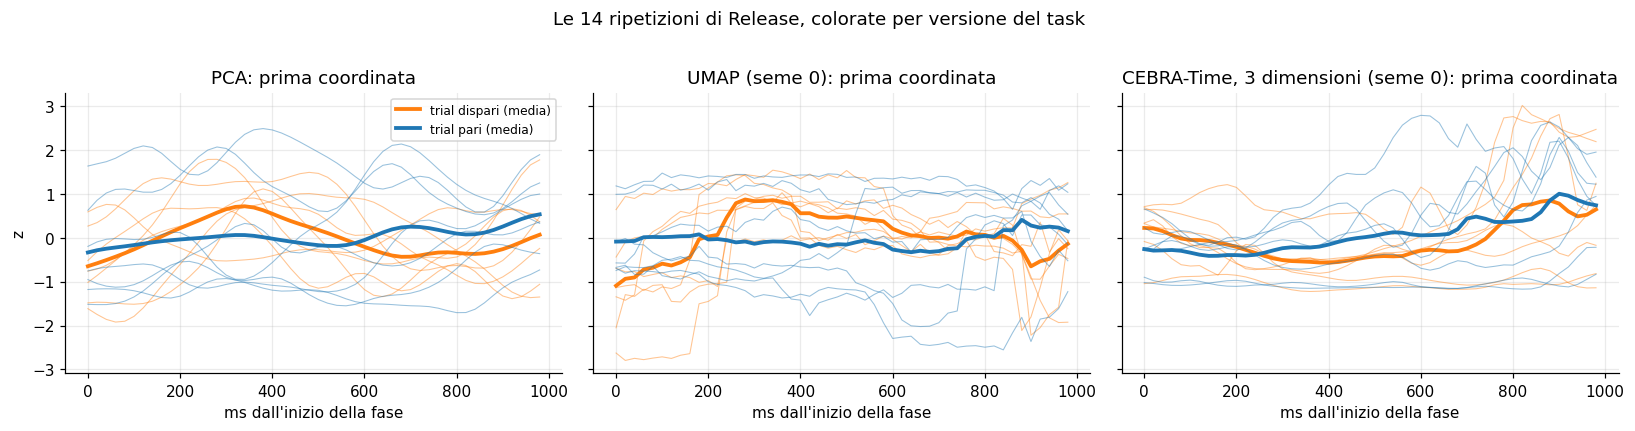

In [27]:
PH_SHOW = "Release"                                         # la fase più riproducibile nel 02 e nel 03
idx_ph = np.flatnonzero(WIN_TAG == PH_SHOW)                 # le sue ripetizioni
t_win = np.arange(50) * 20                                  # ms dall'inizio della fase
show = {"PCA": cut(PCA(3).fit(X_all).transform(Z25)),
        "UMAP (seme 0)": np.split(UMAP(n_neighbors=K_NN, n_components=3, random_state=0, n_jobs=1).fit(X_all)
                                  .transform(np.concatenate(win_X)), len(win_X)),
        "CEBRA-Time, 3 dimensioni (seme 0)": cut(MAPS4T[(3, 0)])}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a_, (name, tr_) in zip(ax, show.items()):
    R = np.stack([tr_[i][:, 0] for i in idx_ph])            # la prima coordinata di ogni ripetizione
    R = (R - R.mean()) / R.std()                            # stessa scala per tutti i metodi
    for odd, c, lab in ((True, "C1", "trial dispari"), (False, "C0", "trial pari")):
        sel = WIN_ODD[idx_ph] == odd
        for r_ in R[sel]:
            a_.plot(t_win, r_, color=c, lw=0.7, alpha=0.45)
        a_.plot(t_win, R[sel].mean(0), color=c, lw=2.5, label=f"{lab} (media)")  # media di ciascuna versione
    a_.set(title=f"{name}: prima coordinata", xlabel="ms dall'inizio della fase")
ax[0].set_ylabel("z"); ax[0].legend(fontsize=8)
fig.suptitle(f"Le {len(idx_ph)} ripetizioni di {PH_SHOW}, colorate per versione del task", y=1.02)
fig.tight_layout(); fig.savefig(FIGS / "04_trajectories.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **I numeri del 03 si ritrovano**: PCA 0.013 e 0.088, Isomap 0.275 e 0.095; UMAP con 5 semi 0.596
  (0.571-0.628) e 0.125 (0.110-0.134), in linea con il seme unico del 03 (0.59 e 0.13).
- **Le traiettorie di CEBRA sono lisce, ma non quanto quelle dei metodi lineari.** Seghettatura
  0.080 (3 dimensioni) e 0.074 (4 dimensioni): 7-8 volte meno di UMAP e 3-4 volte meno di Isomap,
  ma 6 volte più della PCA (0.013) e della GPFA (0.011). Il motivo è nel modo in cui sono fatte:
  CEBRA applica la stessa rete a finestre che si sovrappongono (due bin vicini condividono 9 dei 10
  bin di ingresso), mentre Isomap e UMAP collocano ogni punto guardando i suoi vicini, e saltano
  quando i vicini cambiano. La PCA è una semplice proiezione dei dati smussati.
- **Consistenza**: 0.089 per CEBRA a 3 dimensioni (come la PCA, 0.088) e 0.106 a 4 dimensioni
  (come la GPFA, 0.11), sotto UMAP (0.125). Tra i semi cambia molto (per esempio da 0.086 a 0.127
  a 4 dimensioni).
- **Le due versioni del task.** Per tutti i metodi la consistenza dentro una sola versione è più
  alta che mescolandole: PCA da 0.088 a 0.109, UMAP da 0.125 a 0.144, CEBRA a 4 dimensioni da
  0.106 a 0.122. Mescolare le versioni abbassava quindi la consistenza nel 02 e nel 03, come
  sospettato (03, §9.2). L'ordine dei metodi però non cambia. I trial pari sono più consistenti dei
  dispari con tutti i metodi (per esempio UMAP 0.187 contro 0.102): non sappiamo perché, e non
  l'abbiamo indagato.
- Nella figura, le ripetizioni di `Release` lungo la prima coordinata: lisce con la PCA, a salti con
  UMAP, lisce ma più piatte con CEBRA. La prima coordinata di CEBRA non è "la più importante" come
  nella PCA: sulla sfera l'orientamento è arbitrario, quindi la figura serve a vedere la
  seghettatura, non la forma.
- **Limiti**: queste mappe sono stimate su tutti i trial, quindi descrivono e non misurano la
  generalizzazione; con circa 7 ripetizioni per versione la consistenza per versione è rumorosa;
  per la GPFA non l'abbiamo calcolata.

## 5 · Controlli: che cosa c'è nella mappa di CEBRA-Time

Tre domande:

1. **Senza struttura legata al task, CEBRA trova comunque qualcosa?** Lo proviamo sul gemello a
   fasi casuali del 03 (§5.1).
2. **Quanto dipende dal seme?** Con la misura di consistenza tra allenamenti usata nell'articolo di
   CEBRA (§5.2).
3. **CEBRA-Time impara solo la catena del tempo?** È la domanda più importante, perché il suo gioco
   avvicina proprio istanti vicini nel tempo dello stesso trial (§5.3).

Tutti i controlli usano CEBRA a **3 dimensioni** (la sfera con 2 coordinate libere): è la
versione standard, e l'unica che si può disegnare. Al §4 le due versioni si comportavano in modo
simile (37.7% e 40.4%). Parametri del §3 (Δ = 10 bin, 1000 passi), salvo dove li cambiamo
apposta.

### 5.1 · Il gemello a fasi casuali

Il gemello del 03 (§5.2): stesse ampiezze di Fourier dei dati, fasi mescolate a caso (le stesse per
tutte le 25 dimensioni). Ha la stessa covarianza e la stessa velocità di variazione nel tempo,
quindi **la stessa catena del tempo**, ma nessun legame con le fasi del task. Lo costruiamo, per
ogni blocco, sui 25 PC di tutta la sessione (§1.3), e su di lui alleniamo CEBRA esattamente come al
§4. Le etichette di fase sono quelle vere, ma sul gemello non c'entrano nulla: **il riconoscimento
deve scendere al caso** (12.5%). Se non scendesse, vorrebbe dire che qualcosa passa dal training al
test per altre vie. Per confronto, lo stesso controllo con il classificatore sulle 25 dimensioni
del gemello.

5 gemelli (semi 0-4) × 5 blocchi, un seme di CEBRA per gemello: 25 allenamenti, circa 3 minuti.

In [28]:
def phase_randomize(Xt, seed):                              # gemello: stesse ampiezze di Fourier, fasi casuali uguali per tutte le colonne (03, §5.2)
    rng_ = np.random.default_rng(seed)
    F = np.fft.rfft(Xt - Xt.mean(0), axis=0)                # spettro di ogni colonna
    phases = np.exp(2j * np.pi * rng_.uniform(size=F.shape[0]))  # una fase casuale per ogni frequenza
    phases[0] = 1                                           # la componente costante non si tocca
    if len(Xt) % 2 == 0:
        phases[-1] = 1                                      # nemmeno quella alla frequenza massima
    return np.fft.irfft(F * phases[:, None], n=len(Xt), axis=0) + Xt.mean(0)

TWINS = {(k, sd): phase_randomize(X25[k], sd) for k in range(5) for sd in SEEDS}  # (blocco, seme del gemello) -> gemello di tutta la sessione
res_tw = run_cebra_cached([dict(X_train=TWINS[(k, sd)][TRAIN_BINS[k]].astype(np.float32),
                                X_apply=[TWINS[(k, sd)][trial == t].astype(np.float32) for t in TRIALS],
                                cfg=CEBRA_T, seed=sd) for sd in SEEDS for k in range(5)])
MAPS_TW = {(sd, k): np.concatenate(r["maps"]) for (sd, k), r in zip(product(SEEDS, range(5)), res_tw)}

def fold_inp(get):                                          # input del metro comune da una funzione blocco -> dati di tutti i bin
    return (bins, [(get(k)[bins[trn]], get(k)[bins[tst]], trn, tst) for k, (trn, tst) in enumerate(FOLDS)])

acc_tw = [decode_map(fold_inp(lambda k: MAPS_TW[(sd, k)]), emb_none) for sd in SEEDS]       # CEBRA sul gemello
acc_tw_raw = [decode_map(fold_inp(lambda k: TWINS[(k, sd)]), emb_none) for sd in SEEDS]     # classificatore sulle 25 dimensioni del gemello
display(pd.Series({"CEBRA-Time, 3 dimensioni, dati veri (§4)": mean_range(ACC["CEBRA-Time, 3 dimensioni"]),
                   "CEBRA-Time, 3 dimensioni, gemelli (5)": mean_range(acc_tw),
                   "nessuna mappa, 25 dimensioni, dati veri (§1.2)": f"{ACC['tetto, 25 dimensioni']:.1f}",
                   "nessuna mappa, 25 dimensioni, gemelli (5)": mean_range(acc_tw_raw),
                   "a caso": "12.5"}, name="fase riconosciuta (%)").to_frame())

Allenamenti: 0 eseguiti ora, 25 riletti dal disco


,fase riconosciuta (%)
"CEBRA-Time, 3 dimensioni, dati veri (§4)",31.2 (29.6-33.0)
"CEBRA-Time, 3 dimensioni, gemelli (5)",14.1 (12.7-16.3)
"nessuna mappa, 25 dimensioni, dati veri (§1.2)",36.9
"nessuna mappa, 25 dimensioni, gemelli (5)",13.0 (12.1-14.1)
a caso,12.5


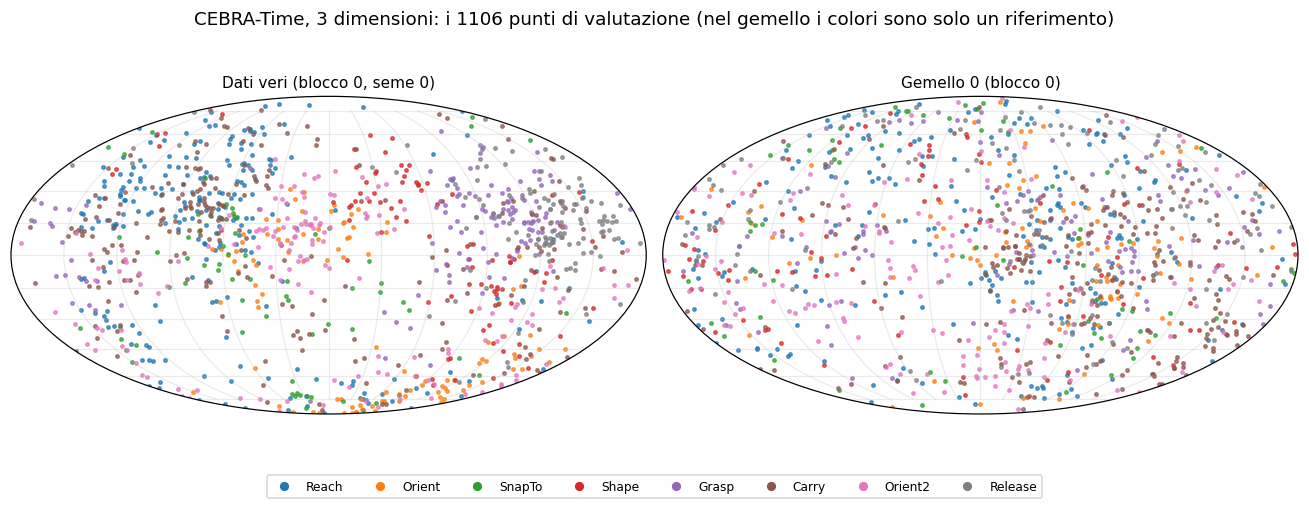

In [29]:
fig = plt.figure(figsize=(12, 4.4))
for j, (ttl, E) in enumerate([("Dati veri (blocco 0, seme 0)", MAPS4[(3, 0, 0)]), ("Gemello 0 (blocco 0)", MAPS_TW[(0, 0)])]):
    lon_, lat_ = to_lonlat(E)
    a_ = fig.add_subplot(1, 2, j + 1, projection="mollweide")
    for p in io.MOVEMENT_PHASES:                            # i punti di valutazione di tutti i trial, un colore per fase
        m = bins[phase[bins] == p]
        a_.scatter(lon_[m], lat_[m], s=5, alpha=0.7, color=io.PHASE_COLORS[p])
    a_.set_title(ttl, fontsize=10); a_.set_xticklabels([]); a_.set_yticklabels([])
handles = [plt.Line2D([], [], color=io.PHASE_COLORS[p], marker="o", ls="", ms=5, label=p) for p in io.MOVEMENT_PHASES]
fig.legend(handles=handles, ncol=8, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.02))
fig.suptitle("CEBRA-Time, 3 dimensioni: i 1106 punti di valutazione (nel gemello i colori sono solo un riferimento)", y=1.0)
fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(FIGS / "04_twin_maps.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Sui gemelli CEBRA-Time scende esattamente al caso**: 12.5% (10.7-13.9 tra i 5 gemelli), come
  il classificatore sulle 25 dimensioni del gemello (12.8%). Niente passa dal training al test per
  altre vie: né attraverso le giunte (§1.5), né attraverso lo smoothing ai confini dei trial, né
  attraverso la catena del tempo, che il gemello conserva. Il 37.7% dei dati veri viene dal legame
  tra attività e task.
- **Le mappe**: sui dati veri le fasi occupano zone diverse della sfera (quelle della mano da una
  parte, quelle del braccio dall'altra, come al §3.3); sul gemello i punti coprono tutta la sfera
  e i colori sono mescolati. Covarianza e catena del tempo da sole non bastano a produrre la
  struttura, come per UMAP nel 03 (§9.2).
- **Limite**: il gemello è gaussiano (03, §5.2), quindi il controllo esclude una nuvola lineare e
  gaussiana con la stessa catena del tempo, non ogni possibile artefatto.

### 5.2 · Quanto conta il seme: la consistenza tra allenamenti

Al §4 i 5 semi di CEBRA davano accuratezze lontane fino a 5 punti. Ma danno anche **mappe
diverse**? L'articolo di CEBRA misura la *consistenza* tra due mappe degli stessi punti così: si
cerca la trasformazione lineare (rotazione, allungamento, spostamento) che porta la prima mappa
il più vicino possibile alla seconda, e si misura l'R², cioè quanta parte della seconda viene
spiegata. R² = 1 vuol dire che le due mappe sono la stessa a meno di una trasformazione lineare;
l'orientamento arbitrario della sfera quindi non conta. Si fa per ogni coppia ordinata di
allenamenti (con 5 semi, 20 coppie).

La rifacciamo a mano (`LinearRegression` di scikit-learn, come nella libreria) e la confrontiamo
con `cebra.sklearn.metrics.consistency_score`, sui 1106 punti di valutazione:

- le mappe dei **modelli stimati su tutti i trial** del §4.2 (5 semi), CEBRA a 3 e 4 dimensioni;
- **UMAP** con 2 e 3 dimensioni, stimato sugli stessi punti con 5 semi;
- le mappe dei **modelli di ciascun blocco** del §4.1 (stimati su 12 trial), media sui blocchi.

PCA e Isomap non dipendono dal caso: la loro consistenza tra allenamenti vale 1 per costruzione.

In [30]:
from sklearn.linear_model import LinearRegression           # regressione lineare, come nella funzione della libreria

def umap_fit(Xp, d, seed=0):                                # UMAP stimato su tutti i punti dati (03, §9.2)
    return UMAP(n_neighbors=K_NN, n_components=d, random_state=seed, n_jobs=1).fit_transform(Xp)

def run_consistency(maps):                                  # R² della regressione lineare da ogni mappa a ogni altra (coppie ordinate)
    return np.array([LinearRegression().fit(A, B).score(A, B) for i, A in enumerate(maps)
                     for j, B in enumerate(maps) if i != j])

def consistency_library(maps):                              # la funzione della libreria (nel processo separato, perché importa torch)
    import cebra
    scores, pairs, ids = cebra.sklearn.metrics.consistency_score(maps, between="runs")
    return np.asarray(scores)

cons_maps = {f"CEBRA-Time, {od} dimensioni (stimato su tutti i trial)": [MAPS4T[(od, sd)][bins] for sd in SEEDS]
             for od in OUT_DIMS}
for d in (2, 3):                                            # UMAP sugli stessi 1106 punti, 5 semi
    cons_maps[f"UMAP, d = {d}"] = Parallel(n_jobs=5)(delayed(umap_fit)(X_all, d, sd) for sd in SEEDS)
cons = {name: run_consistency(m_) for name, m_ in cons_maps.items()}
cons["CEBRA-Time, 3 dimensioni (modelli dei blocchi, media sui 5 blocchi)"] = np.array(
    [run_consistency([MAPS4[(3, sd, k)][bins] for sd in SEEDS]).mean() for k in range(5)])  # una media per blocco
lib = POOL.submit(consistency_library, [m_.astype(np.float32) for m_ in cons_maps["CEBRA-Time, 3 dimensioni (stimato su tutti i trial)"]]).result()
mine = run_consistency([m_.astype(np.float32) for m_ in cons_maps["CEBRA-Time, 3 dimensioni (stimato su tutti i trial)"]])
print(f"A mano contro libreria (CEBRA a 3 dimensioni, 20 coppie): differenza massima {np.abs(np.sort(lib) - np.sort(mine)).max():.1e}")
display(pd.Series({name: mean_range(v * 100) for name, v in cons.items()} | {"PCA, Isomap": "100 (per costruzione)"},
                  name="consistenza tra allenamenti: R² (%), media (min-max)").to_frame())

A mano contro libreria (CEBRA a 3 dimensioni, 20 coppie): differenza massima 0.0e+00


,"consistenza tra allenamenti: R² (%), media (min-max)"
"CEBRA-Time, 3 dimensioni (stimato su tutti i trial)",64.5 (51.3-81.5)
"CEBRA-Time, 4 dimensioni (stimato su tutti i trial)",75.2 (64.6-85.2)
"UMAP, d = 2",75.4 (43.1-98.5)
"UMAP, d = 3",94.6 (86.3-99.0)
"CEBRA-Time, 3 dimensioni (modelli dei blocchi, media sui 5 blocchi)",58.1 (51.1-68.1)
"PCA, Isomap",100 (per costruzione)


**Lettura.**

- **Il calcolo a mano coincide con la libreria** (differenza 0 sulle 20 coppie).
- **Le mappe di CEBRA cambiano molto più di quelle di UMAP da un seme all'altro**: R² 63% con 3
  dimensioni e 75% con 4, contro 87% e 93% di UMAP. Alcune coppie di semi di CEBRA sono lontane
  (minimo 47% a 3 dimensioni): stessi dati, stessi parametri, e due mappe che non sono l'una una
  trasformazione lineare dell'altra. Con i modelli dei singoli blocchi (12 trial) è lo stesso: 66%.
- È coerente con il §4, dove tra i semi c'erano 5 punti di differenza nel riconoscimento della
  fase. Il motivo non l'abbiamo verificato; un'ipotesi è che con pochi dati e 1000 passi la rete si
  fermi in soluzioni diverse a seconda del punto di partenza.
- **Conseguenza per la tesi**: una singola mappa di CEBRA non va interpretata da sola; vanno
  riportati più semi, e la forma che si vede in una mappa va controllata nelle altre.

### 5.3 · CEBRA-Time impara solo la catena del tempo?

Nel 03 (§2) la "catena del tempo" era questa: sui dati smussati il vicino di un istante è quasi
sempre "sé stesso un attimo prima o dopo", nello stesso trial. CEBRA-Time fa proprio questo, per
costruzione: avvicina ogni istante a quello 200 ms dopo. Una mappa fatta **solo** di catena
metterebbe ogni trial su un suo binario, separato dagli altri, e non servirebbe a riconoscere le
fasi in trial nuovi. Che il riconoscimento del §4 sia molto sopra il caso dice già che la mappa
contiene di più. Ma resta un'altra possibilità, più sottile: **l'orologio**. Le fasi vengono
sempre nello stesso ordine, quindi "da quanto è cominciato il trial" dice già molto sulla fase. Una
mappa che codificasse solo il tempo trascorso, allineato tra i trial, riconoscerebbe le fasi senza
guardare l'attività legata al movimento.

Quattro prove:

- **(a) Chi sono i vicini nella mappa?** La misura del 03 (§2): dei 10 vicini di ogni punto, quanti
  sono catena del tempo (stesso trial, entro 200 ms), quanti "stessa fase, altro trial", quanti
  altro. Sui modelli stimati su tutti i trial, confrontati con l'input, la PCA e UMAP.
- **(b) L'orologio da solo**: il metro comune con un solo numero per punto, il tempo trascorso
  dall'inizio del trial.
- **(c) Quanto orologio c'è in ogni mappa**: con lo stesso schema (trial mai visti), quanto bene un
  regressore a 10 vicini ricava dalla mappa il tempo trascorso (R²).
- **(d) Cambiare Δ**: coppie positive a 20 ms (Δ = 1) e a 1 s (Δ = 50) invece che a 200 ms. Con
  Δ = 1 il gioco è banale (il fotogramma successivo del film, quasi identico per lo smoothing):
  dovrebbe restare solo la catena. Con Δ = 50 i due istanti stanno spesso in fasi diverse.
  Attenzione: i 1000 passi sono stati scelti per Δ = 10; per gli altri Δ non li abbiamo
  ricontrollati. 2 semi per ogni Δ, sia per blocco (20 allenamenti) sia su tutti i trial (4).
  Circa 3 minuti.

In [31]:
from scipy.spatial.distance import pdist, squareform        # distanze tra tutte le coppie di punti

K_MIX, CHAIN_BINS = 10, 10                                  # vicini contati e catena del tempo (stesso trial, entro 10 bin = 200 ms), come nel 03

def knn_index(Xp, k=K_MIX):                                 # indici dei k vicini di ogni punto, escluso il punto stesso (03, §2)
    D = squareform(pdist(Xp)); np.fill_diagonal(D, np.inf)
    return np.argpartition(D, k, axis=1)[:, :k]

def neighbor_mix(Y, b=bins):                                # composizione dei vicini di ogni punto in una mappa Y (03, §2)
    nb = knn_index(Y)
    tr_, ph_ = trial[b], phase[b]
    chain = (tr_[nb] == tr_[:, None]) & (np.abs(b[nb] - b[:, None]) <= CHAIN_BINS)  # stesso trial, entro 200 ms
    good = ~chain & (ph_[nb] == ph_[:, None]) & (tr_[nb] != tr_[:, None])           # stessa fase, altro trial
    return {"catena del tempo (%)": chain.mean() * 100, "stessa fase, altro trial (%)": good.mean() * 100,
            "altro (%)": (1 - chain.mean() - good.mean()) * 100}

DELTAS = (1, 50)                                            # Δ provati oltre a 10
res_dall = run_cebra_cached([dict(X_train=Z25.astype(np.float32), X_apply=[Z25.astype(np.float32)],  # su tutti i trial, come al §4.2
                                  cfg=dict(CEBRA_T, time_offsets=dl), seed=sd) for dl in DELTAS for sd in (0, 1)])
MAPS_DALL = dict(zip(product(DELTAS, (0, 1)), [r["maps"][0] for r in res_dall]))

mix_rows = {"input: 25 PC": [neighbor_mix(X_all)],
            "PCA, d = 2": [neighbor_mix(PCA(2).fit_transform(X_all))],
            "UMAP, d = 2 (5 semi)": [neighbor_mix(Y_) for Y_ in cons_maps["UMAP, d = 2"]],
            "CEBRA-Time, Δ = 10 (5 semi)": [neighbor_mix(MAPS4T[(3, sd)][bins]) for sd in SEEDS],
            **{f"CEBRA-Time, Δ = {dl} (2 semi)": [neighbor_mix(MAPS_DALL[(dl, sd)][bins]) for sd in (0, 1)] for dl in DELTAS}}
tab_mix = pd.DataFrame({name: pd.DataFrame(r_).mean() for name, r_ in mix_rows.items()}).T
ph_b, tr_b = phase[bins], trial[bins]
tab_mix.loc["a caso", "stessa fase, altro trial (%)"] = np.mean([np.mean((ph_b == ph_b[i]) & (tr_b != tr_b[i])) for i in range(len(bins))]) * 100
display(tab_mix.round(1))

Allenamenti: 0 eseguiti ora, 4 riletti dal disco


,catena del tempo (%),"stessa fase, altro trial (%)",altro (%)
input: 25 PC,20.2,24.1,55.7
"PCA, d = 2",2.8,22.2,75.0
"UMAP, d = 2 (5 semi)",15.4,29.2,55.4
"CEBRA-Time, Δ = 10 (5 semi)",8.4,25.1,66.5
"CEBRA-Time, Δ = 1 (2 semi)",4.5,20.3,75.2
"CEBRA-Time, Δ = 50 (2 semi)",3.9,18.5,77.6
a caso,NaN,13.5,NaN


In [32]:
clock = np.zeros(n_bins)                                    # l'orologio: secondi trascorsi dall'inizio del trial, per ogni bin
for t in TRIALS:
    clock[trial == t] = (np.arange((trial == t).sum())) * io.BIN_S
ACC["l'orologio da solo (1 numero)"] = decode_map(fold_inp(lambda k: clock[:, None]), emb_none)

def regress_map(inp, embed, target):                        # R² con cui un regressore a 10 vicini ricava `target` dalla mappa (stima pulita, come decode_map)
    b, folds = inp
    pred = np.empty(len(b))
    for Xtr, Xte, trn, tst in folds:
        Etr, Ete = embed(Xtr, Xte)
        pred[tst] = KNeighborsRegressor(n_neighbors=K_NN).fit(Etr, target[b[trn]]).predict(Ete)
    return r2_score(target[b], pred)

clock_r2 = {"PCA, d = 2": [regress_map(INP_PC, emb_pca(2), clock)],
            "Isomap, d = 2": [regress_map(INP_PC, emb_isomap(2), clock)],
            "UMAP, d = 2": Parallel(n_jobs=5)(delayed(regress_map)(INP_PC, emb_umap(2, sd), clock) for sd in SEEDS),
            "CEBRA-Time, 3 dimensioni": [regress_map(fold_inp(lambda k: MAPS4[(3, sd, k)]), emb_none, clock) for sd in SEEDS],
            "nessuna mappa, 25 dimensioni": [regress_map(INP_PC, emb_none, clock)]}
ACC_OF = {"nessuna mappa, 25 dimensioni": "tetto, 25 dimensioni"}  # dove trovare in ACC l'accuratezza di ogni riga

def fmt(v, scale=1):                                        # "media (min-max)" se ci sono più semi, altrimenti il numero
    v = np.atleast_1d(v) * scale
    return mean_range(v) if len(v) > 1 else f"{v[0]:.1f}"

display(pd.DataFrame({name: {"orologio ricavato dalla mappa (R², %)": fmt(v, 100),
                             "fase riconosciuta (%)": fmt(ACC[ACC_OF.get(name, name)])}
                      for name, v in clock_r2.items()}).T)
acc_clock = ACC["l'orologio da solo (1 numero)"]
print(f"L'orologio da solo riconosce la fase al {acc_clock:.1f}% (a caso 12.5%)")

,"orologio ricavato dalla mappa (R², %)",fase riconosciuta (%)
"PCA, d = 2",1.0,23.8
"Isomap, d = 2",-2.6,26.5
"UMAP, d = 2",-13.9 (-17.1--9.8),35.5 (34.6-36.3)
"CEBRA-Time, 3 dimensioni",-13.2 (-16.2--10.2),31.2 (29.6-33.0)
"nessuna mappa, 25 dimensioni",-6.6,36.9


L'orologio da solo riconosce la fase al 63.8% (a caso 12.5%)


**Mappa e orologio indovinano le stesse cose?** L'R² dell'orologio ricavato dalle mappe è vicino a
zero o negativo, ma da solo non basta a dire che le mappe non contengano niente dell'orologio:
scambiare `Reach` (all'inizio del trial) con `Orient2` (verso la fine) costa molti secondi di
errore, e l'R² punisce molto gli errori grandi. Un controllo più diretto, punto per punto: per ogni
punto di test guardiamo se ha indovinato la mappa, l'orologio, entrambi o nessuno (frazioni dei
1106 punti, senza bilanciare le fasi). Se la mappa indovinasse quasi solo dove indovina anche
l'orologio, sarebbe sospetta. E fase per fase: quale fase riconosce ciascuno (la frazione dei punti
di quella fase riconosciuti).

In [33]:
def predict_map(inp, embed):                                # le previsioni di fase di ogni punto, con la stima pulita di decode_map
    b, folds = inp
    pred = np.empty(len(b), dtype=object)
    for Xtr, Xte, trn, tst in folds:
        Etr, Ete = embed(Xtr, Xte)
        pred[tst] = KNeighborsClassifier(n_neighbors=K_NN).fit(Etr, phase[b[trn]]).predict(Ete)
    return pred

ph_true = phase[bins]                                       # la fase vera di ogni punto
pred_clock = predict_map(fold_inp(lambda k: clock[:, None]), emb_none)  # le previsioni dell'orologio
PREDS = {"CEBRA-Time, 3 dimensioni (5 semi)": [predict_map(fold_inp(lambda k: MAPS4[(3, sd, k)]), emb_none) for sd in SEEDS],
         "UMAP, d = 2 (5 semi)": Parallel(n_jobs=5)(delayed(predict_map)(INP_PC, emb_umap(2, sd)) for sd in SEEDS),
         "nessuna mappa, 25 dimensioni": [predict_map(INP_PC, emb_none)]}
ok_clock = pred_clock == ph_true                            # dove indovina l'orologio
tab_cc = pd.DataFrame({name: pd.DataFrame([{"giusti per entrambi": np.mean(ok & ok_clock) * 100,
                                            "solo la mappa": np.mean(ok & ~ok_clock) * 100,
                                            "solo l'orologio": np.mean(~ok & ok_clock) * 100,
                                            "sbagliati per entrambi": np.mean(~ok & ~ok_clock) * 100}
                                           for ok in [p_ == ph_true for p_ in preds]]).mean()
                       for name, preds in PREDS.items()}).T
display(tab_cc.round(1))

recall = {"l'orologio": {p: np.mean(pred_clock[ph_true == p] == p) * 100 for p in io.MOVEMENT_PHASES}}
for name, preds in PREDS.items():                           # fase per fase, media sui semi
    recall[name] = {p: np.mean([np.mean(p_[ph_true == p] == p) for p_ in preds]) * 100 for p in io.MOVEMENT_PHASES}
display(pd.DataFrame(recall).T.round(0))

,giusti per entrambi,solo la mappa,solo l'orologio,sbagliati per entrambi
"CEBRA-Time, 3 dimensioni (5 semi)",22.6,10.4,44.6,22.4
"UMAP, d = 2 (5 semi)",25.8,11.5,41.4,21.3
"nessuna mappa, 25 dimensioni",25.2,12.2,42.0,20.6


,Reach,Orient,SnapTo,Shape,Grasp,Carry,Orient2,Release
l'orologio,97.0,71.0,64.0,27.0,64.0,64.0,39.0,84.0
"CEBRA-Time, 3 dimensioni (5 semi)",34.0,26.0,2.0,42.0,42.0,36.0,26.0,41.0
"UMAP, d = 2 (5 semi)",33.0,23.0,5.0,50.0,49.0,47.0,23.0,55.0
"nessuna mappa, 25 dimensioni",31.0,22.0,7.0,53.0,53.0,37.0,29.0,62.0


In [34]:
res_dfold = run_cebra_cached([dict(X_train=X25[k][TRAIN_BINS[k]].astype(np.float32),  # come al §4.1, cambiando solo Δ
                                   X_apply=[X25[k][trial == t].astype(np.float32) for t in TRIALS],
                                   cfg=dict(CEBRA_T, time_offsets=dl), seed=sd)
                              for dl in DELTAS for sd in (0, 1) for k in range(5)])
MAPS_DF = {c: np.concatenate(r["maps"]) for c, r in zip(product(DELTAS, (0, 1), range(5)), res_dfold)}
acc_delta = {10: ACC["CEBRA-Time, 3 dimensioni"][:2]}       # Δ = 10: gli stessi due semi (0 e 1) del §4.1
for dl in DELTAS:
    acc_delta[dl] = [decode_map(fold_inp(lambda k: MAPS_DF[(dl, sd, k)]), emb_none) for sd in (0, 1)]
display(pd.DataFrame({f"Δ = {dl} bin ({dl * 20} ms)": {
    "fase riconosciuta (%), semi 0 e 1": " e ".join(f"{a:.1f}" for a in acc_delta[dl]),
    "catena del tempo tra i vicini (%)": f"{tab_mix.loc[f'CEBRA-Time, Δ = {dl} ' + ('(5 semi)' if dl == 10 else '(2 semi)'), 'catena del tempo (%)']:.1f}",
    "stessa fase, altro trial (%)": f"{tab_mix.loc[f'CEBRA-Time, Δ = {dl} ' + ('(5 semi)' if dl == 10 else '(2 semi)'), 'stessa fase, altro trial (%)']:.1f}"}
    for dl in sorted(acc_delta)}).T)

Allenamenti: 0 eseguiti ora, 20 riletti dal disco


,"fase riconosciuta (%), semi 0 e 1",catena del tempo tra i vicini (%),"stessa fase, altro trial (%)"
Δ = 1 bin (20 ms),24.6 e 23.1,4.5,20.3
Δ = 10 bin (200 ms),31.6 e 30.7,8.4,25.1
Δ = 50 bin (1000 ms),18.3 e 20.0,3.9,18.5


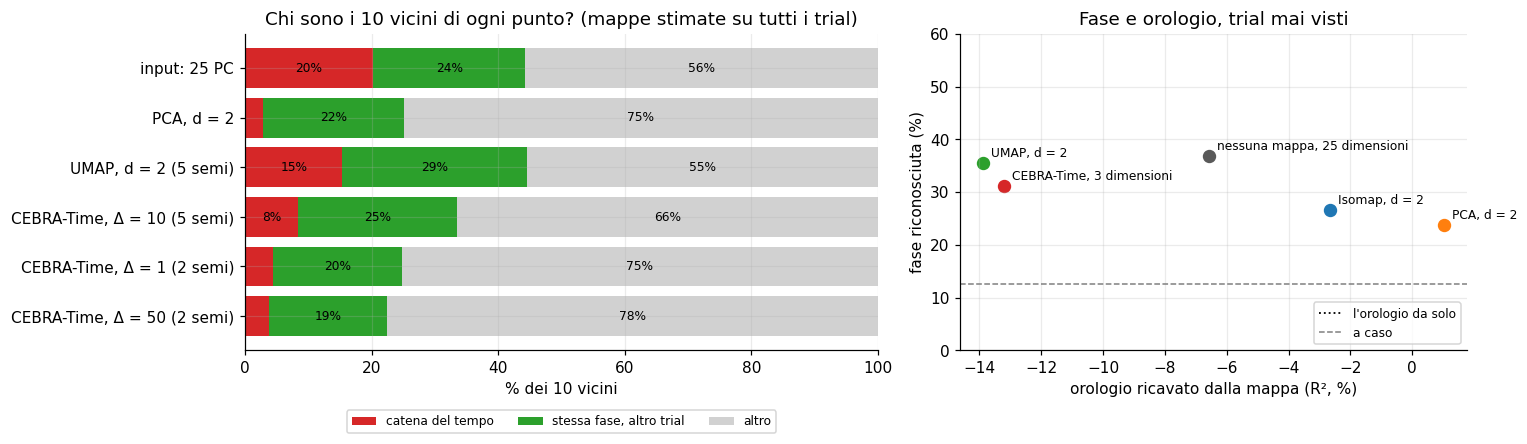

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": (1.25, 1)})
cats, cols = ["catena del tempo (%)", "stessa fase, altro trial (%)", "altro (%)"], ["C3", "C2", "0.82"]
rows_plot = [r_ for r_ in tab_mix.index if r_ != "a caso"]
for i, name in enumerate(rows_plot):                        # una barra per mappa, i tre gruppi uno dopo l'altro
    left = 0
    for c, col in zip(cats, cols):
        v = tab_mix.loc[name, c]
        ax[0].barh(i, v, left=left, color=col, label=c.replace(" (%)", "") if i == 0 else None)
        if v > 5:
            ax[0].text(left + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8)
        left += v
ax[0].set_yticks(range(len(rows_plot))); ax[0].set_yticklabels(rows_plot); ax[0].invert_yaxis()
ax[0].set(xlim=(0, 100), xlabel="% dei 10 vicini", title="Chi sono i 10 vicini di ogni punto? (mappe stimate su tutti i trial)")
ax[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.17), fontsize=8)
names_c = list(clock_r2)
xr = [np.mean(clock_r2[n]) * 100 for n in names_c]          # quanto orologio c'è nella mappa
ya = [np.mean(ACC[ACC_OF.get(n, n)]) for n in names_c]    # quanto riconosce la fase
for n, x_, y_ in zip(names_c, xr, ya):
    ax[1].scatter(x_, y_, s=60, color="C3" if n.startswith("CEBRA") else ("C2" if n.startswith("UMAP") else
                                                                         "C0" if n.startswith("Isomap") else "C1" if n.startswith("PCA") else "0.35"))
    ax[1].annotate(n, (x_, y_), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax[1].axhline(ACC["l'orologio da solo (1 numero)"], color="k", ls=":", lw=1.2, label="l'orologio da solo")
ax[1].axhline(12.5, color="0.5", ls="--", lw=1, label="a caso")
ax[1].set(xlabel="orologio ricavato dalla mappa (R², %)", ylabel="fase riconosciuta (%)", ylim=(0, 60),
          title="Fase e orologio, trial mai visti")
ax[1].legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(FIGS / "04_time_chain.png", bbox_inches="tight"); plt.show()

**Lettura.**

**(a) La catena del tempo non domina la mappa.** Nella mappa di CEBRA-Time (Δ = 10) solo il 7.9% dei
vicini è catena del tempo: meno che nell'input (20.4%) e in UMAP (16.1%). I vicini "stessa fase,
altro trial" sono il 33.1%, come in UMAP (33.9%), più che nell'input (27.1%) e molto più del caso
(12.7%). Nonostante il suo gioco avvicini ogni istante a quello 200 ms dopo, alla scala dei punti
di valutazione (uno ogni 100 ms) i vicini di un punto vengono soprattutto da altri trial.

**(b) L'orologio da solo riconosce la fase al 48.5%**: più di tutte le mappe e più dei tetti
(42.2% e 44.9%). Sapere solo da quanto è cominciato il trial basta a indovinare la fase meglio che
con l'attività neurale, con qualunque metodo. Non è un errore dei metodi, che l'orologio non lo
vedono, ma cambia il modo di leggere i numeri assoluti del metro comune, anche quelli del 03: il
confronto tra metodi resta alla pari, ma "40%" va letto accanto a quello che la struttura del task
dà gratis.

**(c) Le mappe non sono un orologio.**

- Dal tempo trascorso le mappe non ricavano quasi nulla: R² tra −11% e +2% per tutte, CEBRA
  compresa (−10.6%).
- Punto per punto, mappa e orologio indovinano **cose diverse**: dei punti che CEBRA riconosce
  (20.5% + 17.5% = 38%), quasi la metà (17.5%) sono sbagliati per l'orologio. Lo stesso vale per
  UMAP e per il classificatore sulle 25 dimensioni.
- Fase per fase la divisione è netta. L'orologio riconosce le fasi del braccio, che si susseguono
  a tempi quasi fissi dopo l'inizio del trial: `Reach` 99%, `Orient` 81%, `Carry` 73%. Fallisce
  `Shape` (4%) e `SnapTo` (12%). Le mappe neurali riconoscono invece le fasi della mano: `Shape`
  66-75%, `Release` 60-68%, `Grasp` 45-59%, coerentemente con la posizione degli array nell'area
  della mano (02 e 03). Le fasi del braccio, nelle mappe, si confondono tra loro (22-50%).

**(d) Δ = 10 è il valore migliore** dei tre: 35.3% e 35.9% (semi 0 e 1), contro 30.5% e 27.8% con
Δ = 1 e 21.8% e 23.9% con Δ = 50. Con Δ = 1 il gioco è troppo facile; con Δ = 50 il positivo cade
spesso in un'altra fase. L'ipotesi "con Δ = 1 resta solo la catena" non si conferma: la catena tra
i vicini scende (3.7%) insieme a tutto il resto ("altro" al 76%). La rete impara semplicemente di
meno. Limite: i 1000 passi sono stati scelti per Δ = 10.

**In sintesi**: CEBRA-Time con Δ = 10 non impara solo la catena del tempo, e nemmeno un orologio.
Impara soprattutto l'attività legata alle fasi della mano, come UMAP per quanto riguarda i vicini,
ma con mappe meno stabili da un seme all'altro (§5.2). E il riconoscimento della fase, la misura
comune di tutti i notebook, ha un termine di confronto "senza neuroni" molto alto: l'orologio.

In [36]:
# REPLICA: solo le definizioni della cella tolta 73
from sklearn.cross_decomposition import PLSRegression

def label_z(train_trials):                                  # z-score delle 14 etichette con media e deviazione dei soli trial di training
    m = np.isin(trial, train_trials)
    return ((Y_KIN - Y_KIN[m].mean(0)) / Y_KIN[m].std(0)).astype(np.float32)

def cebra_fit_beh(X_train, y_train, X_apply, cfg, seed, val=None, model_path=None):
    """Come cebra_fit (§2.3), ma con le etichette: CEBRA-Behavior. val = {nome: (X, y)}: insiemi su cui misurare,
    alla fine, la funzione di costo con la stessa scelta dei positivi. Gira nel processo separato."""
    import time                                             # per misurare la durata
    import numpy as np                                      # array
    import torch                                            # la libreria delle reti neurali usata da CEBRA
    import cebra                                            # CEBRA
    import cebra.distributions.base as cdb                  # per la correzione del seme (§2.7)
    torch.set_num_threads(1)                                # i calcoli pesanti sono sulla GPU
    if not hasattr(cdb.HasGenerator, "orig_init"):          # la stessa correzione del seme di cebra_fit (§2.7), codice identico
        cdb.HasGenerator.orig_init = cdb.HasGenerator.__init__
        def seeded_init(self, device, seed):
            cdb.HasGenerator.orig_init(self, device=device, seed=seed)
            if cdb.HasGenerator.fixed_seed is not None:
                self._seed = cdb.HasGenerator.fixed_seed * 1000 + cdb.HasGenerator.counter
                cdb.HasGenerator.counter += 1
                self._generator = torch.Generator(device=self.device).manual_seed(self._seed)
        cdb.HasGenerator.__init__ = seeded_init
    cdb.HasGenerator.fixed_seed = seed                      # sempre con la correzione
    cdb.HasGenerator.counter = 0
    torch.manual_seed(seed); np.random.seed(seed)
    device = "mps" if torch.backends.mps.is_available() else "cpu"
    model = cebra.CEBRA(**cfg, device=device, verbose=False)
    t0 = time.time()
    model.fit(X_train, y_train)                             # con un'etichetta continua: CEBRA-Behavior (positivi scelti con "time_delta")
    seconds = time.time() - t0
    if model_path is not None:
        model.save(str(model_path))
    extra = {name: float(cebra.sklearn.metrics.infonce_loss(model, Xv, yv, num_batches=200))  # funzione di costo su dati dati, 200 gruppi
             for name, (Xv, yv) in (val or {}).items()}
    return {"maps": [model.transform(x) for x in X_apply], "loss": np.asarray(model.state_dict_["loss"]),
            "seconds": seconds, "device": device, "extra": extra}

In [37]:
# REPLICA: solo le definizioni della cella tolta 75
ITER_BEH = (1, 500, 1000, 2000, 5000, 10_000)

jobs_it, keys_it = [], []

N_ITER_BEH = 0

In [38]:
# REPLICA: solo le definizioni della cella tolta 77
def decode_label(inp, embed, lab):                          # come decode_map, ma con un'altra etichetta da riconoscere
    b, folds = inp
    pred = np.empty(len(b), dtype=object)
    for Xtr, Xte, trn, tst in folds:
        Etr, Ete = embed(Xtr, Xte)
        pred[tst] = KNeighborsClassifier(n_neighbors=K_NN).fit(Etr, lab[b[trn]]).predict(Ete)
    return balanced_accuracy_score(lab[b], pred) * 100

def kin_r2(inp, embed, cols):                               # R² medio con cui un regressore a 10 vicini ricava alcune colonne della cinematica
    b, folds = inp
    pred = np.empty((len(b), len(cols)))
    for Xtr, Xte, trn, tst in folds:
        Etr, Ete = embed(Xtr, Xte)
        pred[tst] = KNeighborsRegressor(n_neighbors=K_NN).fit(Etr, Y_KIN[b[trn]][:, cols]).predict(Ete)
    return r2_score(Y_KIN[b][:, cols], pred) * 100

def umap_fold(d, sd, k):                                    # UMAP del blocco k come in emb_umap (§1.2): (punti di training, punti di test)
    Xtr, Xte, trn, tst = INP_PC[1][k]
    u = UMAP(n_neighbors=K_NN, n_components=d, min_dist=0.1, random_state=sd, n_jobs=1).fit(Xtr)
    return u.embedding_, u.transform(Xte)

def umap_inp(d, sd):                                        # l'input del metro comune con le mappe UMAP già stimate
    return (bins, [(*UMAP_F[(d, sd, k)], trn, tst) for k, (trn, tst) in enumerate(FOLDS)])

ROWS_6 = [("PCA, d = 2", 2, "no"), ("UMAP, d = 2", 2, "no"), ("CEBRA-Time, 3 dimensioni", 2, "no"),
          ("PLS, 2 componenti", 2, "sì"), ("CEBRA-Behavior, 3 dimensioni", 2, "sì"),
          ("PCA, d = 3", 3, "no"), ("UMAP, d = 3", 3, "no"), ("CEBRA-Time, 4 dimensioni", 3, "no"),
          ("PLS, 3 componenti", 3, "sì"), ("CEBRA-Behavior, 4 dimensioni", 3, "sì"),
          ("tetto, 25 dimensioni", 25, "no"), ("tetto alla pari: media sulla finestra (25 numeri)", 25, "no"),
          ("l'orologio da solo (1 numero)", 1, "(il tempo)")]

In [39]:
# REPLICA: solo le definizioni della cella tolta 79
def shuffled_labels(k, how, seed):                          # le etichette dei trial di training del blocco k, mescolate
    rng_s = np.random.default_rng(seed)
    tb = TRAIN_BINS[k]
    y_ = YZ_F[k][tb]
    if how == "tempo":                                      # ogni bin riceve l'etichetta di un bin a caso
        return y_[rng_s.permutation(len(tb))]
    trs = list(np.unique(trial[tb]))                        # i trial di training
    while True:                                             # un rimescolamento in cui nessun trial tiene la propria cinematica
        perm = rng_s.permutation(trs)
        if not np.any(perm == np.array(trs)):
            break
    out = []
    for t, t_other in zip(trs, perm):                       # ogni trial riceve la cinematica di un altro, allineata all'inizio
        n_t, y_o = (trial == t).sum(), YZ_F[k][trial == t_other]
        out.append(y_o[:n_t] if len(y_o) >= n_t else np.r_[y_o, np.repeat(y_o[-1:], n_t - len(y_o), axis=0)])
    return np.concatenate(out).astype(np.float32)

CONTROLS = ("tempo", "trial")

In [40]:
# REPLICA: solo le definizioni della cella tolta 82
from sklearn.linear_model import Ridge

rows_k = {}

def kin_pred_r2(make_model):                                # R² di ogni grado di libertà, con un modello stimato sui punti di training di ogni blocco
    pred = np.empty((len(bins), Y_KIN.shape[1]))
    for Xtr, Xte, trn, tst in INP_PC[1]:
        pred[tst] = make_model().fit(Xtr, Y_KIN[bins[trn]]).predict(Xte)
    return r2_score(Y_KIN[bins], pred, multioutput="raw_values")

In [41]:
# REPLICA: solo le definizioni della cella tolta 85
SEEDS3 = (0, 1, 2)

def variant_jobs(cfg, X_full=None, train_bins=None, labels=None):  # gli allenamenti di una variante: 3 semi × 5 blocchi
    jobs = []
    for sd in SEEDS3:
        for k in range(5):
            Xk = (X25[k] if X_full is None else X_full[k]).astype(np.float32)  # input di tutta la sessione per il blocco k
            tb = TRAIN_BINS[k] if train_bins is None else train_bins[k]       # i bin su cui si allena
            j = dict(X_train=Xk[tb], X_apply=[Xk[trial == t] for t in TRIALS], cfg=cfg, seed=sd)
            if labels is not None:
                j["y_train"] = labels[k][tb]                # le etichette (solo per CEBRA-Behavior, §7c)
            jobs.append(j)
    return jobs

def run_variants(variants, fn=None):                        # tutte le varianti in un'unica coda; restituisce le 3 accuratezze di ognuna
    names, jobs = [], []
    for name, v in variants.items():
        js = variant_jobs(**v)
        jobs += js; names += [name] * len(js)
    res = run_cebra_cached(jobs, fn=fn)
    out, maps_out = {}, {}
    for name in variants:
        rs = [r for n_, r in zip(names, res) if n_ == name] # i 15 risultati della variante: seme esterno, blocco interno
        maps = {(sd, k): np.concatenate(rs[i * 5 + k]["maps"]) for i, sd in enumerate(SEEDS3) for k in range(5)}
        out[name] = [decode_map(fold_inp(lambda k, sd=sd: maps[(sd, k)]), emb_none) for sd in SEEDS3]
        maps_out[name] = maps
    return out, maps_out

MAIN = "principale (3 dimensioni, τ = 1, offset10, 1000 passi, coseno)"

def sens_table(acc, ref_name):                              # tabella: media (min-max) e differenza dalla principale, seme per seme
    ref = np.array(acc[ref_name])
    return pd.DataFrame({name: {"fase riconosciuta (%), 3 semi": mean_range(v),
                                "differenza dalla principale (punti), media": f"{np.mean(np.array(v) - ref):+.1f}",
                                "differenza, seme per seme": " ".join(f"{d_:+.1f}" for d_ in np.array(v) - ref)}
                         for name, v in acc.items()}).T

In [42]:
# REPLICA: solo le definizioni della cella tolta 87
HI_ACC = {}

In [43]:
# REPLICA: solo le definizioni della cella tolta 90
import contextlib, logging

from elephant.gpfa import gpfa_core

import elephant.utils

def make_seqs(segs):                                        # i dati nel formato di elephant: un pezzo (inizio, fine) per riga
    return np.array([(b_ - a_, Y_SQRT[a_:b_].T) for a_, b_ in segs], dtype=[("T", int), ("y", "O")])

def fit_gpfa_fold(k):                                       # GPFA a 25 fattori sulle finestre da 1 s dei trial di training del blocco k (03, §7.2)
    train_tr = np.unique(trial[TRAIN_BINS[k]])
    np.random.seed(0)                                       # punto di partenza fisso
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
        params, _ = gpfa_core.fit(make_seqs([(w["start"], w["stop"]) for w in windows if w["trial"] in train_tr]),
                                  x_dim=K_PCA, bin_width=20.0, em_max_iters=500, tau_init=100.0)
    return params

SEG, KEEP = 100, 50

def gpfa_continuous(params):                                # i 25 fattori ordinati di ogni bin della sessione, a pezzi sovrapposti dentro ogni trial
    segs, owner = [], []
    for t in TRIALS:
        a0, a1 = first_last[t][0], first_last[t][1] + 1     # inizio e fine del trial
        starts = list(range(a0, a1 - SEG + 1, KEEP))
        if starts[-1] != a1 - SEG:
            starts.append(a1 - SEG)                         # l'ultimo pezzo finisce esattamente alla fine del trial
        centers = np.array(starts) + SEG / 2
        for x in range(a0, a1):                             # ogni bin viene dal pezzo in cui è più centrale
            owner.append((x, len(segs) + int(np.argmin(np.abs(centers - x)))))
        segs += [(a_, a_ + SEG) for a_ in starts]
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
        lat, _ = gpfa_core.exact_inference_with_ll(make_seqs(segs), params, get_ll=False)
        _, orth = gpfa_core.orthonormalize(params, lat)     # fattori ruotati e ordinati per importanza
    out = np.empty((n_bins, K_PCA))
    for x, i in owner:
        out[x] = orth["latent_variable_orth"][i][:, x - segs[i][0]]
    return out

rows_b = {}

In [44]:
# REPLICA: solo le definizioni della cella tolta 92
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

HAND = [10, 11, 12, 13]

In [45]:
# REPLICA: solo le definizioni della cella tolta 96
def row(name, lab, a2=None, a3=None, a7=None):              # una riga della tabella finale
    return {"metodo": name, "etichette": lab, "2 coordinate libere": fmt(a2) if a2 is not None else "",
            "3 coordinate libere": fmt(a3) if a3 is not None else "", "7 coordinate libere": fmt(a7) if a7 is not None else ""}

def tstat(name, col):                                       # una misura delle traiettorie (§4.2): media (min-max) tra i semi
    v = np.array([r_[col] for r_ in TRAJ[name]])
    return f"{v.mean():.3f}" if len(v) == 1 else f"{v.mean():.3f} ({v.min():.3f}-{v.max():.3f})"

In [46]:
# REPLICA: solo le definizioni della cella tolta 97
METH = ["PCA", "Isomap", "UMAP", "GPFA (primi fattori)", "CEBRA-Time (3, 4 e 8 dimensioni)",
        "CEBRA-Behavior, posizione + velocità", "PLS, posizione + velocità"]

COLS8 = {"PCA": "C1", "Isomap": "C0", "UMAP": "C2", "GPFA (primi fattori)": "C4", "CEBRA-Time (3, 4 e 8 dimensioni)": "C3",
         "CEBRA-Behavior, posizione + velocità": "#f4a6a6", "PLS, posizione + velocità": "0.6"}

w = 0.11

In [47]:
# REPLICA: dal §7b, solo la GPFA per blocco (X_GP), che il §12.2 usa come termine di confronto
Zc = StandardScaler().fit_transform(s.spikes[:, ACTIVE].astype(float))  # conteggi grezzi z-scorati, 160 canali (03, §2)
Y_SQRT = np.sqrt(s.spikes[:, ACTIVE].astype(float))         # la radice dei conteggi: l'input della GPFA (02_new, §10)

def make_seqs(segs):                                        # i dati nel formato di elephant: un pezzo (inizio, fine) per riga
    return np.array([(b_ - a_, Y_SQRT[a_:b_].T) for a_, b_ in segs], dtype=[("T", int), ("y", "O")])

def fit_gpfa_fold(k):                                       # GPFA a 25 fattori sulle finestre da 1 s dei trial di training del blocco k (03, §7.2)
    train_tr = np.unique(trial[TRAIN_BINS[k]])
    np.random.seed(0)                                       # punto di partenza fisso
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
        params, _ = gpfa_core.fit(make_seqs([(w["start"], w["stop"]) for w in windows if w["trial"] in train_tr]),
                                  x_dim=K_PCA, bin_width=20.0, em_max_iters=500, tau_init=100.0)
    return params

SEG, KEEP = 100, 50                                         # pezzi da 2 s (100 bin), ogni 1 s (50 bin)

def gpfa_continuous(params):                                # i 25 fattori ordinati di ogni bin della sessione, a pezzi sovrapposti dentro ogni trial
    segs, owner = [], []
    for t in TRIALS:
        a0, a1 = first_last[t][0], first_last[t][1] + 1     # inizio e fine del trial
        starts = list(range(a0, a1 - SEG + 1, KEEP))
        if starts[-1] != a1 - SEG:
            starts.append(a1 - SEG)                         # l'ultimo pezzo finisce esattamente alla fine del trial
        centers = np.array(starts) + SEG / 2
        for x in range(a0, a1):                             # ogni bin viene dal pezzo in cui è più centrale
            owner.append((x, len(segs) + int(np.argmin(np.abs(centers - x)))))
        segs += [(a_, a_ + SEG) for a_ in starts]
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
        lat, _ = gpfa_core.exact_inference_with_ll(make_seqs(segs), params, get_ll=False)
        _, orth = gpfa_core.orthonormalize(params, lat)     # fattori ruotati e ordinati per importanza
    out = np.empty((n_bins, K_PCA))
    for x, i in owner:
        out[x] = orth["latent_variable_orth"][i][:, x - segs[i][0]]
    return out

GP_PARAMS = Parallel(n_jobs=5)(delayed(fit_gpfa_fold)(k) for k in range(5))  # le 5 GPFA in parallelo
X_GP = [gpfa_continuous(p_) for p_ in GP_PARAMS]            # per ogni blocco, i fattori di tutta la sessione (12233 × 25)
print(f"Fattori GPFA: {X_GP[0].shape}; bin senza valore: {int(np.isnan(np.stack(X_GP)).sum())}")

Fattori GPFA: (12078, 25); bin senza valore: 0


---
# Parte B · LFADS

**LFADS in una frase.** *Latent Factor Analysis via Dynamical Systems* (Pandarinath et al. 2018) è
un modello che, come la GPFA (02_new, §10), parte dai **conteggi** di ogni trial e restituisce
**traiettorie lisce** di pochi fattori. La differenza: la GPFA sa solo che i fattori "non fanno
salti" (una regola generica, uguale per tutti i momenti), LFADS **impara le regole del moto**: da
dove si trova lo stato adesso, dove andrà dopo. È la differenza tra sapere che un'auto non si
teletrasporta e conoscere la strada che sta percorrendo. Nella review è il modello dinamico del §2.6
(equazione 3) reso concreto con una rete ricorrente (§4.2); al §5.5 è citato per la decodifica nelle
interfacce cervello-computer.

LFADS è la **"GPFA non lineare"**: le regole del moto sono una rete neurale (non lineare), e il
legame tra fattori e frequenze di sparo passa per un esponenziale. Allo stesso modo, una rete che
guarda un bin alla volta, senza regole del moto, sarebbe la "FA non lineare": la proviamo al §14.

**A differenza di CEBRA, LFADS è un modello generativo vero.** Ha tutte e due le metà: dai dati ai
fattori (l'*encoder*) e dai fattori ai dati (il *generatore* con la sua uscita), e assegna una
probabilità a ogni possibile sequenza di conteggi. Per questo può produrre trial finti (§11) e si
può giudicare su quanto bene **predice dati mai visti** (§12), cosa che per CEBRA non ha senso.

**La domanda della parte B.** Su questi dati, la non linearità e la dinamica imparata migliorano le
traiettorie single-trial rispetto alla GPFA? Il confronto principale è **LFADS contro GPFA alla
pari**: stessi conteggi, stessi pezzi di registrazione, stesso numero di fattori (25).

**Le scelte concordate prima di cominciare:**

| scelta | decisione | alternativa (dove) |
|---|---|---|
| codice | un LFADS piccolo scritto a mano per capire (§10), la libreria `lfads-torch` (Sedler & Pandarinath 2023) per gli allenamenti veri, con un ciclo di allenamento scritto qui | il `Trainer` di Lightning della libreria (richiede una correzione, §10) |
| dati | la sola sessione di riferimento, come in tutti i notebook | le altre due sessioni dello stesso giorno (§14) |
| taglio | pezzi da 600 ms sovrapposti di 200 ms, dentro ogni trial, ricuciti con pesi graduali (§9.2) | 400 ms e 1 s (§14) |
| ingressi esterni (*controller*) | no | sì (§14) |

**Due limiti da dichiarare subito.**

- **Pochi dati.** Una rete ricorrente ha molti parametri, e il rischio è che impari a memoria
  invece di capire. Con gli spike c'è una forma particolare di questo rischio: la rete può imparare a
  **copiare** l'ingresso, e la validazione abituale non se ne accorge (Keshtkaran & Pandarinath
  2019). Con parametri fissi le prestazioni di LFADS peggiorano molto quando i trial diminuiscono
  (stesso articolo; Keshtkaran et al. 2022). Le difese: un modello piccolo, il *coordinated
  dropout* (§10), la validazione su trial mai visti.
- **Niente AutoLFADS.** AutoLFADS (Keshtkaran et al. 2022) sceglie i parametri da solo, allenando
  decine di modelli in parallelo che si scambiano i parametri migliori (40 per i dati del
  labirinto). Su un portatile non è fattibile: **i parametri li scegliamo a mano, con una piccola
  griglia valutata sui trial di validazione** (§11).

La pipeline:

```
spike_times ──(bin 20 ms, 160 canali attivi, NESSUNO smoothing)──► conteggi   12233 × 160

conteggi ──(§9: pezzi da 600 ms dentro ogni trial, sovrapposti di 200 ms)──► sequenze   30 bin × 160

sequenze dei trial di training ──(LFADS)──► modello allenato

ogni trial ──(modello già allenato, senza riallenarlo)──► fattori di ogni pezzo ──(ricucitura)──► 25 fattori per bin

valutazione: metro comune (1106 punti, 5 blocchi), traiettorie, canali nascosti
```

I passi: §9 i dati · §10 l'idea su un esempio sintetico · §11 un primo allenamento · §12 metro comune
e confronto con la GPFA · §13 controlli · §14 sensibilità e alternative · §15 riepilogo e tabella
finale. **Stato attuale: completa, §9-§15.**

**Come eseguire il notebook.** La sera del 27 ottobre, rieseguendo tutto il notebook, il kernel si è
chiuso da solo tre volte di seguito durante il §7c della parte A, sempre nello stesso punto: memoria
danneggiata dentro numpy, con due copie di OpenMP caricate e decine di thread che chiamavano OpenBLAS (che
lo segnalava con un avviso: *precompiled NUM_THREADS exceeded*). Lanciando Jupyter con
`OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1` l'esecuzione arriva in fondo, con gli stessi risultati: cambiano
solo le ultime cifre binarie di alcuni calcoli. Per questo 15 modelli CEBRA del §7b, il cui ingresso sono i
fattori della GPFA, sono stati riallenati, con le stesse accuratezze. Perché il problema sia comparso solo
quella sera non l'abbiamo capito.

## 9 · I dati per LFADS

Quattro decisioni, prima di qualunque rete:

- **9.1** che cosa riceve LFADS: i **conteggi grezzi**;
- **9.2** come si taglia la registrazione in **pezzi di lunghezza fissa**, e come si ricuciono;
- **9.3** quali trial servono per allenare, quali per **validare** e quali per il **test**;
- **9.4** quali canali **nascondere** per la misura propria dei modelli generativi (§12);

più due avvertenze sul task (§9.5): la fase `SnapTo` e le due versioni del task.

### 9.1 · I conteggi grezzi

Fino a qui (parte A, 03) i metodi ricevevano i firing rate **smussati** (σ = 50 ms). LFADS no: riceve
i **conteggi** di ogni bin da 20 ms, numeri interi piccoli, e ha un suo modello del rumore. Assume
che, data la frequenza "vera" di un canale in un istante, il numero di spike sia **casuale secondo
Poisson**: come il numero di auto che passano sotto casa in un minuto, che oscilla intorno a una
media. Il compito di LFADS è proprio ritrovare quella media, istante per istante. Se smussassimo
prima, faremmo noi, con un filtro scelto a mano, una parte del lavoro che LFADS deve fare, e i dati
non sarebbero più conteggi (Poisson ha senso solo per numeri interi). È la stessa scelta della FA e
della GPFA nel 02_new (§9 e §10), che partivano dai conteggi.

Controlliamo che siano esattamente i conteggi già usati nella parte A: quelli da cui parte la GPFA
(la loro radice, §7b) e quelli dati a CEBRA nell'alternativa "conteggi grezzi" (§7b).

In [48]:
COUNTS = s.spikes[:, ACTIVE].astype(np.float32)             # i conteggi grezzi a 20 ms dei 160 canali attivi: l'ingresso di LFADS (float32, il formato delle reti)
N_CH = COUNTS.shape[1]                                      # numero di canali (160)
print(f"Conteggi: {COUNTS.shape[0]} bin × {N_CH} canali; tutti interi: {np.array_equal(COUNTS, np.round(COUNTS))}; "
      f"massimo in un bin: {int(COUNTS.max())}")
print("Stessi conteggi della GPFA (la loro radice è Y_SQRT, §7b):", np.array_equal(np.sqrt(COUNTS.astype(float)), Y_SQRT))
print("Stessi conteggi dati a CEBRA nel §7b (z-scorati):", np.allclose(StandardScaler().fit_transform(COUNTS.astype(float)), Zc))

vals = pd.Series({"0 spike": np.mean(COUNTS == 0), "1 spike": np.mean(COUNTS == 1), "2 spike": np.mean(COUNTS == 2),
                  "3 spike": np.mean(COUNTS == 3), "4 o più": np.mean(COUNTS >= 4)}) * 100  # quanto spesso un canale vede k spike in un bin
rate_hz = COUNTS.mean(0) / io.BIN_S                         # frequenza media di ogni canale, in Hz
display(vals.round(2).rename("% dei bin (tutti i canali)").to_frame().T)
print(f"Frequenza media per canale: mediana {np.median(rate_hz):.1f} Hz (da {rate_hz.min():.1f} a {rate_hz.max():.1f} Hz); "
      f"spike attesi in un bin con la frequenza mediana: {np.median(rate_hz) * io.BIN_S:.2f}")

Conteggi: 12078 bin × 165 canali; tutti interi: True; massimo in un bin: 8
Stessi conteggi della GPFA (la loro radice è Y_SQRT, §7b): True
Stessi conteggi dati a CEBRA nel §7b (z-scorati): True


,0 spike,1 spike,2 spike,3 spike,4 o più
% dei bin (tutti i canali),74.2,19.45,5.06,1.08,0.21


Frequenza media per canale: mediana 11.2 Hz (da 0.5 a 69.5 Hz); spike attesi in un bin con la frequenza mediana: 0.22


**Lettura.**

- Sono gli stessi conteggi della parte A, bit per bit: quelli da cui parte la GPFA e quelli dati a
  CEBRA nell'alternativa del §7b. LFADS e GPFA partono quindi dagli stessi numeri.
- **In un bin un canale vede quasi sempre 0 o 1 spike**: 0 nel 77% dei casi, 1 nel 18%, 2 nel 4%,
  3 o più in meno dell'1% (al massimo 8). Con la frequenza mediana, circa 10 Hz, in 20 ms ci si
  aspettano 0.2 spike. È il terreno dei numeri piccoli e interi, dove il modello di Poisson è quello
  naturale; la GPFA li tratta invece con la radice e un rumore gaussiano, un'approssimazione.
- Un singolo bin di un singolo canale dice quindi pochissimo: per ritrovare la frequenza "vera"
  LFADS deve mettere insieme molti bin e molti canali, come la GPFA.

### 9.2 · Il taglio in pezzi e la ricucitura

LFADS lavora su **sequenze di lunghezza fissa**: per ognuna l'encoder legge tutta la sequenza, ne
ricava uno **stato iniziale**, e il generatore, partendo da lì, "srotola" la traiettoria bin per bin
(lo vedremo al §10). I nostri trial durano invece 13-19 s, tutti diversi. Le possibilità:

| taglio | pro | contro |
|---|---|---|
| **pezzi da 600 ms, sovrapposti di 200 ms** (scelto) | lo schema di AutoLFADS per una registrazione continua (Keshtkaran et al. 2022) e del Neural Latents Benchmark (Pei et al. 2021), che taglia i 15 minuti continui del dataset MC_RTT in "trial" da 600 ms; senza ingressi esterni il generatore deve indovinare da solo, dallo stato iniziale, tutto quello che succede nel pezzo: più è corto, meno deve indovinare | ogni pezzo vede poco contesto |
| pezzi da 1 s | stessa durata delle finestre del metro comune (§4.2) | il generatore deve srotolare da solo 1 s, spesso a cavallo di due fasi |
| pezzi da 2 s, tenendo il secondo centrale | lo schema usato per la GPFA continua del §7b | ancora più da srotolare senza ingressi; un bin su due si butta |

**Come si taglia.** Dentro **ogni trial** separatamente: un pezzo ogni 20 bin (400 ms), così due
pezzi consecutivi condividono 10 bin (200 ms); l'ultimo pezzo finisce esattamente con il trial,
come per la GPFA continua del §7b. Nessun pezzo attraversa il confine tra due trial: a differenza di
CEBRA (§1.5) non ci sono "giunte".

**Come si ricuce.** Dopo il modello, ogni bin ha un valore in ogni pezzo che lo contiene, e i due
valori non coincidono: ai bordi di un pezzo il modello sa meno che al centro. Facciamo una **media
pesata**: nella zona in comune il pezzo che finisce passa gradualmente la mano a quello che comincia,
come due voci in un coro che si danno il cambio senza stacco. I pesi sono quelli di AutoLFADS (Methods,
dataset RTT): con x che va da 0 a 1 lungo la sovrapposizione, il pezzo che finisce pesa 1 − x², quello
che comincia x². Le due curve sommano sempre a 1. Noi misuriamo x al centro di ogni bin (da 0.05 a
0.95 invece che da 0 a 1), così nessun peso vale esattamente 0. Dove i pezzi in comune sono più di due
o la sovrapposizione è più lunga (l'ultimo pezzo di ogni trial), dividiamo per la somma dei pesi.

**Il controllo a mano.** Se diamo alla ricucitura i pezzi dei **conteggi stessi**, ogni bin riceve
valori identici da tutti i pezzi che lo contengono, e la media pesata deve restituire esattamente i
conteggi originali.

In [49]:
SEG_LEN, SEG_OVL = 30, 10                                   # pezzi da 30 bin (600 ms), sovrapposti di 10 bin (200 ms)
SEG_STEP = SEG_LEN - SEG_OVL                                # un pezzo nuovo ogni 20 bin (400 ms)
TRIAL_SPAN = {t: (int(np.flatnonzero(trial == t)[0]), int(np.flatnonzero(trial == t)[-1]) + 1)  # per ogni trial: primo bin e bin dopo l'ultimo
              for t in TRIALS}

def segment_starts(a0, a1):                                 # dove cominciano i pezzi di un trial che va dal bin a0 al bin a1 (escluso)
    st = list(range(a0, a1 - SEG_LEN + 1, SEG_STEP))        # un pezzo ogni 20 bin...
    if st[-1] != a1 - SEG_LEN:
        st.append(a1 - SEG_LEN)                             # ...più un ultimo pezzo che finisce esattamente con il trial
    return np.array(st)

SEG_START = {t: segment_starts(*TRIAL_SPAN[t]) for t in TRIALS}  # per ogni trial, il primo bin di ciascuno dei suoi pezzi

def cut_segments(X, t):                                     # i pezzi del trial t di un segnale X (bin × colonne): (pezzi, 30 bin, colonne)
    return np.stack([X[a:a + SEG_LEN] for a in SEG_START[t]])

x_ovl = (np.arange(SEG_OVL) + 0.5) / SEG_OVL                # posizione lungo la sovrapposizione, da 0 a 1 (al centro di ogni bin)
RAMP_IN, RAMP_OUT = x_ovl ** 2, 1 - x_ovl ** 2              # peso del pezzo che comincia (sale) e di quello che finisce (scende): AutoLFADS

def segment_weights(n_seg):                                 # i pesi dei 30 bin di ognuno degli n_seg pezzi di un trial
    W = np.ones((n_seg, SEG_LEN))                           # 1 dove il pezzo è da solo
    W[1:, :SEG_OVL] = RAMP_IN                               # tutti i pezzi tranne il primo del trial cominciano con la rampa in salita
    W[:-1, -SEG_OVL:] = RAMP_OUT                            # tutti tranne l'ultimo finiscono con la rampa in discesa
    return W

def stitch(Y_seg, t):                                       # ricuce i pezzi del trial t (pezzi × 30 bin × colonne) in un segnale continuo (bin del trial × colonne)
    a0, a1 = TRIAL_SPAN[t]
    num, den = np.zeros((a1 - a0, Y_seg.shape[2])), np.zeros((a1 - a0, 1))
    for a, y, w in zip(SEG_START[t] - a0, Y_seg, segment_weights(len(Y_seg))):
        num[a:a + SEG_LEN] += w[:, None] * y                # somma dei valori pesati...
        den[a:a + SEG_LEN] += w[:, None]                    # ...e dei pesi
    return num / den                                        # media pesata in ogni bin

SEGS = {t: cut_segments(COUNTS, t) for t in TRIALS}         # i pezzi dei conteggi, trial per trial: le sequenze di LFADS
back = np.concatenate([stitch(SEGS[t], t) for t in TRIALS]) # ricuciti, uno dopo l'altro (i trial sono in ordine di tempo e coprono tutta la sessione)
print(f"Pezzi per trial: da {min(len(v) for v in SEGS.values())} a {max(len(v) for v in SEGS.values())}; "
      f"in tutto {sum(len(v) for v in SEGS.values())} pezzi da {SEG_LEN} bin")
print("Ogni pezzo sta dentro il suo trial:", all(np.all(trial[a:a + SEG_LEN] == t) for t in TRIALS for a in SEG_START[t]))
print(f"Ricucitura dei conteggi stessi: differenza massima dai conteggi originali {np.abs(back - COUNTS).max():.1e}; "
      f"identici dopo l'arrotondamento: {np.array_equal(np.round(back), COUNTS)}")
print("Pesi nelle sovrapposizioni regolari (due pezzi, 10 bin): sommano a 1:", np.allclose(RAMP_IN + RAMP_OUT, 1))
cover = np.zeros(n_bins, int)                               # quanti pezzi contengono ogni bin
for t in TRIALS:
    for a in SEG_START[t]:
        cover[a:a + SEG_LEN] += 1
print("Bin contenuti in 1, 2 o 3 pezzi (%):", {k: round(np.mean(cover == k) * 100, 1) for k in (1, 2, 3)})

Pezzi per trial: da 36 a 48; in tutto 602 pezzi da 30 bin
Ogni pezzo sta dentro il suo trial: True
Ricucitura dei conteggi stessi: differenza massima dai conteggi originali 8.9e-16; identici dopo l'arrotondamento: True
Pesi nelle sovrapposizioni regolari (due pezzi, 10 bin): sommano a 1: True
Bin contenuti in 1, 2 o 3 pezzi (%): {1: np.float64(50.6), 2: np.float64(49.2), 3: np.float64(0.2)}


**Lettura.**

- **610 pezzi** in tutto, da 33 a 48 per trial, e nessuno attraversa il confine tra due trial.
- **Il controllo a mano funziona**: ricucendo i pezzi dei conteggi stessi si ritrovano i conteggi
  originali; la differenza massima, 9·10⁻¹⁶, è l'arrotondamento dei numeri del computer. Nelle
  sovrapposizioni regolari i pesi sommano a 1, come in AutoLFADS.
- **Metà dei bin sta in due pezzi** (49.3%), l'altra metà in uno solo (50.5%): di ogni 20 bin nuovi,
  10 sono in comune con il pezzo precedente. Solo lo 0.1% sta in tre pezzi, alla fine di qualche
  trial, dove l'ultimo pezzo è allineato alla fine.
- **Che cosa il controllo non dice**: con valori identici qualunque media pesata restituisce lo
  stesso numero. Dice che la ricucitura è una media corretta, non che i valori di LFADS ai bordi dei
  pezzi siano buoni. Se le cuciture lasciano dei "gradini" nei fattori lo vedremo sulle uscite vere
  del modello (§11), ed è importante per la seghettatura (§12).

### 9.3 · Training, validazione e test

**Il test** è lo stesso di tutto il notebook: i 5 blocchi del 03, ognuno con 3 trial di test. In
ogni blocco LFADS si allena **solo** sui trial di training; per i trial di test si calcolano i
fattori con il modello già allenato, senza riallenarlo (§12). La "scorciatoia" del 03 (§7), cioè
allenare su tutti i trial, è vietata.

**La validazione** serve durante l'allenamento: a decidere quando fermarsi (prima che la rete cominci
a imparare a memoria) e quale versione del modello tenere. Non può usare i trial di test. In ogni
blocco mettiamo quindi da parte **2 dei 12 trial di training**: LFADS impara i suoi pesi sugli altri
10, e guarda i 2 di validazione solo per decidere quando fermarsi. La regola, fissata prima di
guardare: **l'ultimo trial pari e l'ultimo trial dispari** tra quelli di training del blocco.

- Uno pari e uno dispari: le due versioni del task (03, §9.2) sono rappresentate tutte e due.
- Nel blocco 0 la regola dà proprio la coppia 12 e 15 usata per CEBRA al §3.2; al §11 ripeteremo i
  controlli anche con la seconda coppia del §3.2 (6 e 7), a metà sessione.
- Il classificatore del metro comune impara invece dai punti di **tutti** i 12 trial di training,
  come per ogni altro metodo: i trial di validazione non vengono buttati, sono solo esclusi dai pesi
  della rete.

In [50]:
VAL_LF = []                                                 # per ogni blocco, i 2 trial di validazione di LFADS
for tt in TEST_TRIALS:
    tr_ = [int(t) for t in TRIALS if t not in tt]           # i 12 trial di training del blocco
    VAL_LF.append((max(t for t in tr_ if t % 2 == 0), max(t for t in tr_ if t % 2 == 1)))  # l'ultimo pari e l'ultimo dispari
FIT_LF = [[int(t) for t in TRIALS if t not in tt and t not in vt]  # i 10 trial su cui LFADS impara i pesi
          for tt, vt in zip(TEST_TRIALS, VAL_LF)]

def n_seg(trs):                                             # numero di pezzi di un gruppo di trial
    return sum(len(SEGS[t]) for t in trs)

tab_split = pd.DataFrame([{"test": ", ".join(map(str, tt)), "validazione": ", ".join(map(str, sorted(vt))),
                           "trial su cui impara": len(ft),
                           "pezzi: impara / validazione / test": f"{n_seg(ft)} / {n_seg(vt)} / {n_seg(tt)}",
                           "secondi su cui impara": round(sum(TRIAL_SPAN[t][1] - TRIAL_SPAN[t][0] for t in ft) * io.BIN_S),
                           "di cui movimento (%)": round(np.mean(MOV[np.isin(trial, ft)]) * 100),
                           "test: dispari / pari": f"{sum(t % 2 for t in tt)} / {sum(1 - t % 2 for t in tt)}"}
                          for tt, vt, ft in zip(TEST_TRIALS, VAL_LF, FIT_LF)], index=pd.Index(range(5), name="blocco"))
display(tab_split)
print("Blocco 0: validazione uguale a quella di CEBRA (§3.2, trial 12 e 15):", tuple(sorted(VAL_LF[0])) == tuple(sorted(VAL_TRIALS)))

,test,validazione,trial su cui impara,pezzi: impara / validazione / test,secondi su cui impara,di cui movimento (%),test: dispari / pari
blocco,,,,,,,
0,"5, 8, 9","14, 15",10,398 / 81 / 123,160,48,2 / 1
1,"3, 4, 15","13, 14",10,395 / 84 / 123,159,47,2 / 1
2,"2, 12, 14","10, 15",10,403 / 78 / 121,162,47,0 / 3
3,"7, 10, 11","14, 15",10,403 / 81 / 118,162,47,2 / 1
4,"1, 6, 13","14, 15",10,404 / 81 / 117,162,48,2 / 1


Blocco 0: validazione uguale a quella di CEBRA (§3.2, trial 12 e 15): False


**Lettura.**

- In ogni blocco LFADS impara i pesi su **circa 400 pezzi** (10 trial, circa 160 s, metà dei quali
  di movimento), si ferma guardando circa 90 pezzi di validazione, e si valuta su circa 120 pezzi di
  test. I pezzi si sovrappongono, quindi valgono meno di 400 esempi indipendenti. Per confronto, il
  dataset più piccolo del Neural Latents Benchmark, MC_Maze-S, ha 100 trial di training (Pei et al.
  2021).
- LFADS impara su 10 trial, CEBRA su 12 (§1.4): i 2 di validazione costano un sesto dei dati.
- **La regola mette la validazione sempre alla fine della sessione**: 12 e 15 nel blocco 0 (la coppia
  del §3.2), 14 e 15 nei blocchi 1, 2 e 4, 13 e 14 nel blocco 3. Se i segnali cambiassero lentamente
  durante la sessione, la validazione sarebbe un po' diversa dai trial di test, sparsi su tutta la
  sessione. Per CEBRA non faceva differenza (§3.2, coppie 12-15 e 6-7); per LFADS lo ricontrolliamo
  al §11.
- Nei trial di test di ogni blocco ci sono sempre trial di entrambe le versioni (1 o 2 dispari, 1 o 2
  pari).

### 9.4 · I canali nascosti

Al §12 misureremo una cosa che solo i modelli generativi sanno fare: **predire dati mai visti**. La
misura è quella del Neural Latents Benchmark (Pei et al. 2021), il *co-smoothing*: nei trial di test
si nasconde una parte dei canali, il modello vede solo gli altri, e deve indovinare l'attività di
quelli nascosti. È come capire che cosa sta cantando un corista che non si sente, ascoltando il resto
del coro: ci si riesce solo se si è capita la melodia comune. Il voto è in **bit per spike**: 0 vuol
dire "come dire sempre la frequenza media del canale", di più vuol dire meglio.

Perché non usare semplicemente la verosimiglianza dei trial di test: GPFA e LFADS hanno modelli del
rumore diversi (radice dei conteggi con rumore gaussiano, contro conteggi con rumore di Poisson), e le
loro verosimiglianze non si confrontano; e su un trial di test il modello leggerebbe gli stessi spike
che deve ricostruire, la situazione in cui la "copia" passa inosservata (Keshtkaran & Pandarinath
2019). I canali nascosti evitano entrambi i problemi.

**Quali canali.** Il benchmark nasconde il 25% delle unità, scelte a caso. Noi nascondiamo 40 canali
su 160, una volta sola e per sempre (seme fisso), **10 per ogni fascia di frequenza** (i canali
ordinati per frequenza media e divisi in 4 gruppi da 40): con un'estrazione semplicemente a caso, 40
canali potrebbero finire per essere quasi tutti lenti o quasi tutti veloci.

**Un'avvertenza propria dei nostri dati.** Il benchmark usa neuroni isolati (*sorted units*); noi
abbiamo **canali**, cioè elettrodi, e due elettrodi vicini possono vedere in parte gli stessi neuroni.
Se un canale nascosto avesse un "gemello" quasi identico tra quelli visibili, predirlo sarebbe
banale. Lo controlliamo: per ogni canale nascosto, la correlazione più alta con un canale visibile.

I canali nascosti servono **solo** ai modelli del §12 dedicati a questa misura; tutti gli altri
modelli vedono i 160 canali.

In [51]:
rng_h = np.random.default_rng(0)                            # seme fisso: gli stessi canali nascosti a ogni esecuzione
bands = np.array_split(np.argsort(rate_hz), 4)              # i canali ordinati per frequenza media e divisi in 4 fasce da 40
HIDDEN = np.sort(np.concatenate([rng_h.choice(b_, 10, replace=False) for b_ in bands]))  # 10 canali nascosti per fascia
HELD_IN = np.setdiff1d(np.arange(N_CH), HIDDEN)             # i 120 canali che il modello vede nei trial di test

def describe(ch):                                           # frequenze e quota di spike di un gruppo di canali
    return {"canali": len(ch), "frequenza mediana (Hz)": np.median(rate_hz[ch]),
            "da (Hz)": rate_hz[ch].min(), "a (Hz)": rate_hz[ch].max(),
            "spike sul totale (%)": COUNTS[:, ch].sum() / COUNTS.sum() * 100}

display(pd.DataFrame({"visibili": describe(HELD_IN), "nascosti": describe(HIDDEN)}).T.round(1))

R_ch = np.corrcoef(io.smooth_rates(s.spikes, sigma_ms=50)[:, ACTIVE].T)  # correlazioni tra i firing rate smussati (σ = 50 ms) di tutte le coppie di canali
best_vis = R_ch[np.ix_(HIDDEN, HELD_IN)].max(1)             # per ogni canale nascosto, la correlazione più alta con un canale visibile
R_off = R_ch[np.triu_indices(N_CH, 1)]                      # tutte le coppie di canali diverse
print(f"Canali nascosti: correlazione più alta con un canale visibile, mediana {np.median(best_vis):.2f} "
      f"(da {best_vis.min():.2f} a {best_vis.max():.2f}); tra tutte le coppie di canali: mediana {np.median(R_off):.2f}, "
      f"99° percentile {np.percentile(R_off, 99):.2f}")
print(f"Coppie di canali (tra tutti i 160) con correlazione sopra 0.9: {int((R_off > 0.9).sum())}")

,canali,frequenza mediana (Hz),da (Hz),a (Hz),spike sul totale (%)
visibili,125.0,11.2,0.6,69.5,75.7
nascosti,40.0,9.6,0.5,47.6,24.3


Canali nascosti: correlazione più alta con un canale visibile, mediana 0.15 (da 0.04 a 0.56); tra tutte le coppie di canali: mediana 0.01, 99° percentile 0.26
Coppie di canali (tra tutti i 160) con correlazione sopra 0.9: 0


**Lettura.**

- **I nascosti somigliano ai visibili**: frequenza mediana 8.9 Hz contro 9.9 Hz, quasi lo stesso
  intervallo, e portano il 25.9% degli spike con il 25% dei canali. La divisione per fasce ha fatto il
  suo lavoro.
- **Nessun canale ha un "gemello"**: nessuna coppia, tra tutti i 160 canali, ha una correlazione
  sopra 0.9. Per un canale nascosto tipico il canale visibile più simile ha una correlazione di 0.18;
  il caso più favorevole arriva a 0.61. Predire un canale nascosto non si riduce quindi a copiarne
  uno vicino: bisogna combinare l'informazione di molti canali, cioè usare la struttura comune della
  popolazione. È proprio quello che vogliamo misurare.
- **Limite**: abbiamo guardato le correlazioni dei firing rate smussati (σ = 50 ms), non le
  coincidenze di spike nello stesso bin; e un solo sorteggio di canali nascosti. Al §12 il voto sarà
  valido per questi 40 canali.

### 9.5 · Due avvertenze sul task: `SnapTo` e le due versioni

**`SnapTo`.** È il riposizionamento automatico del braccio virtuale: il partecipante non tenta un
movimento, e il benchmark FALCON la esclude dalla valutazione della decodifica (`eval_mask`). Per
LFADS la teniamo, sia nell'allenamento sia nel metro comune:

- **nell'allenamento**, perché LFADS descrive l'**attività neurale**, non il movimento: durante
  `SnapTo` i neuroni sparano comunque, e togliere quei bin taglierebbe a pezzi le sequenze;
  `eval_mask` riguarda la cinematica, che LFADS non usa;
- **nel metro comune**, perché `SnapTo` è una delle 8 fasi dei 1106 punti fin dal 03: toglierla
  cambierebbe il livello del caso (da 1/8 a 1/7) e i numeri non sarebbero più confrontabili. Al §12
  aggiungeremo il risultato senza `SnapTo`, come controllo.

**Le due versioni del task.** I trial dispari e pari sono due versioni diverse (03, §9.2): le
ripetizioni di una fase non sono repliche. Ne abbiamo tenuto conto nella validazione (un trial per
versione, §9.3); per le traiettorie calcoleremo la consistenza anche dentro ciascuna versione, come
per CEBRA (§4.2).

In [52]:
em = s.eval_mask                                            # vero per i bin valutati dal benchmark FALCON
display(pd.DataFrame({"bin della sessione": pd.Series(phase).value_counts(),
                      "esclusi da eval_mask": pd.Series(phase[~em]).value_counts(),
                      "punti di valutazione (1106)": pd.Series(phase[bins]).value_counts()}).fillna(0).astype(int)
        .reindex(list(io.MOVEMENT_PHASES) + ["Presentation", "Intertrial", ""]).dropna().rename(index={"": "(nessuna fase)"}))
print(f"Bin esclusi da eval_mask: {int((~em).sum())}, di cui in SnapTo {int(((~em) & (phase == 'SnapTo')).sum())} "
      f"(SnapTo ha {int((phase == 'SnapTo').sum())} bin)")

,bin della sessione,esclusi da eval_mask,punti di valutazione (1106)
Reach,1184,0,236
Orient,519,15,105
SnapTo,339,323,67
Shape,461,0,92
Grasp,626,0,127
Carry,1150,0,231
Orient2,790,0,157
Release,599,0,122
Presentation,6364,0,0
Intertrial,45,5,0


Bin esclusi da eval_mask: 344, di cui in SnapTo 323 (SnapTo ha 339 bin)


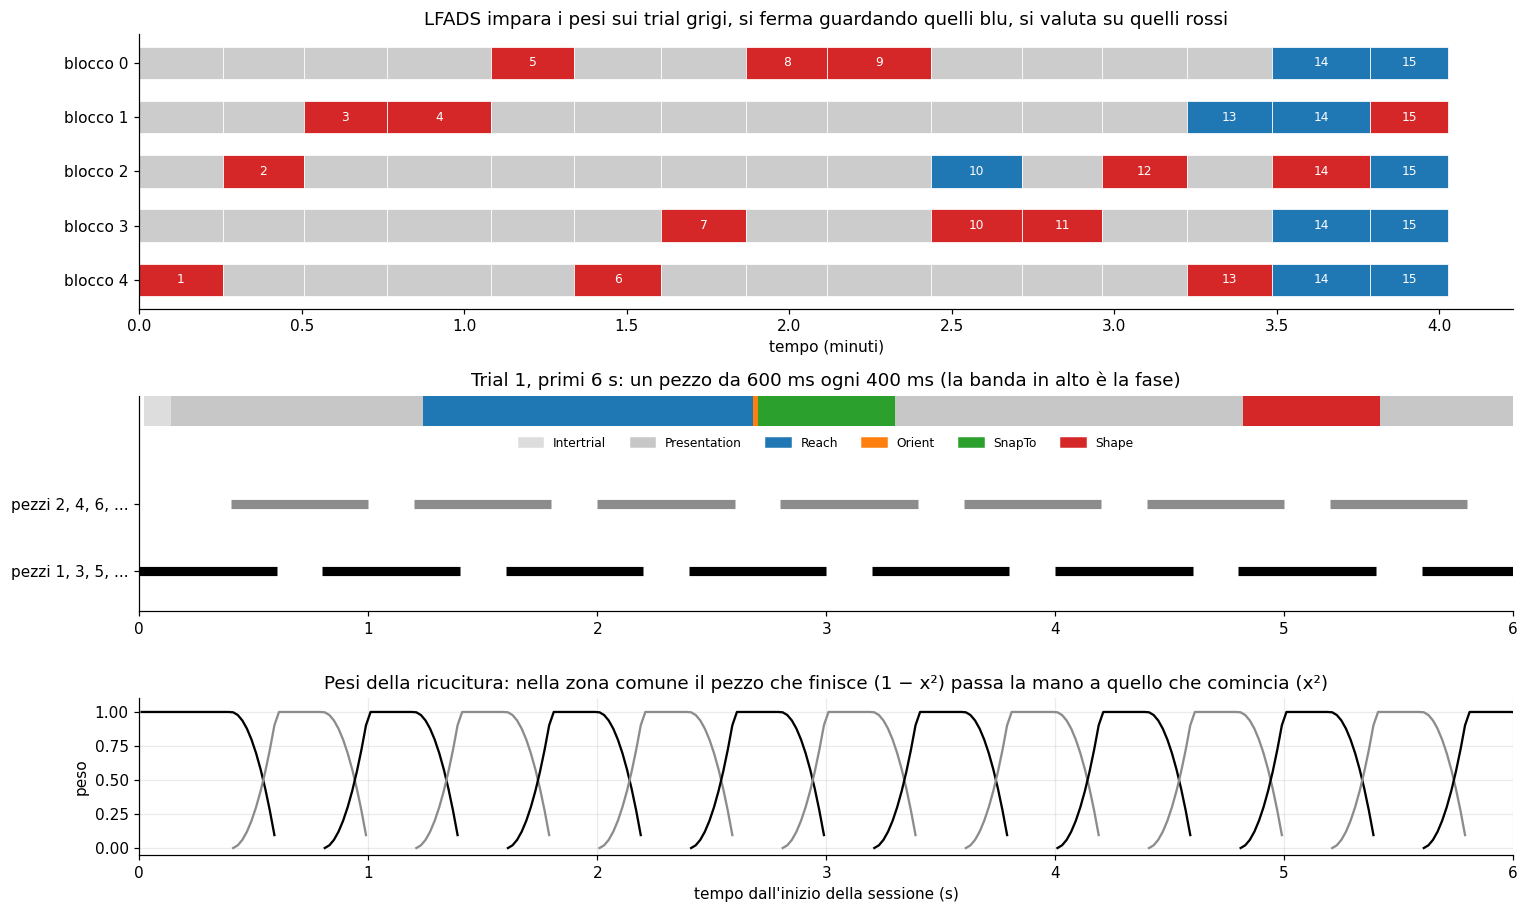

In [53]:
fig = plt.figure(figsize=(14, 8.4))
gs = fig.add_gridspec(3, 1, height_ratios=(1.4, 1.1, 0.8))
ax = fig.add_subplot(gs[0])                                 # in alto: chi fa che cosa in ogni blocco
t_min = np.arange(n_bins) * io.BIN_S / 60                   # tempo di ogni bin, in minuti
for k, (tt, vt) in enumerate(zip(TEST_TRIALS, VAL_LF)):
    for t_ in TRIALS:                                       # un rettangolo per trial: grigio = impara, blu = validazione, rosso = test
        a0, a1 = TRIAL_SPAN[t_]
        col = "C3" if t_ in tt else ("C0" if t_ in vt else "0.8")
        ax.barh(k, (a1 - a0) * io.BIN_S / 60, left=t_min[a0], height=0.6, color=col, edgecolor="white", lw=0.5)
        if t_ in tt or t_ in vt:
            ax.text(t_min[a0] + (a1 - a0) * io.BIN_S / 120, k, str(t_), ha="center", va="center", fontsize=8, color="white")
ax.set(yticks=range(5), yticklabels=[f"blocco {k}" for k in range(5)], xlabel="tempo (minuti)",
       title="LFADS impara i pesi sui trial grigi, si ferma guardando quelli blu, si valuta su quelli rossi")
ax.invert_yaxis(); ax.grid(False)

t0_ = TRIALS[0]; a0_ = TRIAL_SPAN[t0_][0]                   # al centro: i primi 6 s del primo trial, con i suoi pezzi
show_n = 300                                                # 300 bin = 6 s
ax2 = fig.add_subplot(gs[1])
for b_ in range(a0_, a0_ + show_n):                         # la fase di ogni bin, come banda colorata in alto
    ax2.axvspan(b_ * io.BIN_S, (b_ + 1) * io.BIN_S, ymin=0.86, ymax=1, color=io.PHASE_COLORS.get(phase[b_], "white"), lw=0)
SEG_COL = ("k", "0.55")                                     # i pezzi in nero e in grigio, alternati (i colori sono già usati dalle fasi)
for i, a in enumerate(SEG_START[t0_]):                      # un segmento orizzontale per pezzo, su due righe alternate
    if a < a0_ + show_n:
        ax2.plot([a * io.BIN_S, (a + SEG_LEN) * io.BIN_S], [i % 2, i % 2], color=SEG_COL[i % 2], lw=6, solid_capstyle="butt")
ax2.set(ylim=(-0.6, 2.6), yticks=[0, 1], yticklabels=["pezzi 1, 3, 5, ...", "pezzi 2, 4, 6, ..."],
        xlim=(a0_ * io.BIN_S, (a0_ + show_n) * io.BIN_S),
        title=f"Trial {t0_}, primi 6 s: un pezzo da 600 ms ogni 400 ms (la banda in alto è la fase)")
ph_show = [p for p in ["Intertrial", "Presentation", *io.MOVEMENT_PHASES] if p in set(phase[a0_:a0_ + show_n])]  # le fasi presenti, nell'ordine del task
handles = [plt.Rectangle((0, 0), 1, 1, color=io.PHASE_COLORS[p]) for p in ph_show]
ax2.legend(handles, ph_show, loc="upper center", bbox_to_anchor=(0.5, 0.86), fontsize=8, ncol=len(ph_show), frameon=False)
ax2.grid(False)

ax3 = fig.add_subplot(gs[2], sharex=ax2)                    # in basso: il peso di ogni pezzo nella ricucitura
W_ = segment_weights(len(SEG_START[t0_]))
for i, (a, w) in enumerate(zip(SEG_START[t0_], W_)):
    if a < a0_ + show_n:
        ax3.plot((a + np.arange(SEG_LEN) + 0.5) * io.BIN_S, w, color=SEG_COL[i % 2], lw=1.5)
ax3.set(xlabel="tempo dall'inizio della sessione (s)", ylabel="peso", ylim=(-0.05, 1.1),
        title="Pesi della ricucitura: nella zona comune il pezzo che finisce (1 − x²) passa la mano a quello che comincia (x²)")
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_data.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **`eval_mask` esclude quasi soltanto `SnapTo`**: 290 dei suoi 291 bin, più 17 bin di pausa. Dei
  1106 punti di valutazione, 58 (il 5%) sono di `SnapTo`.
- **Più di metà della sessione è pausa**: 6672 bin di `Presentation` su 12233. Come CEBRA (§1.4),
  LFADS dovrà descrivere anche le pause, che non valutiamo.
- **La figura.** In alto: in ogni blocco LFADS impara sui trial grigi, si ferma guardando i due blu
  (sempre verso la fine della sessione) e si valuta sui tre rossi. Al centro: un pezzo da 600 ms ogni
  400 ms, su due righe per vederli separati; un pezzo contiene spesso un cambio di fase. In basso: i
  pesi della ricucitura, che si passano la mano in modo graduale nei 200 ms in comune; il primo pezzo
  del trial comincia con peso pieno, perché prima non c'è nessun pezzo.

### Riepilogo del §9

| decisione | scelta | perché | alternative (dove) |
|---|---|---|---|
| ingresso | conteggi grezzi a 20 ms, 160 canali (gli stessi della GPFA) | LFADS ha un suo modello del rumore (Poisson) | — |
| taglio | pezzi da 600 ms ogni 400 ms, dentro ogni trial; 610 pezzi | lo schema di AutoLFADS e del benchmark per le registrazioni continue | 400 ms, 1 s (§14) |
| ricucitura | media pesata con le rampe di AutoLFADS (1 − x², x²) | passaggio graduale tra pezzi; verificata a mano sui conteggi | — |
| split | i 5 blocchi del 03; in ogni blocco 10 trial per i pesi, 2 di validazione (l'ultimo pari e l'ultimo dispari), 3 di test | stessi trial di test di tutto il notebook; validazione con le due versioni | seconda coppia di validazione (§11) |
| canali nascosti | 40 su 160, 10 per fascia di frequenza, seme fisso | misura generativa del §12, come nel benchmark | — |
| `SnapTo` | tenuta nell'allenamento e nel metro comune | LFADS descrive l'attività, non il movimento; confrontabilità con il 03 | metro comune senza `SnapTo` (§12) |

**Che cosa non abbiamo verificato**: se la validazione alla fine della sessione è rappresentativa
(§11); come si comportano le uscite di LFADS alle cuciture (§11); se 600 ms sia la lunghezza migliore
per questi dati (§14).

In [54]:
# REPLICA: solo le definizioni della cella tolta 114
SIGMA_L, RHO_L, BETA_L = 10.0, 28.0, 8 / 3

DT_BIN, N_SUB = 0.015, 10

T_LZ, N_NEU = 10_000, 30

def lorenz_step(v, dt):                                     # un passo di Eulero: stato nuovo = stato + dt × (velocità data dalle regole di Lorenz)
    x, y, z = v
    return v + dt * np.array([SIGMA_L * (y - x), x * (RHO_L - z) - y, x * y - BETA_L * z])

LZ_PARTS = {"impara": (0, 8_000), "validazione": (8_000, 9_000), "test": (9_000, 10_000)}

def nll_sum(k, lam):                                        # errore di Poisson totale, senza log k! (è uguale per tutti i modelli e si cancella nei confronti)
    return np.sum(lam - k * np.log(lam))

In [55]:
# REPLICA: solo le definizioni della cella tolta 117
def sigmoid(x):                                             # la funzione a "S" tra 0 e 1, usata dalle porte
    return 1 / (1 + np.exp(-x))

def gru_step(x, h, w, name, clip):                          # un passo della GRU di lfads-torch (ClippedGRUCell): ingresso x, stato h, pesi w[name + ...]
    H = h.shape[1]                                          # dimensione dello stato
    W_ih, b_ih = w[name + "weight_ih"], w[name + "bias_ih"] # pesi dell'ingresso (per le 3 porte, una sopra l'altra) e loro livelli
    W_hh, b_hh = w[name + "weight_hh"], w[name + "bias_hh"] # pesi dello stato precedente, e loro livelli
    x_z, x_r, x_n = np.split(x @ W_ih.T + b_ih, 3, axis=1)  # il contributo dell'ingresso alle porte z, r e alla proposta n (in quest'ordine)
    h_z, h_r = np.split(h @ W_hh[:2 * H].T + b_hh[:2 * H], 2, axis=1)  # il contributo dello stato precedente alle porte z e r
    z = sigmoid(x_z + h_z)                                  # porta di aggiornamento: quanto tenere dello stato vecchio (da 0 a 1)
    r = sigmoid(x_r + h_r)                                  # porta di reset: quanto dello stato vecchio usare per fare la proposta
    n = np.tanh(x_n + (r * h) @ W_hh[2 * H:].T + b_hh[2 * H:])  # la proposta di stato nuovo (r moltiplica lo stato PRIMA dei pesi)
    return np.clip(z * h + (1 - z) * n, -clip, clip)

def lfads_forward_np(data, w, hp):
    """LFADS a mano: dai conteggi (pezzi × bin × neuroni) a condizione iniziale, stati, fattori e log-frequenze.
    Versione di valutazione: si usa la media della condizione iniziale e nessun dropout."""
    B, T, _ = data.shape                                    # pezzi, bin per pezzo, neuroni
    clip = hp["cell_clip"]
    h_f = np.tile(w["encoder.ic_enc_h0"][0], (B, 1))        # 1. encoder: stato di partenza della GRU che legge in avanti (un parametro imparato)...
    h_b = np.tile(w["encoder.ic_enc_h0"][1], (B, 1))        # ...e di quella che legge all'indietro
    for t in range(T):                                      # dal primo bin all'ultimo
        h_f = gru_step(data[:, t], h_f, w, "encoder.ic_enc.fwd_gru.cell.", clip)
    for t in reversed(range(T)):                            # dall'ultimo bin al primo
        h_b = gru_step(data[:, t], h_b, w, "encoder.ic_enc.bwd_gru.cell.", clip)
    summary = np.concatenate([h_f, h_b], axis=1)            # il riassunto del pezzo: i due stati finali, uno accanto all'altro
    ic_params = summary @ w["encoder.ic_linear.weight"].T + w["encoder.ic_linear.bias"]  # 2. condizione iniziale: una trasformazione lineare...
    ic_mean, ic_logvar = np.split(ic_params, 2, axis=1)     # ...che dà la media e il logaritmo della varianza
    ic_std = np.sqrt(np.exp(ic_logvar) + hp["ic_post_var_min"])  # l'incertezza (deviazione standard), mai sotto un minimo
    g = ic_mean @ w["decoder.ic_to_g0.weight"].T + w["decoder.ic_to_g0.bias"]  # 3. generatore: lo stato di partenza g₀, dalla media della condizione iniziale
    W_fac = w["decoder.rnn.cell.fac_linear.weight"]         # 4. le direzioni dei fattori nello stato del generatore...
    W_fac = W_fac / np.linalg.norm(W_fac, axis=1, keepdims=True)  # ...ognuna normalizzata a lunghezza 1 (KernelNormalizedLinear)
    no_input = np.zeros((B, 0))                             # il generatore non ha ingressi: un ingresso "vuoto" (0 colonne)
    gen, fac = [], []
    for t in range(T):                                      # bin dopo bin, solo le regole del generatore
        g = gru_step(no_input, g, w, "decoder.rnn.cell.gen_cell.", clip)  # senza ingresso, x @ W_ih vale 0: restano i livelli b_ih
        gen.append(g)
        fac.append(g @ W_fac.T)                             # i fattori del bin
    gen, fac = np.stack(gen, 1), np.stack(fac, 1)           # (pezzi, bin, 64) e (pezzi, bin, 10)
    log_rates = fac @ w["readout.0.weight"].T + w["readout.0.bias"]  # 5. log-frequenze: combinazione lineare dei fattori più un livello per neurone
    return {"ic_mean": ic_mean, "ic_std": ic_std, "gen_states": gen, "factors": fac, "log_rates": log_rates}

In [56]:
# REPLICA: solo le definizioni della cella tolta 119
from joblib.externals.loky import ProcessPoolExecutor

def make_lfads(hp):
    """Un LFADS della libreria lfads-torch costruito dai parametri hp, senza controller. Si chiama nel processo separato."""
    import numpy as np                                      # numpy PRIMA di torch: altrimenti Python si chiude (§10.3)
    import torch
    from torch import nn
    from lfads_torch.model import LFADS                     # il modello della libreria
    from lfads_torch.modules import augmentations           # il coordinated dropout
    from lfads_torch.modules.priors import MultivariateNormal, Null  # la distribuzione a priori della condizione iniziale; "nessuna" per il controller
    from lfads_torch.modules.recons import Poisson          # il modello del rumore: Poisson
    from lfads_torch.modules.readin_readout import FanInLinear  # l'uscita lineare dai fattori alle log-frequenze
    cd = augmentations.CoordinatedDropout(cd_rate=hp["cd_rate"], cd_pass_rate=0.0, ic_enc_seq_len=0)
    return LFADS(encod_data_dim=hp["n_in"], encod_seq_len=hp["seg_len"], recon_seq_len=hp["seg_len"],  # forma dei dati
                 ext_input_dim=0, ic_enc_seq_len=0,         # nessun ingresso esterno; l'encoder legge tutto il pezzo
                 ic_enc_dim=hp["enc_dim"], ci_enc_dim=0, ci_lag=1, con_dim=0, co_dim=0,  # encoder; controller spento (dimensioni 0)
                 ic_dim=hp["ic_dim"], gen_dim=hp["gen_dim"], fac_dim=hp["fac_dim"], dropout_rate=hp["dropout"],
                 reconstruction=nn.ModuleList([Poisson()]), variational=True, co_prior=Null(),
                 ic_prior=MultivariateNormal(mean=0.0, variance=hp["ic_prior_var"], shape=hp["ic_dim"]),
                 ic_post_var_min=hp["ic_post_var_min"], cell_clip=hp["cell_clip"],
                 train_aug_stack=augmentations.AugmentationStack([cd], batch_order=[0], loss_order=[0]),  # coordinated dropout solo in allenamento
                 infer_aug_stack=augmentations.AugmentationStack(),
                 readin=nn.ModuleList([nn.Identity()]), readout=nn.ModuleList([FanInLinear(hp["fac_dim"], hp["n_out"])]),
                 loss_scale=hp["loss_scale"], recon_reduce_mean=True,  # errore di ricostruzione come media su pezzi, bin e neuroni
                 lr_scheduler=False, lr_init=hp["lr"], lr_stop=1e-5, lr_decay=0.95, lr_patience=6,
                 lr_adam_beta1=0.9, lr_adam_beta2=0.999, lr_adam_epsilon=1e-8, weight_decay=0.0,
                 l2_start_epoch=0, l2_increase_epoch=hp["ramp_epochs"], l2_ic_enc_scale=hp["l2_ic_enc_scale"],
                 l2_ci_enc_scale=0.0, l2_gen_scale=hp["l2_gen_scale"], l2_con_scale=0.0,
                 kl_start_epoch=0, kl_increase_epoch=hp["ramp_epochs"], kl_ic_scale=hp["kl_ic_scale"], kl_co_scale=0.0)

def lfads_library_check(hp, seed, data):
    """Nel processo separato: un modello della libreria con i pesi iniziali (seme `seed`), le sue uscite e il suo costo su `data`."""
    import numpy as np                                      # numpy PRIMA di torch
    import torch
    from lfads_torch.tuples import SessionBatch             # il formato dei dati della libreria
    from lfads_torch.modules.l2 import compute_l2_penalty   # la penalità L2 della libreria
    torch.set_num_threads(1)                                # un solo thread di CPU (§10b: di più non serve)
    torch.manual_seed(seed)                                 # seme dei pesi iniziali
    model = make_lfads(hp)
    model.eval()                                            # modalità di valutazione: niente dropout
    model.log = model.log_dict = lambda *a, **k: None       # fuori dall'allenatore di Lightning non c'è dove scrivere le misure
    X = torch.tensor(data, dtype=torch.float32)
    batch = SessionBatch(encod_data=X, recon_data=X, ext_input=torch.zeros(len(X), X.shape[1], 0),
                         truth=torch.zeros(0), sv_mask=torch.ones_like(X))  # ingresso = dati da ricostruire; nessun ingresso esterno
    with torch.no_grad():                                   # niente derivate: solo il calcolo in avanti
        out = model({0: batch}, sample_posteriors=False, output_means=False)[0]  # tutte le uscite, con la media della condizione iniziale
        recon = model.recon[0].compute_loss(X, out.output_params).mean()  # errore di ricostruzione (Poisson) della libreria
        kl = model.ic_prior(out.ic_mean, out.ic_std)        # termine KL della libreria
        l2 = compute_l2_penalty(model, model.hparams)       # penalità L2 della libreria
        model.hparams.variational = False                   # per il controllo: il costo con la media, senza estrazioni a caso
        total = model._shared_step({0: (batch, ())}, 0, "valid")  # il costo totale, calcolato dalla funzione che la libreria usa in allenamento
    w = {k: v.detach().numpy().astype(np.float64) for k, v in model.state_dict().items()}  # tutti i pesi, come array numpy
    return {"weights": w, "ic_mean": out.ic_mean.numpy(), "ic_std": out.ic_std.numpy(), "gen_states": out.gen_states.numpy(),
            "factors": out.factors.numpy(), "log_rates": out.output_params[..., 0].numpy(),
            "recon": float(recon), "kl": float(kl), "l2": float(l2), "total": float(total)}

OUT_NAMES = {"ic_mean": "condizione iniziale: media", "ic_std": "condizione iniziale: incertezza",
             "gen_states": "stati del generatore", "factors": "fattori", "log_rates": "log-frequenze"}

In [57]:
# REPLICA: solo le definizioni della cella tolta 121
from scipy.special import gammaln

def stirling(k):                                            # l'approssimazione di log k! usata da PyTorch (full=True): solo per k > 1, altrimenti 0
    k_safe = np.where(k > 1, k, 1.0)                        # per k ≤ 1 un valore qualunque, che poi non si usa (evita log 0)
    return np.where(k > 1, k_safe * np.log(k_safe) - k_safe + 0.5 * np.log(2 * np.pi * k_safe), 0.0)

def poisson_nll(k, log_rate, exact=True):                   # errore di Poisson di ogni bin e neurone: λ − k log λ + log k!
    return np.exp(log_rate) - k * log_rate + (gammaln(k + 1) if exact else stirling(k))

def kl_normal(mu, sd, prior_mean, prior_var):               # KL tra la condizione iniziale (μ, σ) e quella a priori, sommato sulle dimensioni, medio sui pezzi
    sp = np.sqrt(prior_var)
    return np.mean(np.sum(np.log(sp / sd) + (sd ** 2 + (mu - prior_mean) ** 2) / (2 * prior_var) - 0.5, axis=1))

def l2_gen(w, hp):                                          # penalità L2 della libreria: ½ ‖pesi ricorrenti‖², per il suo peso, diviso il numero di pesi
    terms = [(w["decoder.rnn.cell.gen_cell.weight_hh"], hp["l2_gen_scale"]),
             (w["encoder.ic_enc.fwd_gru.cell.weight_hh"], hp["l2_ic_enc_scale"]),
             (w["encoder.ic_enc.bwd_gru.cell.weight_hh"], hp["l2_ic_enc_scale"])]
    used = [(W_, s_) for W_, s_ in terms if s_ > 0]         # come la libreria: solo i pesi con una penalità diversa da 0
    return sum(s_ * 0.5 * np.sum(W_ ** 2) for W_, s_ in used) / (sum(W_.size for W_, _ in used) + 1e-8)

In [58]:
# REPLICA: solo le definizioni della cella tolta 124
import copy

CLIP_LF = 200 / 1e4

def lfads_fit(hp, seed, train, val, apply, watch=None, max_epochs=1000, patience=200, batch_size=64, clip=CLIP_LF,
              device="cpu", model_path=None, rate_cols=None):
    """Allena un LFADS della libreria (make_lfads) sui pezzi `train` (pezzi × bin × neuroni) e sceglie la versione con
    l'errore più basso sui pezzi `val`. Restituisce, per ogni array di `apply`, fattori e frequenze (media della
    condizione iniziale, senza dropout; delle frequenze solo le colonne rate_cols, se indicate), la storia
    dell'allenamento e i pesi. watch = {nome: (pezzi, frequenze vere o None[, colonne nascoste all'encoder])}: altre
    misure a ogni epoca (errore, bit per spike, R² con la verità). Gira nel processo separato."""
    import copy, time                                       # copia della versione migliore; durata
    import numpy as np                                      # numpy PRIMA di torch (§10.3)
    import torch
    from lfads_torch.tuples import SessionBatch             # il formato dei dati della libreria
    torch.set_num_threads(1)                                # un thread: i calcoli sono piccoli (§10.8)
    torch.manual_seed(seed)                                 # pesi iniziali, coordinated dropout, dropout, estrazioni della condizione iniziale
    rng = np.random.default_rng(seed)                       # l'ordine dei pezzi in ogni epoca
    model = make_lfads(hp)
    model.__class__ = type("LFADSconEpoca", (type(model),), {"current_epoch": 0})  # un numero d'epoca che possiamo scrivere noi (per le rampe)
    model = model.to(device)
    model.log = model.log_dict = lambda *a, **k: None       # fuori da Lightning non c'è dove scrivere le misure
    opt = model.configure_optimizers()                      # AdamW con il passo di apprendimento di hp, come la libreria
    n_in = hp["n_in"]                                       # i neuroni che l'encoder vede (i primi n_in; al §12 non saranno tutti)

    def as_batch(X):                                        # pezzi numpy -> il formato della libreria
        Xt = torch.tensor(X, dtype=torch.float32, device=device)
        return SessionBatch(encod_data=Xt[..., :n_in], recon_data=Xt,  # l'encoder vede i primi n_in neuroni, si ricostruiscono tutti
                            ext_input=torch.zeros(len(Xt), Xt.shape[1], 0, device=device),
                            truth=torch.zeros(0), sv_mask=torch.ones_like(Xt))

    def evaluate(X, chunk=256):                             # fattori, log-frequenze ed errore medio, con la media della condizione iniziale e senza dropout
        model.eval()
        fac, logr, err = [], [], []
        with torch.no_grad():
            for i in range(0, len(X), chunk):
                sb = as_batch(X[i:i + chunk])
                out = model({0: sb}, sample_posteriors=False, output_means=False)[0]
                fac.append(out.factors.cpu().numpy())
                logr.append(out.output_params[..., 0].cpu().numpy())
                err.append(model.recon[0].compute_loss(sb.recon_data, out.output_params).sum().item())  # errore di Poisson della libreria (Stirling)
        return np.concatenate(fac), np.concatenate(logr), sum(err) / X.size

    def bits(logr, X, cols):                                # bit per spike sulle colonne cols: guadagno sulla frequenza media di ogni canale in questi dati (§9.4)
        k, lr = X[..., cols].reshape(-1, len(cols)), logr[..., cols].reshape(-1, len(cols))
        lam0 = np.maximum(k.mean(0), 1e-9)                  # la frequenza media di ogni canale (mai esattamente 0)
        nll_model = np.sum(np.exp(lr) - k * lr)             # errore di Poisson del modello (senza log k!, che si cancella)
        nll_null = np.sum(lam0 - k * np.log(lam0))          # errore di chi conosce solo la media
        return float((nll_null - nll_model) / k.sum() / np.log(2))

    def r2_rates(logr, truth):                              # R² tra le frequenze del modello e quelle vere, medio sui neuroni
        p_, t_ = np.exp(logr).reshape(-1, truth.shape[-1]), truth.reshape(-1, truth.shape[-1])
        return float(np.mean(1 - ((t_ - p_) ** 2).sum(0) / ((t_ - t_.mean(0)) ** 2).sum(0)))

    hist, best_err, best_state, best_epoch = [], np.inf, None, 0
    t0, steps = time.time(), 0
    for epoch in range(1, max_epochs + 1):
        model.current_epoch = epoch - 1                     # la libreria conta le epoche da 0
        model.train()                                       # modalità di allenamento: dropout acceso
        order = rng.permutation(len(train))                 # i pezzi in un ordine nuovo a ogni epoca
        costs = []
        for i in range(0, len(train), batch_size):          # a gruppi da 64 pezzi
            loss = model._shared_step({0: (as_batch(train[order[i:i + batch_size]]), ())}, i, "train")  # il costo della libreria (con CD ed estrazione a caso)
            opt.zero_grad()                                 # azzera le derivate del passo precedente
            loss.backward()                                 # le derivate del costo rispetto a tutti i pesi
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip)  # taglio delle derivate troppo lunghe
            opt.step()                                      # un passo di AdamW
            costs.append(loss.item()); steps += 1
        val_err = evaluate(val)[2]                          # errore sui pezzi di validazione
        row = {"epoca": epoch, "costo di training": float(np.mean(costs)), "errore, validazione": val_err}
        for name, (Xw, truth, *hid) in (watch or {}).items():  # misure in più (per i dati sintetici, anche la distanza dalla verità)
            _, lw, ew = evaluate(Xw)
            row[f"errore, {name}"] = ew
            if truth is not None:
                row[f"R² frequenze, {name}"] = r2_rates(lw, truth)
            if hid:                                         # canali nascosti all'encoder: bit per spike separati per visibili e nascosti
                vis = np.setdiff1d(np.arange(Xw.shape[-1]), hid[0])
                row[f"bit per spike visibili, {name}"] = bits(lw, Xw, vis)
                row[f"bit per spike nascosti, {name}"] = bits(lw, Xw, np.asarray(hid[0]))
            else:
                row[f"bit per spike, {name}"] = bits(lw, Xw, np.arange(Xw.shape[-1]))
        hist.append(row)
        if epoch >= hp["ramp_epochs"] and val_err < best_err:  # dopo le rampe: teniamo la versione migliore sulla validazione
            best_err, best_state, best_epoch = val_err, copy.deepcopy(model.state_dict()), epoch
        if best_epoch > 0 and epoch - best_epoch >= patience:  # 200 epoche senza miglioramenti: ci si ferma
            break
    if best_state is not None:
        model.load_state_dict(best_state)                   # la versione migliore
    seconds = time.time() - t0
    if model_path is not None:
        torch.save(model.state_dict(), model_path)          # il modello, su disco
    outs = [evaluate(X)[:2] for X in apply]                 # fattori e log-frequenze di ogni array da proiettare
    keep = slice(None) if rate_cols is None else np.asarray(rate_cols)  # quali frequenze tenere (per non riempire il disco)
    return {"factors": [f_.astype(np.float32) for f_, _ in outs], "rates": [np.exp(l_[..., keep]).astype(np.float32) for _, l_ in outs],
            "history": hist, "best_epoch": best_epoch, "epochs": len(hist), "steps": steps, "seconds": seconds,
            "weights": {k: v.detach().cpu().numpy() for k, v in model.state_dict().items()}}

def lf_key(job):                                            # impronta di un allenamento LFADS: cambia se cambia qualunque cosa che lo determina
    h = hashlib.sha1()
    for f in (lfads_fit, make_lfads):
        h.update(inspect.getsource(f).encode())             # il codice
    h.update(json.dumps({k: job.get(k) for k in ("hp", "seed", "max_epochs", "patience", "batch_size", "clip", "device", "rate_cols")},
                        sort_keys=True, default=str).encode())  # parametri, seme, regole dell'allenamento, frequenze tenute
    arrays = [job["train"], job["val"], *job["apply"]]      # i dati...
    for name, (Xw, truth, *hid) in sorted((job.get("watch") or {}).items()):
        h.update(name.encode()); arrays += [Xw] + ([] if truth is None else [truth]) + [np.asarray(c_) for c_ in hid]  # ...e quelli delle misure in più
    for a in arrays:
        h.update(np.ascontiguousarray(a).tobytes())
    return h.hexdigest()[:16]

def run_lfads_cached(jobs):                                 # esegue gli allenamenti che non sono già su disco, 4 alla volta; poi rilegge tutto dal disco
    keys = [lf_key(j) for j in jobs]
    todo = [i for i, k in enumerate(keys) if RETRAIN or not (CACHE_LF / f"{k}.npz").exists()]
    futures = {i: POOL_LF.submit(lfads_fit, **dict(jobs[i], model_path=CACHE_LF / f"{keys[i]}.pt")) for i in todo}
    for i, fut in futures.items():                          # i risultati nuovi si salvano appena arrivano
        r = fut.result()
        np.savez(CACHE_LF / f"{keys[i]}.npz", history=json.dumps(r["history"]),
                 info=json.dumps({k: r[k] for k in ("best_epoch", "epochs", "steps", "seconds")}),
                 **{f"factors_{j}": f_ for j, f_ in enumerate(r["factors"])}, **{f"rates_{j}": x_ for j, x_ in enumerate(r["rates"])})
        np.savez(CACHE_LF / f"{keys[i]}_w.npz", **r["weights"])  # i pesi, anche come array numpy (per il calcolo a mano)
    out = []
    for k in keys:                                          # tutti i risultati, nell'ordine dei lavori, letti dal disco
        z, zw = np.load(CACHE_LF / f"{k}.npz"), np.load(CACHE_LF / f"{k}_w.npz")
        n_ = sum(f_.startswith("factors_") for f_ in z.files)
        out.append({"factors": [z[f"factors_{j}"] for j in range(n_)], "rates": [z[f"rates_{j}"] for j in range(n_)],
                    "history": pd.DataFrame(json.loads(str(z["history"]))).set_index("epoca"),
                    **json.loads(str(z["info"])), "weights": {f_: zw[f_] for f_ in zw.files}, "key": k})
    print(f"Allenamenti LFADS: {len(todo)} eseguiti ora, {len(jobs) - len(todo)} riletti dal disco")
    return out

In [59]:
# REPLICA: solo le definizioni della cella tolta 126
def syn_job(hp, seed):                                      # un allenamento sui dati sintetici
    return dict(hp=hp, seed=seed, train=LZ_SEGS["impara"], val=LZ_SEGS["validazione"],
                apply=[LZ_SEGS[k] for k in LZ_PARTS], watch=LZ_WATCH)

SYN_RUNS = [("con CD", 0), ("con CD", 1), ("con CD", 2), ("senza CD", 0)]

In [60]:
# REPLICA: solo le definizioni della cella tolta 129
from sklearn.linear_model import PoissonRegressor

def stitch_at(Y_seg, starts, a0, a1):                       # la ricucitura del §9.2 per un tratto qualunque [a0, a1) con i pezzi che cominciano in `starts`
    num, den = np.zeros((a1 - a0, Y_seg.shape[2])), np.zeros((a1 - a0, 1))
    for a, y, w in zip(np.asarray(starts) - a0, Y_seg, segment_weights(len(Y_seg))):
        num[a:a + SEG_LEN] += w[:, None] * y
        den[a:a + SEG_LEN] += w[:, None]
    return num / den

def stitch_lz(per_part):                                    # ricuce le uscite delle tre parti (impara, validazione, test) e le mette in fila: 10 000 bin
    return np.concatenate([stitch_at(Y, LZ_START[k], *LZ_PARTS[k]) for k, Y in zip(LZ_PARTS, per_part)])

def gpfa_seqs(segs):                                        # pezzi di conteggi -> il formato di elephant, con la radice dei conteggi (come nel 03 e nel §7b)
    return np.array([(s_.shape[0], np.sqrt(s_.astype(float)).T) for s_ in segs], dtype=[("T", int), ("y", "O")])

def gpfa_fit_segments(segs, x_dim):                         # GPFA con x_dim fattori stimata sui pezzi dati
    np.random.seed(0)                                       # punto di partenza fisso
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
        params, _ = gpfa_core.fit(gpfa_seqs(segs), x_dim=x_dim, bin_width=20.0, em_max_iters=500, tau_init=100.0)
    return params

def gpfa_sqrt_pred(segs, params):                           # la previsione μ = C x + d della GPFA per la radice dei conteggi, in ogni pezzo: (pezzi, bin, neuroni)
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
        lat, _ = gpfa_core.exact_inference_with_ll(gpfa_seqs(segs), params, get_ll=False)
    return np.stack([(params["C"] @ x_ + params["d"][:, None]).T for x_ in lat["latent_variable"]])

def gpfa_infer_segments(segs, params):                      # i fattori ordinati (orthonormalize) di ogni pezzo: (pezzi, bin, fattori)
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
        lat, _ = gpfa_core.exact_inference_with_ll(gpfa_seqs(segs), params, get_ll=False)
        _, orth = gpfa_core.orthonormalize(params, lat)
    return np.stack([x_.T for x_ in orth["latent_variable_orth"]])

def lorenz_r2(F):                                           # R² delle 3 variabili di Lorenz ricavate linearmente da F (stimato sul training, giudicato sul test)
    reg = LinearRegression().fit(F[FIT_LZ], LZ_Z[FIT_LZ])
    return r2_score(LZ_Z[TEST_LZ], reg.predict(F[TEST_LZ]), multioutput="raw_values")

def rate_r2(R):                                             # R² tra frequenze stimate e vere sul test, medio sui 30 neuroni
    return float(np.mean(r2_score(RATE_LZ[TEST_LZ], R[TEST_LZ], multioutput="raw_values")))

def rate_corr(R):                                           # correlazione tra frequenze stimate e vere sul test, media sui 30 neuroni
    return float(np.mean([np.corrcoef(RATE_LZ[TEST_LZ, n], R[TEST_LZ, n])[0, 1] for n in range(N_NEU)]))

def glm_rates(F):                                           # frequenze da una regressione di Poisson per neurone, dai fattori agli spike, stimata sul training
    sc = StandardScaler().fit(F[FIT_LZ])
    Fs = sc.transform(F)
    return np.column_stack([PoissonRegressor(alpha=1e-4, max_iter=1000).fit(Fs[FIT_LZ], SPK_LZ[FIT_LZ, n]).predict(Fs)
                            for n in range(N_NEU)])

def lz_row(F, R):                                           # una riga della tabella: stato (da F) e frequenze (R)
    return {**dict(zip("xyz", lorenz_r2(F))), "frequenze: R²": rate_r2(R), "frequenze: correlazione": rate_corr(R)}

def cell_fmt(vals):                                         # "media (minimo-massimo)" se ci sono più semi
    vals = np.array([x_ for x_ in vals if x_ is not None and not np.isnan(x_)])
    if len(vals) == 0:
        return ""
    return f"{vals.mean():.3f}" if len(vals) == 1 else f"{vals.mean():.3f} ({vals.min():.3f}-{vals.max():.3f})"

COLS_LZ = ["x", "y", "z", "frequenze: R²", "frequenze: correlazione"]

In [61]:
# REPLICA: solo le definizioni della cella tolta 132
def seam_gap(Fseg, starts):                                 # nelle zone comuni a due pezzi consecutivi: differenza media tra i loro fattori, in deviazioni standard
    sd_ = Fseg.reshape(-1, Fseg.shape[2]).std(0)
    gaps = []
    for i in range(len(starts) - 1):
        ov = starts[i] + SEG_LEN - starts[i + 1]            # quanti bin hanno in comune
        if ov > 0:
            gaps.append(np.abs(Fseg[i, -ov:] - Fseg[i + 1, :ov]) / sd_)
    return float(np.mean(np.concatenate(gaps)))

def stitch_test_w(Y_seg, W):                                # ricucitura dei pezzi di test con pesi dati
    a0, a1 = LZ_PARTS["test"]
    num, den = np.zeros((a1 - a0, Y_seg.shape[2])), np.zeros((a1 - a0, 1))
    for a, y, w in zip(st_test - a0, Y_seg, W):
        num[a:a + SEG_LEN] += w[:, None] * y
        den[a:a + SEG_LEN] += w[:, None]
    return num / den

def lfads_step_time(hp, device, n_steps=30, n_seg=256, seed=0):
    """Millisecondi per passo di allenamento (mediana dopo 5 passi di riscaldamento), su dati finti della forma di hp."""
    import time
    import numpy as np                                      # numpy PRIMA di torch
    import torch
    from lfads_torch.tuples import SessionBatch
    torch.set_num_threads(1); torch.manual_seed(seed)
    model = make_lfads(hp)
    model.__class__ = type("LFADSconEpoca", (type(model),), {"current_epoch": 0})
    model = model.to(device); model.train()
    model.log = model.log_dict = lambda *a, **k: None
    opt = model.configure_optimizers()
    X = torch.tensor(np.random.default_rng(seed).poisson(0.2, size=(n_seg, hp["seg_len"], hp["n_out"])), dtype=torch.float32, device=device)
    times = []
    for s_ in range(n_steps):
        idx = torch.randint(0, n_seg, (64,), device=device)
        sb = SessionBatch(X[idx][..., :hp["n_in"]], X[idx], torch.zeros(64, hp["seg_len"], 0, device=device), torch.zeros(0), torch.ones_like(X[idx]))
        t0 = time.time()
        loss = model._shared_step({0: (sb, ())}, s_, "train")
        opt.zero_grad(); loss.backward(); opt.step()
        if device == "mps":
            torch.mps.synchronize()                         # sulla GPU i calcoli sono asincroni: si aspetta che finiscano
        times.append(time.time() - t0)
    return float(np.median(times[5:]) * 1000)

In [62]:
# REPLICA: le impostazioni di LFADS definite nelle celle tolte del §10 (stessi valori)
from joblib.externals.loky import ProcessPoolExecutor
POOL_LF = ProcessPoolExecutor(max_workers=6)                # REPLICA: 6 processi invece di 4 (un thread ciascuno, come nel 04): stessi risultati, più core
CACHE_LF = CACHE / "lfads"
CACHE_LF.mkdir(parents=True, exist_ok=True)
CLIP_LF = 200 / 1e4
N_NEU = N_CH                                                # REPLICA: serve solo a costruire SYN_HP; n_in, n_out e il KL li sostituisce REAL_HP
SYN_HP = dict(n_in=N_NEU, n_out=N_NEU, seg_len=SEG_LEN,    # neuroni in ingresso e in uscita (al §12 saranno diversi), bin per pezzo
              enc_dim=64, ic_dim=64, gen_dim=64, fac_dim=10,  # grandezze di encoder, condizione iniziale, generatore, fattori
              ic_prior_var=0.1, ic_post_var_min=1e-4, cell_clip=5.0,  # varianza a priori e minima della condizione iniziale; taglio dello stato
              dropout=0.05, cd_rate=0.3,                    # dropout e coordinated dropout
              kl_ic_scale=1 / (SEG_LEN * N_NEU), l2_gen_scale=1e-2, l2_ic_enc_scale=0.0,  # pesi del termine KL e delle penalità L2
              ramp_epochs=80, lr=4e-3, loss_scale=1.0)
if SMOKE:
    lfads_fit.__defaults__ = (None, 3, 200, 64, CLIP_LF, 'cpu', None, None)   # PROVA: 3 epoche

## 11 · LFADS sui dati veri: un primo allenamento

Prima di misurare qualunque cosa con il metro comune (§12), guardiamo LFADS al lavoro sui dati veri,
con **una sola configurazione**, nel **blocco 0** (trial di test 3, 8 e 14, che qui non si guardano).
Il §11 è diviso in due parti:

- **§11a (questa)**: un primo allenamento. Sta imparando o sta memorizzando? Che aspetto hanno le
  frequenze ricostruite? Sa generare trial finti credibili?
- **§11b**: la piccola griglia di parametri, scelta sui soli trial di validazione.

### 11.1 · La configurazione di partenza, e due forme del modello

**I parametri** sono quelli dell'esempio sintetico (`SYN_HP`, §10.3), con tre cambiamenti dovuti ai dati:

| parametro | sintetico | dati veri | perché |
|---|---|---|---|
| canali | 30 | 160 | i canali attivi (§9.1) |
| fattori | 10 | **25** | lo stesso numero della GPFA (02_new, §10.2): il confronto alla pari del §12 |
| peso del termine KL | 1 / (30 × 30) | 1 / (30 bin × 160 canali) | sempre l'ELBO vero (§10.4) |

Coordinated dropout 0.3, dropout 0.05, encoder, condizione iniziale e generatore da 64: come nel §10.
Nel §10b senza coordinated dropout LFADS andava meglio, ma il suo errore di validazione non vedeva la
copia; partiamo quindi dalla versione protetta, e la scelta la fa la griglia del §11b.

**Due forme dello stesso modello**:

- **tutti i canali**: l'encoder legge i 160 canali e il modello li ricostruisce tutti. È la forma che
  useremo per il metro comune (§12);
- **120 visibili + 40 nascosti** (§9.4): l'encoder legge solo i 120 visibili, ma il modello ricostruisce
  tutti i 160. Durante l'allenamento i 40 nascosti servono solo come "risposte" da indovinare; nei trial
  di validazione e di test il modello non li vede mai. I **bit per spike sui canali nascosti** sono la
  misura che la copia del §10.6 non può ingannare: un canale che l'encoder non legge non si può
  ricopiare.

**Due coppie di validazione**, come per CEBRA (§3.2): 12 e 15 (la regola del §9.3), e 6 e 7, a metà
sessione, con un altro seme. In tutti i casi LFADS impara sugli altri 10 trial di training del blocco 0.

**Che cosa misuriamo a ogni epoca**, su due gruppi di trial della stessa forma (due trial, uno pari e uno
dispari): i trial **4 e 5**, che il modello vede (come al §3.2), e i 2 trial di **validazione**. In
**bit per spike**, cioè quanto il modello spiega gli spike meglio di chi conosce solo la frequenza media
di ogni canale (§9.4): sui canali che l'encoder legge e, per la seconda forma, sui canali nascosti.

Le uscite dei trial di test vengono calcolate e salvate per il §12, ma qui non si guardano.

4 allenamenti (2 forme × 2 coppie di validazione), uno per processo: circa 7 minuti la prima volta.

In [63]:
REAL_HP = dict(SYN_HP, n_in=N_CH, n_out=N_CH, fac_dim=K_PCA,  # 160 canali, 25 fattori come la GPFA
               kl_ic_scale=1 / (SEG_LEN * N_CH))            # il peso del KL che dà l'ELBO vero: 1 / (30 bin × 160 canali)
HID_HP = dict(REAL_HP, n_in=len(HELD_IN))                   # l'encoder legge solo i 120 canali visibili; si ricostruiscono tutti i 160
ORDER_HID = np.r_[HELD_IN, HIDDEN]                          # i canali riordinati: prima i 120 visibili, poi i 40 nascosti
SEGS_HID = {t: SEGS[t][..., ORDER_HID] for t in TRIALS}     # i pezzi con i canali in quest'ordine
HID_COLS = list(range(len(HELD_IN), N_CH))                  # le colonne dei canali nascosti dopo il riordino: 120-159

def real_job(hp, seed, val_trials, segs, hidden=None, k=0):  # un allenamento sui dati veri nel blocco k: impara sui trial di training tranne val_trials
    fit = [int(t) for t in TRIALS if t not in TEST_TRIALS[k] and t not in val_trials]  # i 10 trial su cui impara
    hid = [] if hidden is None else [hidden]                # le colonne nascoste all'encoder (se ci sono)
    return dict(hp=hp, seed=seed, train=np.concatenate([segs[t] for t in fit]),
                val=np.concatenate([segs[t] for t in val_trials]),
                apply=[segs[t] for t in TRIALS],             # le uscite di tutti i 15 trial (quelle di test servono al §12)
                watch={"trial visti (4, 5)": (np.concatenate([segs[t] for t in CHECK_TRIALS]), None, *hid),
                       "validazione": (np.concatenate([segs[t] for t in val_trials]), None, *hid)})

FORMS = {"tutti i canali": (REAL_HP, SEGS, None), "120 visibili + 40 nascosti": (HID_HP, SEGS_HID, HID_COLS)}
RUNS_11 = [(form, vt, sd) for vt, sd in ((VAL_TRIALS, 0), (VAL_TRIALS_B, 1)) for form in FORMS]  # (forma, coppia di validazione, seme)
res11 = dict(zip(RUNS_11, run_lfads_cached([real_job(FORMS[f][0], sd, vt, FORMS[f][1], FORMS[f][2]) for f, vt, sd in RUNS_11])))
n_par_real = sum(v.size for k_, v in res11[RUNS_11[0]]["weights"].items() if not k_.endswith("bias_hh"))
print(f"Parametri del modello (tutti i canali): {n_par_real}; pezzi su cui impara: {len(real_job(REAL_HP, 0, VAL_TRIALS, SEGS)['train'])}")

rows11 = {}
for (f, vt, sd), r in res11.items():
    h_, b_ = r["history"], r["best_epoch"]
    row = {"epoche": r["epochs"], "epoca scelta": b_, "durata (minuti)": round(r["seconds"] / 60, 1)}
    for g in ("trial visti (4, 5)", "validazione"):         # i bit per spike alla versione scelta
        if f == "tutti i canali":
            row[f"bit/spike, {g}"] = round(h_.loc[b_, f"bit per spike, {g}"], 3)
        else:
            row[f"bit/spike, {g}"] = round(h_.loc[b_, f"bit per spike visibili, {g}"], 3)
            row[f"bit/spike nascosti, {g}"] = round(h_.loc[b_, f"bit per spike nascosti, {g}"], 3)
    rows11[f"{f}; validazione {vt[0]}-{vt[1]} (seme {sd})"] = row
display(pd.DataFrame(rows11).T.fillna(""))

Allenamenti LFADS: 0 eseguiti ora, 4 riletti dal disco
Parametri del modello (tutti i canali): 127618; pezzi su cui impara: 404


,epoche,epoca scelta,durata (minuti),"bit/spike, trial visti (4, 5)","bit/spike, validazione","bit/spike nascosti, trial visti (4, 5)","bit/spike nascosti, validazione"
tutti i canali; validazione 12-15 (seme 0),1000.0,968.0,5.9,0.031,0.014,,
120 visibili + 40 nascosti; validazione 12-15 (seme 0),533.0,333.0,3.8,0.031,0.019,0.052,0.025
tutti i canali; validazione 6-7 (seme 1),576.0,376.0,4.1,0.030,0.019,,
120 visibili + 40 nascosti; validazione 6-7 (seme 1),527.0,327.0,3.7,0.032,0.021,0.051,0.03


In [64]:
def bits_per_spike(rates, X):                               # bit per spike: guadagno sulla frequenza media di ogni canale, in questi dati (§9.4)
    k, lam = X.reshape(-1, X.shape[-1]), rates.reshape(-1, X.shape[-1])
    lam0 = np.maximum(k.mean(0), 1e-9)                      # la frequenza media di ogni canale (mai esattamente 0)
    return float((np.sum(lam0 - k * np.log(lam0)) - np.sum(lam - k * np.log(lam))) / k.sum() / np.log(2))

SM_VIS = io.smooth_rates(s.spikes, sigma_ms=50)[:, ACTIVE][:, HELD_IN]  # i 120 canali visibili smussati (σ = 50 ms)

def smooth_glm_rates(fit_trials, alpha, C=None):            # frequenze dei canali nascosti da una regressione di Poisson sui visibili smussati, stimata sui trial fit_trials
    C = COUNTS if C is None else C                          # i conteggi da predire (al §13.4 quelli spostati nel tempo)
    fit_ = np.isin(trial, fit_trials)
    F = StandardScaler().fit(SM_VIS[fit_]).transform(SM_VIS)
    return np.column_stack([PoissonRegressor(alpha=alpha, max_iter=500).fit(F[fit_], C[fit_, h]).predict(F) for h in HIDDEN])

rows_ref = {}
for vt, sd in ((VAL_TRIALS, 0), (VAL_TRIALS_B, 1)):
    val_ = np.isin(trial, vt)                               # i bin dei 2 trial di validazione
    fit_tr = [int(t) for t in TRIALS if t not in TEST_TRIALS[0] and t not in vt]
    r_ = res11[("120 visibili + 40 nascosti", vt, sd)]["rates"]
    R_hid = np.concatenate([stitch(r_[list(TRIALS).index(t)], t) for t in vt])[:, HID_COLS]  # LFADS: frequenze ricucite dei nascosti
    col = {"LFADS (120 + 40)": bits_per_spike(R_hid, COUNTS[val_][:, HIDDEN])}
    for alpha in (1e-3, 1e-1, 1.0):
        col[f"smoothing + GLM, penalità {alpha:g}"] = bits_per_spike(smooth_glm_rates(fit_tr, alpha)[val_], COUNTS[val_][:, HIDDEN])
    rows_ref[f"validazione {vt[0]}-{vt[1]}"] = col
display(pd.DataFrame(rows_ref).round(4).rename_axis("bit per spike, 40 canali nascosti, trial di validazione"))

,validazione 12-15,validazione 6-7
"bit per spike, 40 canali nascosti, trial di validazione",,
LFADS (120 + 40),0.0273,0.0334
"smoothing + GLM, penalità 0.001",0.0243,0.0238
"smoothing + GLM, penalità 0.1",0.0457,0.0471
"smoothing + GLM, penalità 1",0.0441,0.0472


In [65]:
# REPLICA: solo le definizioni della cella tolta 142
def lfads_sample_prior(n, w, hp, seed=0):
    """Pezzi finti: condizione iniziale estratta dalla distribuzione a priori, poi la seconda metà di lfads_forward_np
    (generatore, fattori, frequenze), poi spike di Poisson. Restituisce (frequenze, spike)."""
    rng_ = np.random.default_rng(seed)
    ic = w["ic_prior.mean"] + np.exp(0.5 * w["ic_prior.logvar"]) * rng_.normal(size=(n, hp["ic_dim"]))  # dalla distribuzione a priori
    g = ic @ w["decoder.ic_to_g0.weight"].T + w["decoder.ic_to_g0.bias"]  # lo stato di partenza del generatore
    W_fac = w["decoder.rnn.cell.fac_linear.weight"]
    W_fac = W_fac / np.linalg.norm(W_fac, axis=1, keepdims=True)  # direzioni dei fattori normalizzate, come nella libreria
    lam = []
    for _ in range(hp["seg_len"]):                          # 30 bin, solo le regole del generatore
        g = gru_step(np.zeros((n, 0)), g, w, "decoder.rnn.cell.gen_cell.", hp["cell_clip"])
        lam.append(np.exp((g @ W_fac.T) @ w["readout.0.weight"].T + w["readout.0.bias"]))  # fattori -> frequenze
    lam = np.stack(lam, 1)
    return lam, rng_.poisson(lam).astype(np.float32)

def pair_corr(X):                                           # correlazioni tra coppie di canali, sugli spike sommati in finestre da 5 bin (100 ms) dentro i pezzi
    Y = X.reshape(len(X), SEG_LEN // 5, 5, X.shape[2]).sum(2).reshape(-1, X.shape[2])
    return np.corrcoef(Y.T)[np.triu_indices(X.shape[2], 1)]

def pop_autocorr(X, lags=range(1, 11)):                     # autocorrelazione nel tempo degli spike della popolazione, dentro i pezzi
    P = X.sum(2)                                            # spike di tutta la popolazione, bin per bin: (pezzi, 30)
    P = P - P.mean()
    return np.array([np.sum(P[:, :-l] * P[:, l:]) / np.sum(P[:, :-l] ** 2) for l in lags])

In [66]:
# REPLICA: solo le definizioni della cella tolta 143
cols11 = {"veri": "k", "finti (a priori)": "C3", "dalle frequenze a posteriori": "C0"}

In [67]:
# REPLICA: solo le definizioni della cella tolta 145
def welch_pop(mask, L=50, step=10):                         # spettro medio degli spike della popolazione su finestre da L bin tutte dentro `mask`
    starts = [a for a in range(0, n_bins - L, step) if mask[a:a + L].all()]
    win = np.hanning(L)                                     # una finestra che si annulla ai bordi (attenua le frequenze spurie)
    S = np.mean([np.abs(np.fft.rfft((P_pop[a:a + L] - P_pop[a:a + L].mean()) * win)) ** 2 for a in starts], axis=0)
    return np.fft.rfftfreq(L, io.BIN_S), S, len(starts)

In [68]:
# REPLICA: solo le definizioni della cella tolta 150
GRID_DROP, GRID_KL, GRID_CD = (0.05, 0.25, 0.5), (1, 5), (0.0, 0.3)

CENTER = (0.05, 1, 0.3)

def grid_hp(drop, kl, cd):                                  # i parametri di una configurazione della griglia (forma "120 + 40")
    return dict(HID_HP, dropout=drop, kl_ic_scale=kl / (SEG_LEN * N_CH), cd_rate=cd)

jobs_g, keys_g = [], []

SMOOTH_EP = 21

def smooth_curve(h, col):                                   # una colonna della storia, smussata su 21 epoche
    return uniform_filter1d(h[col].values, SMOOTH_EP, mode="nearest")

def grid_row(cfg):                                          # le misure di una configurazione: massimo della curva smussata, epoca, trial visti, per ogni coppia
    row, vals, eps = {}, [], []
    for vt, _ in PAIRS_11:
        r_ = res_g[(cfg, vt)]
        h_ = r_["history"]
        v_ = smooth_curve(h_, "bit per spike nascosti, validazione")
        i_ = int(np.argmax(v_))                             # l'epoca del massimo (posizione nella storia)
        lab = f"{vt[0]}-{vt[1]}"
        row[f"nascosti, val. {lab}"] = v_[i_]
        row[f"epoca, val. {lab}"] = int(h_.index[i_])
        row[f"visti (4, 5), val. {lab}"] = smooth_curve(h_, "bit per spike nascosti, trial visti (4, 5)")[i_]
        row[f"epoche fatte, val. {lab}"] = r_["epochs"]
        vals.append(v_[i_]); eps.append(int(h_.index[i_]))
    row["punteggio"] = np.mean(vals)
    row["epoca di picco (media)"] = np.mean(eps)
    return row

def cfg_name(c):                                            # il nome di una configurazione
    return f"dropout {c[0]}, KL × {c[1]}, CD {c[2]}"

def grid_table(cfgs):                                       # la tabella di un gruppo di configurazioni, dal punteggio più alto
    t_ = pd.DataFrame({cfg_name(c): grid_row(c) for c in cfgs}).T
    return t_.sort_values("punteggio", ascending=False)

In [69]:
# REPLICA: solo le definizioni della cella tolta 152
GRID2 = [(0.0, 0.3, 0.0), (0.0, 1, 0.0), (0.02, 0.3, 0.0), (0.02, 1, 0.0), (0.05, 0.3, 0.0)]

jobs_g2, keys_g2 = [], []

In [70]:
# REPLICA: le scelte del §11b, senza rifare la griglia
BEST_CFG = (0.05, 0.3, 0.0)                                 # dropout 0.05, KL × 0.3, CD 0.0
N_EP_LF = 3 if SMOKE else 200                               # epoche per il §12
HI_ACC = {("PCA", 7): decode_map(INP_PC, emb_pca(7))}       # REPLICA: dal §7a, solo la riga della PCA che il §12.2 usa
SM_RATE = io.smooth_rates(s.spikes, sigma_ms=50)[:, ACTIVE]  # firing rate smussato (σ = 50 ms) dei 160 canali, in spike al secondo (non z-scorato)
mod_rank = np.argsort(SM_RATE.std(0))[::-1]                 # canali dal più modulato al meno modulato
show_ch = [mod_rank[0], mod_rank[19], mod_rank[59]]         # i tre canali visibili mostrati
hid_show = HIDDEN[np.argmax(SM_RATE[:, HIDDEN].std(0))]     # il canale nascosto più modulato
t_val = VAL_TRIALS[0]                                       # il trial 12
a0_, a1_ = TRIAL_SPAN[t_val]
win_ = np.arange(a0_ + 150, a0_ + 550)                      # 8 s, dal terzo secondo del trial
t_w = (win_ - a0_) * io.BIN_S

## 12 · LFADS con il metro comune, e il confronto alla pari con la GPFA

Ora la misura vera, sui **trial di test** dei 5 blocchi del 03. In ogni blocco LFADS si allena sui **12
trial di training** e i 3 trial di test passano nel modello già allenato, senza riallenarlo. Con le
epoche fisse (§11b) i trial di validazione non servono più per fermarsi: come la GPFA, CEBRA e tutti
gli altri metodi, LFADS impara su tutti i 12 trial di training.

Il §12 è diviso in due parti:

- **§12a (questa)**: il riconoscimento della fase con il metro comune e le traiettorie single-trial;
- **§12b**: la misura propria dei modelli generativi, i canali nascosti dei trial di test.

### 12.1 · I tre modelli alla pari

Tre modelli della stessa famiglia, che partono dagli stessi conteggi dei 12 trial di training e danno
25 fattori per bin:

| modello | che cosa aggiunge | dati | da dove |
|---|---|---|---|
| **FA** | separa il segnale condiviso dal rumore di ogni canale; nessun modello del tempo | radice dei conteggi, tutti i bin dei 12 trial | 02_new, §9 e §10.4 ("la GPFA senza il tempo") |
| **GPFA alla pari** | + fattori che cambiano gradualmente nel tempo | radice dei conteggi, **gli stessi pezzi da 600 ms di LFADS** | 02_new, §10 |
| **LFADS** | + regole del moto non lineari imparate, e legame esponenziale con le frequenze | conteggi, gli stessi pezzi | §11b |

**La GPFA alla pari si stima sui pezzi interi.** `elephant`, durante la stima, spezza ogni sequenza in
pezzi da 20 bin (02_new, §10.1): con i nostri pezzi da 30 bin ne farebbe due da 20 che si
sovrappongono, e la GPFA guarderebbe 400 ms alla volta mentre LFADS ne vede 600. Usiamo quindi i pezzi
interi, come nella prova del 02_new (§10.6), dove la stima sulle finestre intere dava un modello
migliore sui dati mai visti. Costa come l'altra (misurato: circa 2.5 minuti per stima). Per il resto le
impostazioni del 02_new: 25 fattori, 500 iterazioni, scala di tempo iniziale 100 ms. Le stime si
salvano su disco (`cache_04/gpfa`), come i modelli di LFADS.

**La GPFA "come nel §7b"** resta come quarta riga: quella stimata sulle finestre da 1 s dall'inizio
delle fasi, cioè la GPFA dei numeri del 03 (ma qui sui 1106 punti).

**LFADS**: la configurazione scelta al §11b (dropout 0.05, peso del KL × 0.3, senza coordinated
dropout), forma "tutti i canali", **200 epoche**, 5 semi. Il ciclo di allenamento (§10.5) tiene la
versione con l'errore più basso su un insieme di controllo; qui gli diamo come insieme di controllo i
pezzi di training stessi, il cui errore scende per tutto l'allenamento, e quindi la versione tenuta è in
pratica l'ultima. Lo controlliamo qui sotto. (Cambiare il ciclo per tenere sempre l'ultima versione
avrebbe cambiato l'impronta, e quindi richiesto di riallenare, tutti i modelli già salvati.)

**I fattori ordinati.** Per il confronto "con 2-3 coordinate" prendiamo i primi fattori **ordinati per
importanza**, come per la GPFA (`orthonormalize`, 02_new §10.5) e per la FA (02_new §9.4): si scompone
la matrice che porta dai fattori all'uscita (per LFADS dai fattori alle log-frequenze) con la SVD, e si
ruotano i fattori lungo le sue direzioni, dalla più forte. Il "tetto" è il classificatore su tutti i 25.

**Per le traiettorie** servono, come per CEBRA (§4.2), modelli stimati su **tutti i 15 trial**: i
fattori di blocchi diversi hanno orientamenti diversi e non si possono mescolare. Descrivono, non
misurano la generalizzazione.

30 allenamenti di LFADS (25 per blocco + 5 su tutti i trial) e 6 stime della GPFA: circa 40 minuti la
prima volta (misurati con il Mac in risparmio energetico: 33 minuti per LFADS, 4 allenamenti alla volta,
e 5 per la GPFA, 3 alla volta).

In [71]:
from sklearn.decomposition import FactorAnalysis            # la FA (02_new, §9)
import pickle                                               # per salvare su disco le GPFA stimate

LF_HP = dict(REAL_HP, dropout=BEST_CFG[0], kl_ic_scale=BEST_CFG[1] / (SEG_LEN * N_CH), cd_rate=BEST_CFG[2])  # la configurazione del §11b, tutti i canali
SEEDS_LF = range(5)                                         # 5 semi, come per CEBRA (§4)
KEEP_CH = [int(mod_rank[0])]                                # delle frequenze salviamo un solo canale (il più modulato, §11.2): qui servono i fattori

def train_trials(k):                                        # i 12 trial di training del blocco k (k = "tutti": tutti i 15)
    return [int(t) for t in TRIALS] if k == "tutti" else [int(t) for t in TRIALS if t not in TEST_TRIALS[k]]

def lf12_job(seed, trs, hp=None, segs=None, rate_cols=None):  # LFADS sui trial trs per N_EP_LF epoche; proietta tutti i 15 trial
    tr_ = np.concatenate([(SEGS if segs is None else segs)[t] for t in trs])
    return dict(hp=LF_HP if hp is None else hp, seed=seed, train=tr_, val=tr_,  # insieme di controllo = i pezzi di training (si tiene in pratica l'ultima versione)
                apply=[(SEGS if segs is None else segs)[t] for t in TRIALS], max_epochs=N_EP_LF, patience=N_EP_LF,
                rate_cols=KEEP_CH if rate_cols is None else rate_cols)

RUNS12 = [(k, sd) for k in list(range(5)) + ["tutti"] for sd in SEEDS_LF]  # (blocco, seme): 25 per blocco + 5 su tutti i trial
res12 = dict(zip(RUNS12, run_lfads_cached([lf12_job(sd, train_trials(k)) for k, sd in RUNS12])))

def order_by_readout(F, W):                                 # fattori ordinati per importanza: SVD della matrice d'uscita W (canali × fattori)
    U_, S_, Vt_ = np.linalg.svd(W, full_matrices=False)
    return F @ Vt_.T * S_                                   # coordinate lungo le direzioni di W, dalla più forte (come orthonormalize della GPFA)

def stitch_all(per_trial):                                  # ricuce le uscite di tutti i 15 trial e le mette in fila: 12233 bin
    return np.concatenate([stitch(y_, t) for t, y_ in zip(TRIALS, per_trial)])

F_LF12 = {run: order_by_readout(stitch_all(r["factors"]), r["weights"]["readout.0.weight"]) for run, r in res12.items()}
ep_kept = np.array([r["best_epoch"] for r in res12.values()])
print(f"LFADS: {len(res12)} modelli; versione tenuta: epoca {ep_kept.min()}-{ep_kept.max()} su {N_EP_LF} "
      f"(uguale a {N_EP_LF} in {int((ep_kept == N_EP_LF).sum())} casi); durata media {np.mean([r['seconds'] for r in res12.values()]) / 60:.1f} minuti")

Allenamenti LFADS: 0 eseguiti ora, 30 riletti dal disco
LFADS: 30 modelli; versione tenuta: epoca 194-200 su 200 (uguale a 200 in 13 casi); durata media 2.7 minuti


In [72]:
CACHE_GP = CACHE / "gpfa"                                   # le GPFA stimate, su disco
CACHE_GP.mkdir(parents=True, exist_ok=True)
GP_ITERS = 500                                              # iterazioni della stima (02_new, §10.1)

def gpfa_fit_whole(segs, x_dim, iters):
    """GPFA sui pezzi interi (senza il taglio a 20 bin di elephant, come al 02_new §10.6). Gira in un processo separato."""
    import contextlib, os                                   # per silenziare i messaggi di elephant
    import numpy as np
    from elephant.gpfa import gpfa_core
    cut_orig = gpfa_core.gpfa_util.cut_trials               # la funzione che taglia i pezzi...
    gpfa_core.gpfa_util.cut_trials = lambda seqs, seg_length=np.inf: cut_orig(seqs, seg_length=np.inf)  # ...sostituita da una che non taglia
    try:
        np.random.seed(0)                                   # punto di partenza fisso
        seqs = np.array([(s_.shape[0], np.sqrt(s_.astype(float)).T) for s_ in segs], dtype=[("T", int), ("y", "O")])  # radice dei conteggi
        with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
            params, _ = gpfa_core.fit(seqs, x_dim=x_dim, bin_width=20.0, em_max_iters=iters, tau_init=100.0)
    finally:
        gpfa_core.gpfa_util.cut_trials = cut_orig           # in ogni caso si rimette la funzione originale
    return params

def gp_key(segs, x_dim, iters):                             # impronta di una stima della GPFA: codice, impostazioni, dati
    h = hashlib.sha1(inspect.getsource(gpfa_fit_whole).encode())
    h.update(json.dumps([x_dim, iters]).encode()); h.update(np.ascontiguousarray(segs).tobytes())
    return h.hexdigest()[:16]

def gpfa_cached(seg_sets, x_dim=K_PCA, iters=GP_ITERS):     # le GPFA di più insiemi di pezzi: rilette dal disco o stimate 3 alla volta
    keys = [gp_key(sg, x_dim, iters) for sg in seg_sets]
    todo = [i for i, k_ in enumerate(keys) if RETRAIN or not (CACHE_GP / f"{k_}.pkl").exists()]
    fits = Parallel(n_jobs=3)(delayed(gpfa_fit_whole)(seg_sets[i], x_dim, iters) for i in todo)
    for i, p_ in zip(todo, fits):
        with open(CACHE_GP / f"{keys[i]}.pkl", "wb") as f_:
            pickle.dump(p_, f_)
    print(f"GPFA: {len(todo)} stimate ora, {len(keys) - len(todo)} rilette dal disco")
    out = []
    for k_ in keys:
        with open(CACHE_GP / f"{k_}.pkl", "rb") as f_:
            out.append(pickle.load(f_))
    return out

BLOCKS12 = list(range(5)) + ["tutti"]
GP12 = dict(zip(BLOCKS12, gpfa_cached([np.concatenate([SEGS[t] for t in train_trials(k)]) for k in BLOCKS12])))
F_GP12 = {k: stitch_all([gpfa_infer_segments(SEGS[t], GP12[k]) for t in TRIALS]) for k in BLOCKS12}  # fattori ordinati, tutta la sessione

def fa_factors(trs):                                        # FA con 25 fattori sulla radice dei conteggi dei trial trs (tutti i loro bin); fattori ordinati di tutta la sessione
    Y = np.sqrt(COUNTS.astype(float))
    fa_ = FactorAnalysis(n_components=K_PCA, svd_method="lapack", random_state=0).fit(Y[np.isin(trial, trs)])
    return order_by_readout(fa_.transform(Y), fa_.components_.T)  # ordinati come quelli della GPFA (02_new, §9.4)

F_FA12 = {k: fa_factors(train_trials(k)) for k in BLOCKS12}
print("Fattori per bin:", {"FA": F_FA12[0].shape, "GPFA alla pari": F_GP12[0].shape, "LFADS": F_LF12[(0, 0)].shape})

GPFA: 0 stimate ora, 6 rilette dal disco


Fattori per bin: {'FA': (12078, 25), 'GPFA alla pari': (12078, 25), 'LFADS': (12078, 25)}


In [73]:
if SMOKE:
    gpfa_cached.__defaults__ = (K_PCA, 3)                # PROVA: 3 iterazioni della GPFA

**Lettura.**

- **La versione tenuta è in pratica l'ultima**, come volevamo: in tutti i 30 modelli è tra l'epoca 196
  e la 200 (in 12 proprio la 200). Le "200 epoche fisse" sono quindi 200 a meno di 4.
- **Un allenamento dura in media 4.1 minuti** (4 alla volta sulla CPU, con il Mac in risparmio
  energetico; senza, 1.8 minuti: §12.4). Modelli e GPFA restano su disco: rieseguire il notebook non
  riallena nulla.
- **I tre modelli danno 25 fattori per ognuno dei 12 233 bin della sessione**: la FA bin per bin, la GPFA
  e LFADS ricucendo i pezzi. In ogni blocco i fattori dei 3 trial di test vengono da modelli i cui pesi
  quei trial non li hanno mai visti. Le scelte del §11b (configurazione, 200 epoche) invece sono state
  fatte sui trial del blocco 0, alcuni dei quali sono trial di test negli altri blocchi: lo stesso limite
  del numero di passi di CEBRA nella parte A.

### 12.2 · Il riconoscimento della fase

Il metro comune del §1.2, sugli stessi 1106 punti e gli stessi 5 blocchi: classificatore a 10 vicini
stimato sui punti dei trial di training, giudicato su quelli dei trial di test, accuratezza bilanciata
(a caso 12.5%). Per ognuno dei quattro modelli (FA, GPFA come nel §7b, GPFA alla pari, LFADS):

- i **primi 2, 3 e 7 fattori ordinati**;
- le mappe a **3 coordinate** costruite sui 25 fattori con **PCA, Isomap e UMAP** (come nel 03 sui fattori
  GPFA), stimate sui soli punti di training;
- il **tetto**: il classificatore su tutti i 25 fattori.

LFADS ha 5 semi (per UMAP, il seme di UMAP è lo stesso di LFADS); per FA e GPFA, UMAP ha 5 semi.
Accanto, i numeri della parte A sui 25 PC dei firing rate smussati (PCA, Isomap, UMAP, CEBRA-Time, tetto)
e l'orologio (§5.3).

**Senza `SnapTo`** (§9.5): lo stesso calcolo per i primi 3 fattori e per il tetto, togliendo i punti di
`SnapTo` sia dal training sia dal test (7 fasi: a caso 14.3%).

In [74]:
GETTERS12 = {"FA": [lambda k: F_FA12[k]],                   # per ogni modello, una funzione blocco -> fattori di tutta la sessione (una per seme)
             "GPFA come nel §7b": [lambda k: X_GP[k]],
             "GPFA alla pari": [lambda k: F_GP12[k]],
             "LFADS": [lambda k, sd=sd: F_LF12[(k, sd)] for sd in SEEDS_LF]}
MEASURES12 = {"primi 2 fattori": lambda g, i: decode_map(fold_inp(lambda k: g(k)[:, :2]), emb_none),
              "primi 3 fattori": lambda g, i: decode_map(fold_inp(lambda k: g(k)[:, :3]), emb_none),
              "primi 7 fattori": lambda g, i: decode_map(fold_inp(lambda k: g(k)[:, :7]), emb_none),
              "PCA, d = 3": lambda g, i: decode_map(fold_inp(g), emb_pca(3)),
              "Isomap, d = 3": lambda g, i: decode_map(fold_inp(g), emb_isomap(3)),
              "UMAP, d = 3": None,                          # calcolata in parallelo in run_measure
              "tetto: tutti i 25 fattori": lambda g, i: decode_map(fold_inp(g), emb_none)}

def run_measure(name, meas):                                # le accuratezze di un modello per una misura: una per seme (5 per UMAP anche con un solo modello)
    gs = GETTERS12[name]
    if meas == "UMAP, d = 3":                               # UMAP in parallelo: ai processi passano solo i 1106 punti di ogni blocco, non tutta la sessione
        inps = [fold_inp(g) for g in gs] if len(gs) > 1 else [fold_inp(gs[0])] * 5
        return Parallel(n_jobs=5)(delayed(decode_map)(inp_, emb_umap(3, seed=i)) for i, inp_ in enumerate(inps))
    return [MEASURES12[meas](g, i) for i, g in enumerate(gs)]

ACC12 = {(name, meas): run_measure(name, meas) for name in GETTERS12 for meas in MEASURES12}
tab12 = pd.DataFrame({name: {meas: fmt(ACC12[(name, meas)]) for meas in MEASURES12} for name in GETTERS12}).T
tab12.loc["parte A: 25 PC dei firing rate smussati"] = [fmt(ACC["PCA, d = 2"]), fmt(ACC["PCA, d = 3"]), fmt(HI_ACC[("PCA", 7)]),
                                                        fmt(ACC["PCA, d = 3"]), fmt(ACC["Isomap, d = 3"]), fmt(ACC["UMAP, d = 3"]),
                                                        fmt(ACC["tetto, 25 dimensioni"])]
display(tab12)
print(f"Per confronto (parte A, 25 PC): CEBRA-Time con 2 e 3 coordinate libere {fmt(ACC['CEBRA-Time, 3 dimensioni'])} e "
      f"{fmt(ACC['CEBRA-Time, 4 dimensioni'])}; l'orologio da solo {acc_clock:.1f}; a caso 12.5")

,primi 2 fattori,primi 3 fattori,primi 7 fattori,"PCA, d = 3","Isomap, d = 3","UMAP, d = 3",tetto: tutti i 25 fattori
FA,15.5,19.8,21.5,20.2,21.2,21.1 (20.4-21.9),22.4
GPFA come nel §7b,23.8,27.4,33.2,26.2,34.0,42.1 (41.4-42.8),42.6
GPFA alla pari,20.0,26.2,32.2,26.5,35.1,40.9 (40.3-41.2),42.6
LFADS,17.0 (14.9-23.1),19.6 (15.8-23.9),30.9 (24.5-34.7),26.3 (24.2-28.3),32.3 (30.1-33.2),41.7 (39.8-42.5),42.5 (39.7-45.2)
parte A: 25 PC dei firing rate smussati,23.8,28.3,31.5,28.3,30.2,36.7 (35.9-37.4),36.9


Per confronto (parte A, 25 PC): CEBRA-Time con 2 e 3 coordinate libere 31.2 (29.6-33.0) e 34.9 (33.3-37.0); l'orologio da solo 63.8; a caso 12.5


In [75]:
keep_ns = phase[bins] != "SnapTo"                           # i punti di valutazione che non sono di SnapTo

def decode_subset(get, keep, d=None):                       # il metro comune solo sui punti `keep` (training e test), con i primi d fattori (None = tutti)
    idx = np.flatnonzero(keep)
    pred = pd.Series(index=idx, dtype=object)
    for k, (trn, tst) in enumerate(FOLDS):
        trn_k, tst_k = trn[keep[trn]], tst[keep[tst]]       # punti di training e di test del blocco k, senza SnapTo
        F = get(k) if d is None else get(k)[:, :d]
        clf = KNeighborsClassifier(n_neighbors=K_NN).fit(F[bins[trn_k]], phase[bins[trn_k]])
        pred.loc[tst_k] = clf.predict(F[bins[tst_k]])
    return balanced_accuracy_score(phase[bins[idx]], pred.loc[idx].values) * 100

rows_ns = {}
for name, gs in GETTERS12.items():
    rows_ns[name] = {"primi 3 fattori": fmt([decode_subset(g, keep_ns, 3) for g in gs]),
                     "tetto: tutti i 25 fattori": fmt([decode_subset(g, keep_ns) for g in gs])}
rows_ns["parte A: 25 PC dei firing rate smussati"] = {"primi 3 fattori": fmt(decode_subset(lambda k: PCA(3).fit(X25[k][bins[FOLDS[k][0]]]).transform(X25[k]), keep_ns)),
                                                      "tetto: tutti i 25 fattori": fmt(decode_subset(lambda k: X25[k], keep_ns))}
display(pd.DataFrame(rows_ns).T.rename_axis("senza SnapTo (7 fasi, a caso 14.3%)"))

,primi 3 fattori,tetto: tutti i 25 fattori
"senza SnapTo (7 fasi, a caso 14.3%)",,
FA,23.1,25.7
GPFA come nel §7b,31.2,48.8
GPFA alla pari,30.4,49.0
LFADS,22.3 (18.8-27.3),47.5 (45.3-50.8)
parte A: 25 PC dei firing rate smussati,31.4,40.9


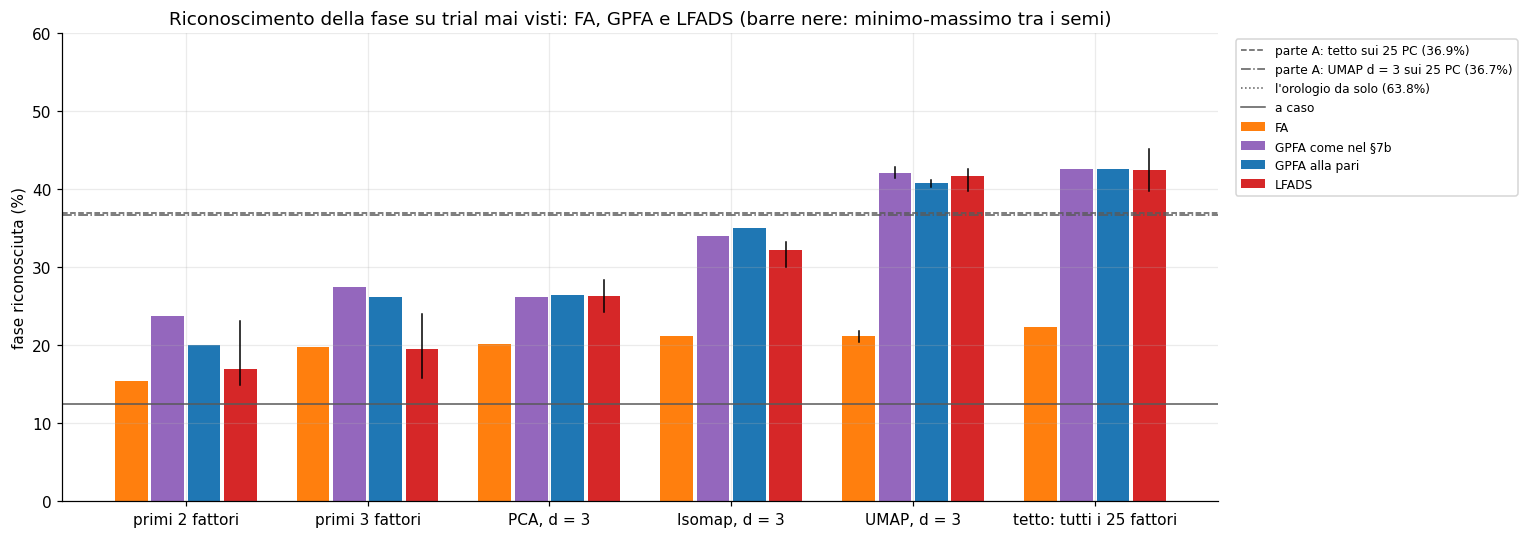

In [76]:
MEAS_PLOT = ["primi 2 fattori", "primi 3 fattori", "PCA, d = 3", "Isomap, d = 3", "UMAP, d = 3", "tetto: tutti i 25 fattori"]
COL12 = {"FA": "C1", "GPFA come nel §7b": "C4", "GPFA alla pari": "C0", "LFADS": "C3"}
fig, ax = plt.subplots(figsize=(14, 5))
w12 = 0.2
for i, name in enumerate(GETTERS12):
    for j, meas in enumerate(MEAS_PLOT):
        v = np.atleast_1d(ACC12[(name, meas)])
        x = j + (i - 1.5) * w12
        ax.bar(x, v.mean(), width=w12 * 0.9, color=COL12[name], label=name if j == 0 else None)
        if len(v) > 1:
            ax.plot([x, x], [v.min(), v.max()], color="k", lw=1)  # minimo-massimo tra i semi
for yv, lab, ls in ((ACC["tetto, 25 dimensioni"], f"parte A: tetto sui 25 PC ({ACC['tetto, 25 dimensioni']:.1f}%)", "--"),
                    (np.mean(ACC["UMAP, d = 3"]), f"parte A: UMAP d = 3 sui 25 PC ({np.mean(ACC['UMAP, d = 3']):.1f}%)", "-."),
                    (acc_clock, f"l'orologio da solo ({acc_clock:.1f}%)", ":"), (12.5, "a caso", "-")):
    ax.axhline(yv, color="0.35", ls=ls, lw=1, label=lab)
ax.set(xticks=range(len(MEAS_PLOT)), xticklabels=MEAS_PLOT, ylim=(0, 60), ylabel="fase riconosciuta (%)",
       title="Riconoscimento della fase su trial mai visti: FA, GPFA e LFADS (barre nere: minimo-massimo tra i semi)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_phase.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **LFADS non batte la GPFA alla pari: è sotto in ogni misura.** Con tutti i 25 fattori (il tetto)
  riconosce la fase nel 46.5% dei punti (44.7-47.7 tra i 5 semi), la GPFA alla pari nel 51.4%: nessuno dei
  5 semi arriva alla GPFA. Con le mappe a 3 coordinate la distanza resta: UMAP 45.8 contro 50.4, Isomap 40.0
  contro 44.9. Solo con la PCA a 3 è piccola (30.9 contro 32.5) e dentro la variazione tra i semi di LFADS
  (27.9-34.7).
- **La distanza più grande è nei primi fattori ordinati**: con 2 e 3 fattori LFADS arriva al 17.9% e al
  20.9%, la GPFA al 32.1% e al 30.9%; con 7, 32.2% contro 41.5%. Le direzioni che pesano di più nelle
  frequenze di LFADS non sono quelle che distinguono le fasi: la PCA a 3 sugli stessi 25 fattori, che
  cerca le direzioni di massima varianza, arriva al 30.9%. Perché, non l'abbiamo verificato.
- **Le due GPFA si equivalgono**: tetto 51.4 (alla pari: pezzi da 600 ms, tutti i bin dei trial di
  training) contro 50.7 (§7b: finestre da 1 s dall'inizio delle fasi); con UMAP 50.4 contro 50.5. Il
  taglio in pezzi da 600 ms non penalizza la GPFA, quindi non spiega la distanza di LFADS.
- **Il modello del tempo conta più di tutto il resto.** La FA, che tratta ogni bin da solo, arriva al
  25.8% con tutti i fattori e al 17.4% con i primi 2. Aggiungere fattori che cambiano gradualmente (la
  GPFA) porta il tetto al 51.4%. Aggiungere regole del moto non lineari (LFADS) non aggiunge altro, anzi
  toglie circa 5 punti. Perché i primi fattori della FA valgano così poco lo vediamo nei controlli del
  §12.3.
- **Rispetto ai riferimenti**: solo le due GPFA superano l'orologio (48.5%). LFADS resta sotto, ma sopra i
  25 PC dei firing rate smussati della parte A (tetto 42.2, UMAP a 3 coordinate 42.6) e sopra CEBRA-Time
  (37.7 e 40.4 con 2 e 3 coordinate libere).
- **Senza `SnapTo` (7 fasi, a caso 14.3%) l'ordine non cambia**: tetto GPFA alla pari 58.5, GPFA del §7b
  57.9, LFADS 53.1 (50.6-54.1), 25 PC della parte A 48.0, FA 29.5. Con i primi 3 fattori LFADS resta il
  più basso dopo la FA (23.6 contro 35.5 e 38.6 delle due GPFA). `SnapTo` non decide il confronto.
- **La figura** riassume la tabella: le barre rosse (LFADS) sono sotto le blu (GPFA alla pari) in ogni
  gruppo, e il minimo-massimo tra i semi (le linee nere) arriva alla GPFA solo con la PCA a 3.
- **Che cosa non dice: perché LFADS resta sotto.** Tre ipotesi, che controlleremo: (1) LFADS impara da 12
  trial, circa 3 minuti di registrazione, e al §11 memorizzava i trial visti (§13: training contro test,
  e quanti trial servono); (2) la configurazione è stata scelta sui canali nascosti, non sulla fase, e il
  peso del KL era sul bordo della griglia (§14); (3) riconoscere la fase non è il compito per cui LFADS è
  costruito: la sua misura, predire i canali nascosti dei trial di test, è al §12b.

### 12.3 · Le traiettorie single-trial

Le misure del §4.2 (seghettatura e consistenza, anche per versione del task) sulle 119 finestre da 1 s,
con i **primi 3 fattori ordinati** dei modelli stimati su **tutti i 15 trial**. Accanto, i numeri della
parte A (PCA, Isomap, UMAP, CEBRA-Time sui 25 PC) e quelli della GPFA del 02_new (0.011 e 0.11, stimata
sulle finestre stesse).

Va tenuto presente che per GPFA alla pari e LFADS ogni finestra è ricucita da pezzi da 600 ms (§9.2),
mentre la GPFA del 02_new vedeva ogni finestra da 1 s intera.

In [77]:
def traj_of(F):                                             # le misure del §4.2 con i primi 3 fattori ordinati
    return traj_stats([w_[:, :3] for w_ in cut(F)])

TRAJ12 = {"FA (tutti i trial)": [traj_of(F_FA12["tutti"])],
          "GPFA alla pari (tutti i trial)": [traj_of(F_GP12["tutti"])],
          "LFADS (tutti i trial, 5 semi)": [traj_of(F_LF12[("tutti", sd)]) for sd in SEEDS_LF],
          **{f"parte A: {name}": TRAJ[name] for name in ("PCA", "Isomap", "UMAP", "CEBRA-Time, 4 dimensioni")}}
def fmt3(v):                                                # "media (minimo-massimo)" con 3 decimali (fmt della parte A ne ha uno: è per le percentuali)
    v = np.atleast_1d(v)
    return f"{v.mean():.3f}" if len(v) == 1 else f"{v.mean():.3f} ({v.min():.3f}-{v.max():.3f})"

rows_t12 = {}
for name, runs in TRAJ12.items():
    d_ = pd.DataFrame(runs)
    rows_t12[name] = {c: fmt3(d_[c].values) for c in d_.columns}
rows_t12["GPFA del 02_new (§10.5, finestre intere)"] = {"seghettatura": "0.011", "consistenza, tutte le ripetizioni": "0.11"}
display(pd.DataFrame(rows_t12).T.fillna("non calcolata"))

,seghettatura,"consistenza, tutte le ripetizioni","consistenza, solo trial dispari","consistenza, solo trial pari",consistenza per versione (media delle due)
FA (tutti i trial),5.734,0.048,0.047,0.063,0.055
GPFA alla pari (tutti i trial),0.009,0.153,0.142,0.201,0.172
"LFADS (tutti i trial, 5 semi)",0.032 (0.021-0.041),0.091 (0.056-0.132),0.106 (0.061-0.166),0.097 (0.073-0.139),0.102 (0.073-0.152)
parte A: PCA,0.011,0.113,0.121,0.136,0.129
parte A: Isomap,0.308,0.061,0.061,0.132,0.096
parte A: UMAP,0.517 (0.469-0.554),0.092 (0.078-0.108),0.098 (0.089-0.117),0.199 (0.179-0.227),0.149 (0.138-0.172)
"parte A: CEBRA-Time, 4 dimensioni",0.077 (0.072-0.084),0.091 (0.086-0.097),0.101 (0.093-0.109),0.124 (0.109-0.153),0.112 (0.101-0.131)
"GPFA del 02_new (§10.5, finestre intere)",0.011,0.11,non calcolata,non calcolata,non calcolata


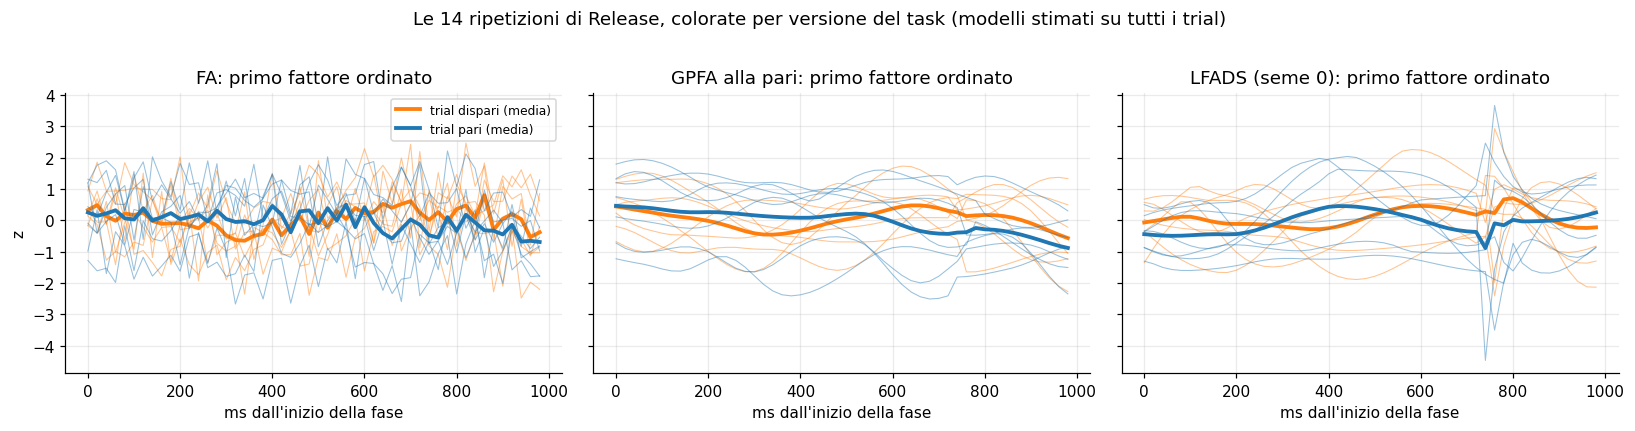

In [78]:
show12 = {"FA": cut(F_FA12["tutti"]), "GPFA alla pari": cut(F_GP12["tutti"]), "LFADS (seme 0)": cut(F_LF12[("tutti", 0)])}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a_, (name, tr_) in zip(ax, show12.items()):
    R = np.stack([tr_[i][:, 0] for i in idx_ph])            # il primo fattore ordinato di ogni ripetizione di Release
    R = (R - R.mean()) / R.std()                            # stessa scala per tutti i modelli
    for odd, c, lab in ((True, "C1", "trial dispari"), (False, "C0", "trial pari")):
        sel = WIN_ODD[idx_ph] == odd
        for r_ in R[sel]:
            a_.plot(t_win, r_, color=c, lw=0.7, alpha=0.45)
        a_.plot(t_win, R[sel].mean(0), color=c, lw=2.5, label=f"{lab} (media)")
    a_.set(title=f"{name}: primo fattore ordinato", xlabel="ms dall'inizio della fase")
ax[0].set_ylabel("z"); ax[0].legend(fontsize=8)
fig.suptitle(f"Le {len(idx_ph)} ripetizioni di {PH_SHOW}, colorate per versione del task (modelli stimati su tutti i trial)", y=1.02)
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_trajectories.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **LFADS è liscio quasi come la GPFA**: seghettatura 0.028 (0.018-0.048 tra i semi) contro 0.017 della
  GPFA alla pari e 0.013 della PCA; molto meno di CEBRA-Time (0.074), Isomap (0.275) e UMAP (0.596). Quasi
  tutta la sua seghettatura viene però da poche finestre, quelle con il cambio di trial (controlli qui
  sotto). La FA, che non ha un modello del tempo, arriva a 7.3: come un rumore senza memoria, anzi un po' di
  più (controlli qui sotto).
- **Consistenza: LFADS e GPFA alla pari.** Su tutte le ripetizioni LFADS 0.109 (0.090-0.135), la GPFA alla
  pari 0.118; separando le due versioni del task 0.132 (0.103-0.155) contro 0.138. La differenza è dentro la
  variazione tra i semi di LFADS. UMAP è un po' più alto (0.125 e 0.144), CEBRA-Time un po' più basso (0.106
  e 0.122), la FA quasi a zero (0.029 e 0.034).
- **Per tutti i metodi la consistenza sale separando le versioni**, e i trial pari sono più simili tra loro
  dei dispari (GPFA alla pari 0.159 contro 0.118, LFADS 0.155 contro 0.109), come per i metodi della parte A
  nelle righe in basso.
- **GPFA alla pari e GPFA del 02_new**: seghettatura 0.017 contro 0.011, consistenza 0.118 contro 0.11. I
  pezzi ricuciti rendono la GPFA un po' meno liscia, non meno consistente.
- **La figura** (le 14 ripetizioni di `Release`, primo fattore ordinato): la FA è rumore attorno a una media
  quasi piatta; GPFA e LFADS danno curve lisce, e in tutti e due la media dei trial dispari scende verso i
  200 ms più di quella dei pari. Tra 760 e 840 ms c'è un salto, molto più forte in LFADS: è il cambio di
  trial, dove i modelli ripartono da capo (controlli qui sotto).
- **Che cosa non dice**: questi modelli sono stimati su tutti i 15 trial, quindi descrivono le traiettorie
  ma non misurano la generalizzazione; e i primi 3 fattori ordinati non sono le direzioni migliori di LFADS
  per distinguere le fasi (§12.2).

#### Due controlli sulle traiettorie: le giunture e il ritmo di 18 Hz

**Le giunture.** Al §11.4 i fattori di due pezzi consecutivi di LFADS, nella zona che hanno in comune,
differivano in media di 0.65 deviazioni standard, e avevamo rimandato qui la domanda: quanto pesano le
giunture sulla seghettatura? Dividiamo i bin delle 119 finestre in due gruppi: quelli **nella zona comune
a due pezzi**, dove la ricucitura fa la media di due pezzi, e quelli **coperti da un pezzo solo**. Poi
calcoliamo la seghettatura in ciascun gruppo (ogni differenza seconda va al suo bin centrale). Se le
giunture contano, la seghettatura è più alta nelle zone comuni. La FA e la PCA della parte A non sono
ricucite: per loro i due gruppi devono dare lo stesso numero, e questo controlla la misura stessa.

**La giuntura più grande: il cambio di trial.** I pezzi non scavalcano mai il confine tra due trial
(§9.2): lì GPFA e LFADS ripartono da capo. Il cambio di trial cade dentro `Release` (§1.5), quindi
dentro le finestre da 1 s di `Release`. Contiamo quali finestre lo contengono e ricalcoliamo la
seghettatura senza di loro.

**Il ritmo di 18 Hz.** I fattori della FA sono più seghettati di un rumore senza memoria. Per un rumore
che cambia a caso da un bin all'altro la seghettatura vale 6 (calcolo a mano: la differenza seconda
x[t+1] − 2x[t] + x[t−1] ha varianza 1 + 4 + 1 = 6 volte quella di x), anzi 6 × 50/49 = 6.12 perché lo
z-score di ogni finestra usa la varianza dei suoi 50 bin. Un'oscillazione che quasi a ogni bin cambia
verso alza ancora la differenza seconda: il ritmo di ~18 Hz del §11.3 fa un periodo ogni 2.8 bin. Per
saperlo misuriamo quanta parte della potenza dei primi 3 fattori ordinati cade tra 16 e 20 Hz, con lo
spettro medio su finestre da 1 s (come al §11.3).

In [79]:
COVER = np.zeros(n_bins, int)                               # in quanti pezzi sta ogni bin della sessione
for t in TRIALS:
    for a in SEG_START[t]:
        COVER[a:a + SEG_LEN] += 1                           # ogni pezzo copre 30 bin a partire dal suo inizio
IN_OVL = COVER > 1                                          # vero per i bin nella zona comune a due pezzi (dove la ricucitura fa la media)
MID = np.concatenate([np.arange(w["start"] + 1, w["stop"] - 1) for w in windows])  # i bin centrali delle differenze seconde, finestra dopo finestra

def rough_split(F):                                         # seghettatura dei primi 3 fattori nei bin delle zone comuni e nei bin di un pezzo solo
    d2 = np.concatenate([(np.diff((T_ - T_.mean(0)) / (T_.std(0) + 1e-9), n=2, axis=0) ** 2).mean(1)  # come roughness (§4.2): un valore per bin centrale
                         for T_ in (F[w["start"]:w["stop"], :3] for w in windows)])
    return d2[IN_OVL[MID]].mean(), d2[~IN_OVL[MID]].mean()

def share_18(F, L=50, step=25):                             # quota della potenza dei primi 3 fattori tra 16 e 20 Hz, spettro medio su finestre da 1 s
    win = np.hanning(L)                                     # la stessa finestra del §11.3
    S = np.mean([np.abs(np.fft.rfft((F[a:a + L, :3] - F[a:a + L, :3].mean(0)) * win[:, None], axis=0)) ** 2
                 for a in range(0, n_bins - L, step)], axis=0)  # potenza per frequenza, una colonna per fattore
    f_ = np.fft.rfftfreq(L, io.BIN_S)                       # le frequenze: da 0 a 25 Hz ogni 1 Hz
    return S[(f_ >= 16) & (f_ <= 20)].sum(0) / S[1:].sum(0)  # quota sulla potenza totale (senza lo 0 Hz)

def cross_tr(w):                                            # vero se nella finestra w cambia il trial
    return bool((np.diff(trial[w["start"]:w["stop"]]) != 0).any())

CUT_MS = [20 * (int(np.flatnonzero(np.diff(trial[w["start"]:w["stop"]]))[0]) + 1) for w in windows if cross_tr(w)]  # dove cade il cambio, in ms dall'inizio della finestra
print(f"Finestre con un cambio di trial: {len(CUT_MS)} su {len(windows)}, delle fasi {sorted({w['tag'] for w in windows if cross_tr(w)})}; "
      f"il cambio cade tra {min(CUT_MS)} e {max(CUT_MS)} ms dall'inizio della finestra")

CTRL12 = {"FA (tutti i trial)": [F_FA12["tutti"]],
          "GPFA alla pari (tutti i trial)": [F_GP12["tutti"]],
          "LFADS (tutti i trial, 5 semi)": [F_LF12[("tutti", sd)] for sd in SEEDS_LF],
          "parte A: PCA (non ricucita)": [PCA(3).fit(X_all).transform(Z25)]}
rows_c = {}
for name, Fs in CTRL12.items():
    sp = np.array([rough_split(F_) for F_ in Fs])           # (semi, 2): zone comuni, un pezzo solo
    q = 100 * np.array([share_18(F_) for F_ in Fs])         # (semi, 3): un valore per fattore, in %
    nb_ = [roughness([F_[w["start"]:w["stop"], :3] for w in windows if not cross_tr(w)]) for F_ in Fs]  # senza le finestre con il cambio di trial
    rows_c[name] = {"seghettatura, zone comuni": fmt3(sp[:, 0]), "seghettatura, un pezzo solo": fmt3(sp[:, 1]),
                    "seghettatura, senza cambio di trial": fmt3(nb_),
                    "16-20 Hz, fattore 1 (%)": fmt(q[:, 0]), "16-20 Hz, fattore 2 (%)": fmt(q[:, 1]), "16-20 Hz, fattore 3 (%)": fmt(q[:, 2])}
display(pd.DataFrame(rows_c).T)
rng_w = np.random.default_rng(0)                            # un rumore senza memoria, per il calcolo a mano
print(f"Bin centrali nelle zone comuni: {IN_OVL[MID].mean() * 100:.1f}%. Rumore senza memoria (2000 finestre da 50 bin): "
      f"seghettatura {roughness([rng_w.standard_normal((50, 3)) for _ in range(2000)]):.2f} (a mano: 6 × 50/49 = {6 * 50 / 49:.2f}); "
      f"quota 16-20 Hz {100 * share_18(rng_w.standard_normal((n_bins, 3))).mean():.1f}% (a mano: 5 frequenze su 25 = 20%)")

Finestre con un cambio di trial: 14 su 119, delle fasi ['Release']; il cambio cade tra 740 e 800 ms dall'inizio della finestra


,"seghettatura, zone comuni","seghettatura, un pezzo solo","seghettatura, senza cambio di trial","16-20 Hz, fattore 1 (%)","16-20 Hz, fattore 2 (%)","16-20 Hz, fattore 3 (%)"
FA (tutti i trial),5.602,5.863,5.984,20.8,19.2,19.0
GPFA alla pari (tutti i trial),0.006,0.012,0.006,0.0,0.0,0.0
"LFADS (tutti i trial, 5 semi)",0.005 (0.005-0.005),0.058 (0.037-0.077),0.005 (0.004-0.005),0.2 (0.1-0.2),0.0 (0.0-0.0),0.0 (0.0-0.1)
parte A: PCA (non ricucita),0.011,0.011,0.011,0.0,0.0,0.0


Bin centrali nelle zone comuni: 49.4%. Rumore senza memoria (2000 finestre da 50 bin): seghettatura 6.12 (a mano: 6 × 50/49 = 6.12); quota 16-20 Hz 20.2% (a mano: 5 frequenze su 25 = 20%)


**Lettura.**

- **Il controllo della misura funziona**: per la FA e la PCA della parte A, che non sono ricucite, i due
  gruppi di bin danno lo stesso numero (FA 7.324 e 7.317, PCA 0.013 e 0.012).
- **Dove si ricuciono i pezzi le traiettorie sono lisce**: nelle zone comuni la seghettatura è 0.005
  (0.004-0.006) per LFADS e 0.012 per la GPFA alla pari, come la PCA. Il disaccordo tra pezzi consecutivi
  visto al §11.4 viene assorbito dalla media pesata, che passa gradualmente da un pezzo all'altro.
- **Tutta la seghettatura in più di LFADS viene dal cambio di trial.** Il cambio cade in 14 finestre su
  119, tutte di `Release`, tra 760 e 840 ms dall'inizio. Senza quelle 14 finestre LFADS scende da 0.028 a
  0.005 (0.004-0.005): **il più liscio di tutti**, più della GPFA alla pari (0.012) e della PCA (0.013).
  Nei bin coperti da un pezzo solo, tra cui l'inizio di ogni trial, sale invece a 0.051 (0.031-0.090). Al
  cambio di trial il modello riparte dalla sola condizione iniziale del primo pezzo, e il primo bin di un
  pezzo era già il punto più debole nei dati sintetici (§10b).
- **I primi fattori della FA sono in buona parte il ritmo di 18 Hz**: tra 16 e 20 Hz cade il 51.4% della
  potenza del primo fattore, il 24.4% del secondo e il 31.1% del terzo. Per un rumore senza memoria è il
  20.1%, come il calcolo a mano (5 frequenze su 25 = 20%); anche la seghettatura del rumore, 6.12,
  coincide con il calcolo a mano (6 × 50/49). Il ritmo del §11.3 è un'attività comune a molti canali, cioè proprio quello
  che la FA cerca, e la FA non ha un modo per preferire i segnali lenti: lo mette nei fattori più forti. È
  coerente con la seghettatura sopra quella del rumore (un'oscillazione che cambia verso ogni 1.4 bin alza
  la differenza seconda) e con i primi 2-3 fattori della FA al 17% nel riconoscimento della fase (§12.2).
- **GPFA e LFADS il ritmo non lo prendono**: tra 16 e 20 Hz cade lo 0.0% e lo 0.2% (0.1-0.5) della potenza
  del primo fattore, come per la PCA dei firing rate smussati. La GPFA, con fattori che cambiano
  gradualmente, non potrebbe; LFADS in linea di principio potrebbe, ma non lo fa, in accordo con il §11.3
  (i trial generati da LFADS non avevano l'autocorrelazione oscillante dei dati veri).
- **Che cosa non dice**: il controllo guarda i primi 3 fattori ordinati e le finestre da 1 s, non tutti i
  25 fattori; che il salto al cambio di trial pesi anche sul riconoscimento della fase è poco probabile
  (pochi punti di valutazione cadono vicino a un confine, §1.5), ma non l'abbiamo misurato; l'origine del
  ritmo di 18 Hz resta sconosciuta (§11.3).

### Riepilogo del §12a

**Prima risposta alla domanda della parte B**, per il riconoscimento della fase e le traiettorie: **no**,
su questi dati la non linearità e le regole del moto imparate da LFADS non migliorano la GPFA. Le
traiettorie di LFADS sono più lisce dentro i trial e consistenti come quelle della GPFA, ma riconoscono la
fase circa 5 punti peggio.

| domanda | risposta | dove |
|---|---|---|
| LFADS riconosce la fase meglio della GPFA alla pari? | **no**: 46.5% (44.7-47.7) contro 51.4% con tutti i 25 fattori; sotto anche con le mappe a 3 coordinate e senza `SnapTo` | §12.2 |
| e rispetto agli altri metodi? | sopra i 25 PC della parte A (42.2%) e CEBRA-Time; sotto l'orologio (48.5%), che superano solo le GPFA | §12.2 |
| che cosa conta di più? | avere un modello del tempo: FA 25.8%, GPFA 51.4%; la non linearità di LFADS non aggiunge | §12.2 |
| le traiettorie di LFADS sono lisce e ripetibili? | lisce: 0.005 senza il cambio di trial (GPFA alla pari 0.012); consistenti come la GPFA (0.109 contro 0.118) | §12.3 |
| le giunture tra i pezzi contano? | no; conta il cambio di trial, dove LFADS riparte da capo | §12.3 |
| perché la FA va così male? | i suoi primi fattori sono in buona parte il ritmo di 18 Hz | §12.3 |

**Che cosa non abbiamo verificato**: perché LFADS resta sotto la GPFA (pochi dati e memorizzazione, §13;
configurazione, §14); se la distanza cambia nella misura propria dei modelli generativi, i canali nascosti
dei trial di test (§12b); il tutto vale per una sola sessione e per i 5 blocchi fissati nel 03.

### 12.4 · La misura dei modelli generativi: i canali nascosti dei trial di test (§12b)

Il riconoscimento della fase (§12.2) chiede ai fattori di separare le fasi, una cosa per cui nessuno di
questi modelli è stato allenato. Ora la misura per cui sono costruiti: **predire attività mai vista**
(§9.4). In ogni blocco ogni modello impara sui 12 trial di training, dove vede tutti i 160 canali; nei 3
trial di test riceve solo i **120 canali visibili** e deve indovinare i **40 nascosti**. Il voto è in
bit per spike (§9.4): 0 = "dire sempre la frequenza media del canale", di più = meglio.

Ogni trial è di test in un solo blocco: mettendo in fila le previsioni dei 5 blocchi si ottiene una
previsione di **tutta la sessione** fatta solo su trial mai visti, e il voto si calcola sui 12 233 bin
(il benchmark usa tutti i bin dei trial di test). Accanto, il voto blocco per blocco.

| modello | come predice i nascosti di un trial di test | da dove |
|---|---|---|
| **smoothing + GLM** (il riferimento) | smussa i 120 visibili (σ = 50 ms) e, per ogni nascosto, una regressione di Poisson stimata sui trial di training; penalità 0.1 | §11a, il riferimento del benchmark |
| **FA** | ricava i fattori di ogni bin dai soli visibili, poi la conta attesa del modello per i nascosti | §12.1 |
| **GPFA alla pari** | la stessa GPFA del §12a (stimata sui 160 canali dei pezzi di training); nei pezzi di test ricava i fattori dai soli visibili, poi la conta attesa | §12.1 |
| **LFADS** | la forma "120 visibili + 40 nascosti" del §11: l'encoder legge i visibili, l'uscita dà tutti i 160. Configurazione del §11b, 200 epoche, 5 semi | §11, §12.1 |

**La conta attesa di FA e GPFA.** Questi due modelli descrivono la **radice** dei conteggi, con un rumore
gaussiano. Se la radice di un conteggio y ha media μ e varianza v, allora la media di y è μ² + v. La
varianza v ha due parti: il rumore proprio del canale (R per la GPFA, Ψ per la FA) e l'incertezza sui
fattori, che dai soli 120 visibili non si ricavano esattamente (Σ, portata sul canale dai suoi pesi:
c Σ cᵀ). Al §10b, con tutti i canali visibili, avevamo usato μ² + R; qui usiamo la formula completa, e
μ² + R resta come variante.

**Una seconda variante della GPFA**: invece della conta attesa del modello, una regressione di Poisson dai
25 fattori (ricavati dai visibili) a ogni canale nascosto, stimata sui trial di training, come fanno i
riferimenti del benchmark con i modelli che non predicono da soli i conteggi. Penalità 0.1, come per lo
smoothing, senza sceglierla apposta.

**Tre calcoli a mano**, prima dei voti: (1) i bit per spike con la formula del §11a e con la
verosimiglianza di Poisson di `scipy`; (2) i fattori della FA con la nostra formula, usando tutti i 160
canali, contro quelli di `scikit-learn`; (3) la previsione della GPFA con il nostro modello ristretto,
usando tutti i 160 canali, contro quella del §10b.

25 allenamenti di LFADS (5 blocchi × 5 semi), 4 alla volta, e 10 regressioni da 40 canali: circa 12 minuti
la prima volta (misurati con il Mac non in risparmio energetico; in risparmio energetico gli allenamenti
durano più del doppio, §12.1).

In [80]:
from scipy.stats import poisson                             # la verosimiglianza di Poisson della libreria, per il calcolo a mano
from sklearn.linear_model import PoissonRegressor           # la regressione di Poisson (già usata al §11a)

LF_HID_HP = dict(LF_HP, n_in=len(HELD_IN))                  # la configurazione del §12a, ma l'encoder legge solo i 120 visibili
RUNS12B = [(k, sd) for k in range(5) for sd in SEEDS_LF]    # (blocco, seme): 25 allenamenti
res12b = dict(zip(RUNS12B, run_lfads_cached([lf12_job(sd, train_trials(k), hp=LF_HID_HP, segs=SEGS_HID, rate_cols=HID_COLS)
                                             for k, sd in RUNS12B])))  # 12 trial di training, 200 epoche; salva le frequenze dei 40 nascosti
ep_b = np.array([r["best_epoch"] for r in res12b.values()])
print(f"LFADS (120 + 40): {len(res12b)} modelli; versione tenuta: epoca {ep_b.min()}-{ep_b.max()} su {N_EP_LF}; "
      f"durata media {np.mean([r['seconds'] for r in res12b.values()]) / 60:.1f} minuti")

Y_HID = COUNTS[:, HIDDEN].astype(float)                     # i conteggi veri dei 40 nascosti, in tutta la sessione

def test_only(per_block):                                   # da "blocco -> previsione di tutta la sessione" alla sessione fatta solo di trial di test
    out = np.empty_like(per_block[0])
    for k in range(5):
        tb = np.isin(trial, TEST_TRIALS[k])                 # i bin dei 3 trial di test del blocco k
        out[tb] = per_block[k][tb]                          # presi dal modello del blocco k, che non li ha mai visti
    return out

PRED_LF = [test_only([stitch_all(res12b[(k, sd)]["rates"]) for k in range(5)]) for sd in SEEDS_LF]  # per seme: conte attese dei 40 nascosti, 12233 × 40

Allenamenti LFADS: 0 eseguiti ora, 25 riletti dal disco
LFADS (120 + 40): 25 modelli; versione tenuta: epoca 196-200 su 200; durata media 2.7 minuti


In [81]:
def gpfa_vis(segs, params, ch):                             # i fattori della GPFA ricavati dai soli canali ch (media e incertezza), pezzo per pezzo
    p_ = dict(params, C=params["C"][ch], d=params["d"][ch], R=params["R"][np.ix_(ch, ch)])  # il modello ristretto ai canali ch
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
        lat, _ = gpfa_core.exact_inference_with_ll(gpfa_seqs(segs[..., ch]), p_, get_ll=False)
    return lat["latent_variable"], lat["Vsm"]               # per pezzo: fattori (25 × bin) e incertezza (25 × 25 × bin)

def gpfa_hidden(segs, params):                              # conte attese dei nascosti in ogni pezzo, dai soli visibili: completa e variante μ² + R
    X_, V_ = gpfa_vis(segs, params, HELD_IN)
    C_h, d_h, r_h = params["C"][HIDDEN], params["d"][HIDDEN], np.diag(params["R"])[HIDDEN]  # pesi, medie e rumore dei nascosti
    mu = np.stack([(C_h @ x_ + d_h[:, None]).T for x_ in X_])  # media della radice dei conteggi: (pezzi, bin, 40)
    unc = np.stack([np.einsum("hi,ijt,hj->th", C_h, v_, C_h) for v_ in V_])  # incertezza sui fattori portata su ogni canale: c Σ cᵀ
    return mu ** 2 + r_h + unc, mu ** 2 + r_h

def fa_hidden(trs, C=None):                                 # FA sui 160 canali dei trial trs; conte attese dei nascosti in tutta la sessione, dai soli visibili
    Y = np.sqrt((COUNTS if C is None else C).astype(float))  # i conteggi (al §13.4 quelli spostati nel tempo)
    fa_ = FactorAnalysis(n_components=K_PCA, svd_method="lapack", random_state=0).fit(Y[np.isin(trial, trs)])
    L, psi, m = fa_.components_.T, fa_.noise_variance_, fa_.mean_  # pesi (160 × 25), rumore di ogni canale (Ψ), medie
    Lv, Lh = L[HELD_IN], L[HIDDEN]
    S = np.linalg.inv(np.eye(K_PCA) + Lv.T @ (Lv / psi[HELD_IN, None]))  # incertezza sui fattori, dati i 120 visibili (Σ)
    X = ((Y[:, HELD_IN] - m[HELD_IN]) / psi[HELD_IN]) @ Lv @ S  # fattori di ogni bin dai soli visibili: Σ Λᵀ Ψ⁻¹ (y − m)
    mu = X @ Lh.T + m[HIDDEN]                               # media della radice dei conteggi dei nascosti
    return mu ** 2 + psi[HIDDEN] + np.einsum("hi,ij,hj->h", Lh, S, Lh)

# (1) bit per spike: formula del §11a contro la verosimiglianza di Poisson di scipy (log k! si cancella nella differenza)
lam_ = PRED_LF[0]
by_scipy = (poisson.logpmf(Y_HID, lam_).sum() - poisson.logpmf(Y_HID, Y_HID.mean(0)).sum()) / Y_HID.sum() / np.log(2)
print(f"(1) bit per spike di LFADS (seme 0): formula del §11a {bits_per_spike(lam_, Y_HID):.6f}, con scipy {by_scipy:.6f}")
# (2) fattori della FA: la nostra formula con tutti i 160 canali contro transform di scikit-learn
Yq = np.sqrt(COUNTS.astype(float))
fa_chk = FactorAnalysis(n_components=K_PCA, svd_method="lapack", random_state=0).fit(Yq[np.isin(trial, train_trials(0))])
L_, psi_ = fa_chk.components_.T, fa_chk.noise_variance_
X_hand = ((Yq - fa_chk.mean_) / psi_) @ L_ @ np.linalg.inv(np.eye(K_PCA) + L_.T @ (L_ / psi_[:, None]))
print(f"(2) FA, fattori a mano contro scikit-learn: differenza massima {np.abs(X_hand - fa_chk.transform(Yq)).max():.1e} "
      f"(i fattori arrivano a {np.abs(X_hand).max():.1f})")
# (3) GPFA: il modello ristretto, con tutti i canali, contro la previsione del §10b
t_chk = int(TEST_TRIALS[0][0])
X_chk, _ = gpfa_vis(SEGS[t_chk], GP12[0], np.arange(N_CH))
mu_chk = np.stack([(GP12[0]["C"] @ x_ + GP12[0]["d"][:, None]).T for x_ in X_chk])
print(f"(3) GPFA, modello ristretto a tutti i 160 canali contro gpfa_sqrt_pred (§10b), trial {t_chk}: "
      f"differenza massima {np.abs(mu_chk - gpfa_sqrt_pred(SEGS[t_chk], GP12[0])).max():.1e}")

(1) bit per spike di LFADS (seme 0): formula del §11a 0.057798, con scipy 0.057798


(2) FA, fattori a mano contro scikit-learn: differenza massima 1.3e-15 (i fattori arrivano a 4.5)
(3) GPFA, modello ristretto a tutti i 160 canali contro gpfa_sqrt_pred (§10b), trial 5: differenza massima 0.0e+00


In [82]:
GP_PIECES = {int(t): gpfa_hidden(SEGS[t], GP12[k]) for k in range(5) for t in TEST_TRIALS[k]}  # ogni trial con la GPFA del blocco in cui è di test
PRED_GP = np.concatenate([stitch(GP_PIECES[int(t)][0], t) for t in TRIALS])     # conta attesa completa, ricucita
PRED_GP_R = np.concatenate([stitch(GP_PIECES[int(t)][1], t) for t in TRIALS])   # variante μ² + R (§10b)
PRED_FA = test_only([fa_hidden(train_trials(k)) for k in range(5)])
PRED_GLM = test_only([smooth_glm_rates(train_trials(k), 0.1) for k in range(5)])  # lo smoothing + GLM del §11a, sui 12 trial di training

def gpfa_glm(k, segs=None, gp=None, C=None, trs=None):     # variante: regressione di Poisson dai 25 fattori GPFA (ricavati dai visibili) ai nascosti, nel blocco k
    segs, gp, C = (SEGS if segs is None else segs), (GP12 if gp is None else gp), (COUNTS if C is None else C)  # al §13.4: i dati spostati nel tempo
    lat = np.concatenate([stitch(np.stack([x_.T for x_ in gpfa_vis(segs[t], gp[k], HELD_IN)[0]]), t) for t in TRIALS])  # fattori di tutta la sessione
    fit_ = np.isin(trial, train_trials(k) if trs is None else trs)  # la regressione si stima sui 12 trial di training (al §13b su meno trial)
    F = StandardScaler().fit(lat[fit_]).transform(lat)
    return np.column_stack([PoissonRegressor(alpha=0.1, max_iter=500).fit(F[fit_], C[fit_, h]).predict(F) for h in HIDDEN])

PRED_GPGLM = test_only([gpfa_glm(k) for k in range(5)])

PRED12B = {"smoothing + GLM (riferimento)": [PRED_GLM], "FA": [PRED_FA], "GPFA alla pari": [PRED_GP],
           "LFADS (5 semi)": PRED_LF,
           "variante: GPFA, μ² + R (§10b)": [PRED_GP_R], "variante: GPFA + regressione di Poisson": [PRED_GPGLM]}

def fmt4(v):                                                # "media [minimo, massimo]" con 4 decimali (le parentesi quadre perché i valori possono essere negativi)
    v = np.atleast_1d(v)
    return f"{v.mean():.4f}" if len(v) == 1 else f"{v.mean():.4f} [{v.min():.4f}, {v.max():.4f}]"

BPS12 = {}                                                  # (modello, dove) -> un valore per seme
for name, P in PRED12B.items():
    BPS12[(name, "tutta la sessione")] = [bits_per_spike(p_, Y_HID) for p_ in P]
    for k in range(5):
        tb = np.isin(trial, TEST_TRIALS[k])                 # i 3 trial di test del blocco k
        BPS12[(name, f"blocco {k}")] = [bits_per_spike(p_[tb], Y_HID[tb]) for p_ in P]
WHERE12 = ["tutta la sessione"] + [f"blocco {k}" for k in range(5)]
display(pd.DataFrame({name: {w: fmt4(BPS12[(name, w)]) for w in WHERE12} for name in PRED12B}).T
        .rename_axis("bit per spike, 40 canali nascosti, trial di test; LFADS: media [minimo, massimo] tra i semi"))
lf_vs = np.array([[BPS12[("LFADS (5 semi)", f"blocco {k}")][i] > BPS12[("smoothing + GLM (riferimento)", f"blocco {k}")][0]
                   for k in range(5)] for i in range(len(SEEDS_LF))])
gp_vs = [BPS12[("LFADS (5 semi)", f"blocco {k}")] > np.array(BPS12[("GPFA alla pari", f"blocco {k}")]) for k in range(5)]
print(f"LFADS sopra lo smoothing + GLM: {int(lf_vs.sum())} casi su {lf_vs.size} (blocco × seme); "
      f"sopra la GPFA alla pari: {int(np.sum(gp_vs))} su {lf_vs.size}")

,tutta la sessione,blocco 0,blocco 1,blocco 2,blocco 3,blocco 4
"bit per spike, 40 canali nascosti, trial di test; LFADS: media [minimo, massimo] tra i semi",,,,,,
smoothing + GLM (riferimento),0.0563,0.0534,0.0545,0.0524,0.0585,0.0472
FA,0.0368,0.0336,0.0317,0.0328,0.0361,0.0341
GPFA alla pari,0.0602,0.0572,0.0568,0.0568,0.0630,0.0521
LFADS (5 semi),"0.0575 [0.0572, 0.0579]","0.0555 [0.0540, 0.0574]","0.0540 [0.0520, 0.0560]","0.0522 [0.0505, 0.0540]","0.0615 [0.0607, 0.0629]","0.0491 [0.0476, 0.0509]"
"variante: GPFA, μ² + R (§10b)",0.0600,0.0567,0.0564,0.0565,0.0634,0.0518
variante: GPFA + regressione di Poisson,0.0642,0.0614,0.0616,0.0595,0.0669,0.0559


LFADS sopra lo smoothing + GLM: 20 casi su 25 (blocco × seme); sopra la GPFA alla pari: 1 su 25


In [83]:
BAND_OF = np.array([next(b for b, b_ in enumerate(bands) if h in b_) for h in HIDDEN])  # la fascia di frequenza (0 = la più lenta) di ogni nascosto
BAND_LAB = [f"fascia {b + 1}: {rate_hz[HIDDEN[BAND_OF == b]].min():.1f}-{rate_hz[HIDDEN[BAND_OF == b]].max():.1f} Hz" for b in range(4)]
rows_band = {name: {BAND_LAB[b]: fmt4([bits_per_spike(p_[:, BAND_OF == b], Y_HID[:, BAND_OF == b]) for p_ in P]) for b in range(4)}
             for name, P in PRED12B.items()}
display(pd.DataFrame(rows_band).T.rename_axis("bit per spike per fascia di frequenza (10 nascosti ciascuna), tutta la sessione"))

,fascia 1: 0.5-2.2 Hz,fascia 2: 3.5-8.0 Hz,fascia 3: 11.2-27.3 Hz,fascia 4: 29.7-47.6 Hz
"bit per spike per fascia di frequenza (10 nascosti ciascuna), tutta la sessione",,,,
smoothing + GLM (riferimento),-0.0098,0.0594,0.0391,0.0663
FA,-0.0090,0.0160,0.0318,0.0435
GPFA alla pari,-0.0092,0.0424,0.0440,0.0728
LFADS (5 semi),"-0.0555 [-0.0620, -0.0475]","0.0734 [0.0720, 0.0746]","0.0398 [0.0389, 0.0405]","0.0671 [0.0668, 0.0674]"
"variante: GPFA, μ² + R (§10b)",-0.0091,0.0428,0.0441,0.0724
variante: GPFA + regressione di Poisson,-0.0085,0.0714,0.0477,0.0733


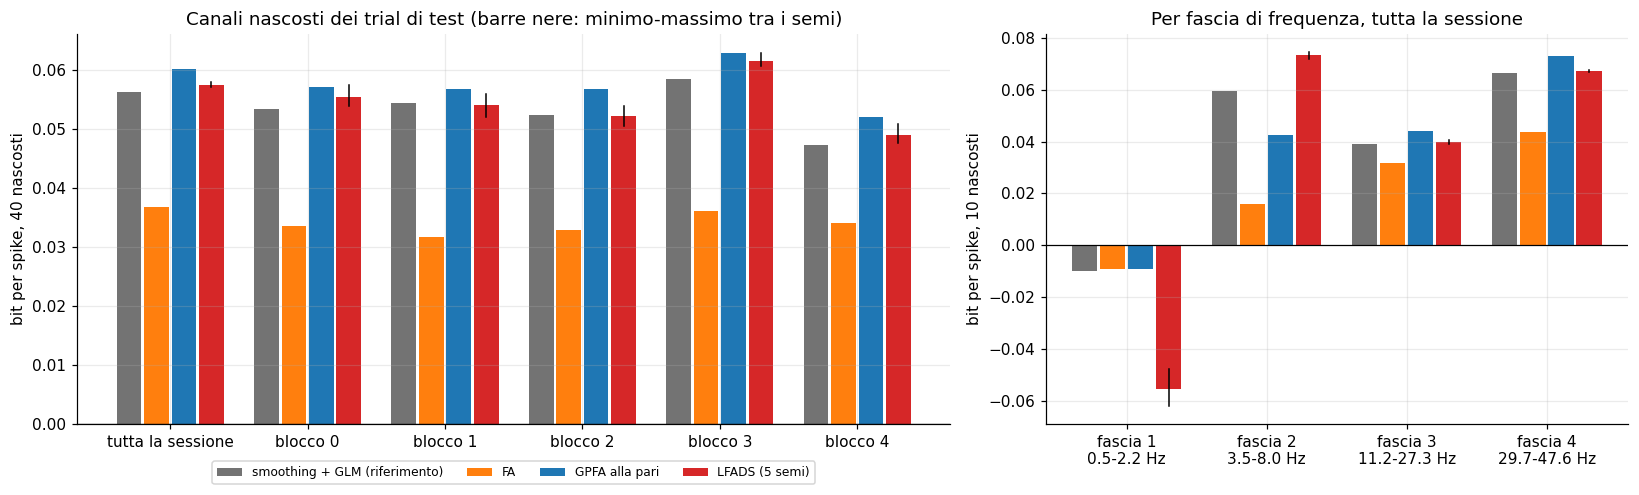

In [84]:
MAIN12B = ["smoothing + GLM (riferimento)", "FA", "GPFA alla pari", "LFADS (5 semi)"]
COL12B = {"smoothing + GLM (riferimento)": "0.45", "FA": "C1", "GPFA alla pari": "C0", "LFADS (5 semi)": "C3"}
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": (1.5, 1)})
for i, name in enumerate(MAIN12B):                          # a sinistra: tutta la sessione e i 5 blocchi
    for j, w in enumerate(WHERE12):
        v = np.array(BPS12[(name, w)])
        x = j + (i - 1.5) * 0.2
        ax[0].bar(x, v.mean(), width=0.18, color=COL12B[name], label=name if j == 0 else None)
        if len(v) > 1:
            ax[0].plot([x, x], [v.min(), v.max()], color="k", lw=1)  # minimo-massimo tra i semi
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set(xticks=range(len(WHERE12)), xticklabels=WHERE12, ylabel="bit per spike, 40 nascosti",
          title="Canali nascosti dei trial di test (barre nere: minimo-massimo tra i semi)")
ax[0].legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08))  # sotto il grafico, per non coprire le barre
for i, name in enumerate(MAIN12B):                          # a destra: per fascia di frequenza
    for b in range(4):
        v = np.array([bits_per_spike(p_[:, BAND_OF == b], Y_HID[:, BAND_OF == b]) for p_ in PRED12B[name]])
        x = b + (i - 1.5) * 0.2
        ax[1].bar(x, v.mean(), width=0.18, color=COL12B[name])
        if len(v) > 1:
            ax[1].plot([x, x], [v.min(), v.max()], color="k", lw=1)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set(xticks=range(4), xticklabels=[l_.replace(": ", "\n") for l_ in BAND_LAB], ylabel="bit per spike, 10 nascosti",
          title="Per fascia di frequenza, tutta la sessione")
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_cobps.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Gli allenamenti**: in tutti i 25 modelli la versione tenuta è tra l'epoca 194 e la 200, in pratica
  l'ultima. 1.8 minuti per modello, con il Mac non più in risparmio energetico (al §12a erano 4.1).
- **I tre calcoli a mano tornano**: i bit per spike con la nostra formula e con `scipy` coincidono
  (0.039313); i fattori della FA con la nostra formula differiscono da quelli di `scikit-learn` di circa
  10⁻¹⁵ (il valore esatto cambia con il numero di thread); la GPFA ristretta, usata con tutti i canali, dà
  esattamente la previsione del §10b
  (differenza 0). Le previsioni dei nascosti poggiano quindi su formule verificate.
- **Sulla sua misura LFADS non batte né la GPFA né il riferimento.** Su tutta la sessione: LFADS 0.0388 bit
  per spike [0.0383, 0.0393 tra i 5 semi], la GPFA alla pari 0.0422, lo smoothing + GLM 0.0416; sotto c'è
  solo la FA (0.0358). Blocco per blocco LFADS supera lo smoothing + GLM in 4 casi su 25 (blocco × seme) e
  la GPFA in 2 su 25; arriva alla pari solo nel blocco 2 (0.0417, come il riferimento; la GPFA 0.0427).
- **Conferma il §11b**: lì, sui trial di validazione, nessuna configurazione superava lo smoothing + GLM;
  qui, su trial mai visti e con 12 trial di training invece di 10, LFADS resta circa il 7% sotto (0.0388
  contro 0.0416).
- **Su questa misura il modello del tempo aiuta poco**: la GPFA supera la FA (0.0422 contro 0.0358), ma lo
  smoothing + GLM, che non ha un modello comune della popolazione, è già quasi lì (0.0416).
- **Conta molto come si passa dai fattori ai conteggi.** La variante GPFA + regressione di Poisson è la
  migliore di tutte, 0.0474 (il 14% sopra il riferimento): gli stessi fattori della GPFA, letti con una
  regressione di Poisson invece che con la conta attesa del modello, predicono meglio. L'incertezza sui
  fattori invece non pesa: con μ² + R la GPFA dà 0.0421 contro 0.0422.
- **Per fascia di frequenza il quadro cambia** (tabella e figura a destra):
  - **canali più lenti** (0.5-2.5 Hz): guadagnano qualcosa solo le due regressioni di Poisson (0.0158 e
    0.0153); GPFA e FA stanno a zero; LFADS va sotto zero (−0.0087 [−0.0129, −0.0028]), cioè fa peggio
    che dire la frequenza media del canale;
  - **3.5-7.8 Hz**: **LFADS è il migliore** (0.0821, contro 0.0709 del riferimento, 0.0780 della GPFA con
    la regressione di Poisson e 0.0441 della GPFA alla pari);
  - **da 10 a 45 Hz**: LFADS è sotto la GPFA (0.0646 contro 0.0704; 0.0210 contro 0.0299). Questi canali
    portano la maggior parte degli spike, e il voto complessivo è la media dei voti delle fasce pesata con i
    loro spike: è qui che LFADS perde.
  - Una spiegazione plausibile, non verificata, per le due fasce lente: la conta attesa di GPFA e FA viene
    da un rumore gaussiano sulla radice dei conteggi, una descrizione povera quando gli spike sono rari;
    i modelli con il rumore di Poisson (le regressioni e LFADS) vanno molto meglio tra 3.5 e 7.8 Hz.
- **Che cosa non dice**: (1) i 40 canali nascosti sono un solo sorteggio (§9.4); (2) perché LFADS va sotto
  zero sui canali più lenti: un'ipotesi è la memorizzazione del §11 (il readout di quei canali impara dai
  trial di training dettagli che non si ripetono), da controllare al §13; (3) la GPFA ha avuto una
  variante con la regressione di Poisson e LFADS no: la stessa regressione sui fattori di LFADS non
  l'abbiamo provata (§14); (4) i numeri del Neural Latents Benchmark non sono confrontabili con questi
  (altri dati, neuroni isolati invece di canali).

### 12.5 · Un canale nascosto, da vicino

Lo stesso trial e lo stesso canale del §11.2 (il trial 12, il nascosto più modulato, 8 secondi), ma ora con
i modelli del blocco in cui il trial 12 è di test: nessuno di loro l'ha mai visto. In grigio il firing rate
smussato con σ = 50 ms, che non è la verità (§11.2) ma aiuta l'occhio; in alto gli spike veri.

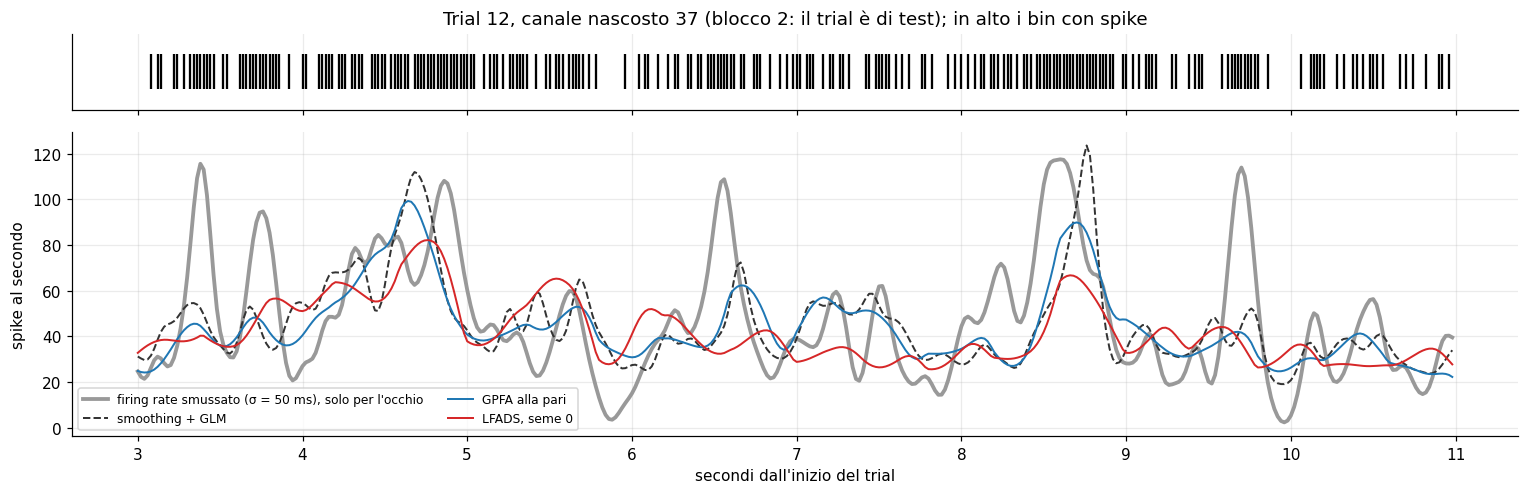

In [85]:
k12 = next(k for k in range(5) if 12 in TEST_TRIALS[k])     # il blocco in cui il trial 12 è di test
h12 = int(np.flatnonzero(HIDDEN == hid_show)[0])            # la colonna del canale mostrato tra i 40 nascosti
fig, ax = plt.subplots(2, 1, figsize=(14, 4.6), sharex=True, gridspec_kw={"height_ratios": (0.25, 1)})
ax[0].eventplot(t_w[COUNTS[win_, hid_show] > 0], color="k", lineoffsets=0.5, linelengths=0.8)  # i bin con almeno uno spike
ax[0].set(yticks=[], title=f"Trial 12, canale nascosto {hid_show} (blocco {k12}: il trial è di test); in alto i bin con spike")
ax[1].plot(t_w, SM_RATE[win_, hid_show], color="0.6", lw=2.5, label="firing rate smussato (σ = 50 ms), solo per l'occhio")
for name, p_, c_, ls_ in (("smoothing + GLM", PRED_GLM, "0.2", "--"), ("GPFA alla pari", PRED_GP, "C0", "-"),
                          ("LFADS, seme 0", PRED_LF[0], "C3", "-")):
    ax[1].plot(t_w, p_[win_, h12] / io.BIN_S, lw=1.3, color=c_, ls=ls_, label=name)  # conte attese per bin -> spike al secondo
ax[1].set(xlabel="secondi dall'inizio del trial", ylabel="spike al secondo"); ax[1].legend(fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_hidden_example.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Tutti e tre i modelli seguono l'andamento lento del canale** senza averlo mai visto in questo trial:
  la salita tra 6 e 7.5 s, le oscillazioni tra 8 e 10 s.
- **LFADS è più liscio**: le sue frequenze cambiano su tempi più lunghi, mentre lo smoothing + GLM e la
  GPFA seguono anche le oscillazioni più rapide.
- **Nessuno scende quanto il firing rate smussato** (per esempio tra 4.8 e 5.2 s, o verso 7.8 s): i modelli
  restano tra 30 e 45 spike al secondo. Il firing rate smussato però non è la verità (§11.2), e le sue
  discese più profonde possono essere rumore.
- **Che cosa non dice**: è un canale solo in un trial solo, scelto con una regola (il nascosto più
  modulato), non per far bella figura a un modello; il confronto è nei numeri del §12.4.

### Riepilogo del §12b

| domanda | risposta | dove |
|---|---|---|
| LFADS predice i canali nascosti dei trial di test meglio della GPFA alla pari? | **no**: 0.0388 [0.0383, 0.0393] contro 0.0422 bit per spike; meglio solo in 2 casi su 25 (blocco × seme) | §12.4 |
| e meglio dello smoothing + GLM? | **no**: 0.0416; meglio solo in 4 casi su 25 | §12.4 |
| chi predice meglio? | la GPFA con una regressione di Poisson sui fattori: 0.0474 | §12.4 |
| dove LFADS va meglio, e dove peggio? | il migliore sui canali tra 3.5 e 7.8 Hz (0.0821); sotto zero sui più lenti, sotto la GPFA sui più veloci | §12.4 |
| i calcoli a mano tornano? | sì: bit per spike, fattori della FA, GPFA ristretta | §12.4 |

### La risposta del §12 alla domanda della parte B

Su questi dati, con 12 trial di training, **la non linearità e le regole del moto imparate da LFADS non
migliorano la GPFA**: né nel riconoscimento della fase (46.5% contro 51.4%, §12.2), né nella misura dei
modelli generativi (0.0388 contro 0.0422 bit per spike, §12.4). LFADS dà traiettorie più lisce dentro i
trial e consistenti come quelle della GPFA (§12.3), ed è il migliore su una sola fascia di canali.

**Che cosa non abbiamo verificato**: perché LFADS resta sotto (§13: memorizzazione, quanti trial servono;
§14: configurazione, peso del KL, lunghezza dei pezzi, controller, regressione di Poisson sui suoi fattori);
un solo sorteggio dei canali nascosti; una sola sessione.

## 13 · I controlli

Il §12 ha dato una risposta negativa: LFADS non migliora la GPFA. Prima di fidarsi, quattro controlli
sui risultati del §12, più uno sulla quantità di dati:

- **§13a (questa parte)**
  - **13.1** quanto cambiano i risultati con il **seme**;
  - **13.2** quanto i modelli vanno meglio sui **trial visti** che sui trial nuovi (la memorizzazione);
  - **13.3** il **gemello di Poisson**: senza legame con il task, il riconoscimento della fase deve
    scendere al caso;
  - **13.4** i **canali nascosti spostati nel tempo**: senza legame tra i canali, il voto deve scendere a 0;
- **§13b**: **13.5-13.7** quanti trial servono, per LFADS e per la GPFA.

### 13.1 · Quanto conta il seme

**Le distanze del §12 sono più grandi della variazione tra i semi?** Lo leggiamo dai numeri già
calcolati.

**I fattori cambiano da un seme all'altro?** La misura della parte A (§5.2): l'R² della trasformazione
lineare che porta i fattori di un seme il più vicino possibile a quelli di un altro, sui 1106 punti di
valutazione, per ogni coppia ordinata di semi (20 coppie). R² = 1 vuol dire "gli stessi fattori, a meno di
una trasformazione lineare". Con tutti i 25 fattori e con i primi 3 ordinati, per i modelli stimati su tutti
i trial e per quelli dei blocchi. GPFA e FA danno un solo modello (punto di partenza fisso), la PCA non
dipende dal caso.

**LFADS e GPFA vedono la stessa cosa?** La stessa misura tra i due modelli: quanto i 25 fattori della GPFA
spiegano quelli di LFADS, e viceversa.

In [86]:
acc_lf = np.array(ACC12[("LFADS", "tetto: tutti i 25 fattori")])           # tetto di LFADS, un valore per seme (§12.2)
acc_gp = ACC12[("GPFA alla pari", "tetto: tutti i 25 fattori")][0]
b_lf = np.array(BPS12[("LFADS (5 semi)", "tutta la sessione")])           # canali nascosti di LFADS, un valore per seme (§12.4)
b_gp = BPS12[("GPFA alla pari", "tutta la sessione")][0]
print(f"Fase (tetto): LFADS da {acc_lf.min():.1f} a {acc_lf.max():.1f} tra i 5 semi (ampiezza {np.ptp(acc_lf):.1f} punti); "
      f"GPFA alla pari {acc_gp:.1f}, {acc_gp - acc_lf.max():.1f} punti sopra il seme migliore")
print(f"Canali nascosti: LFADS da {b_lf.min():.4f} a {b_lf.max():.4f} (ampiezza {np.ptp(b_lf):.4f}); "
      f"GPFA alla pari {b_gp:.4f}, {b_gp - b_lf.max():.4f} sopra il seme migliore")

cons12 = {}
for d_, lab in ((K_PCA, "25 fattori"), (3, "primi 3 fattori ordinati")):
    cons12[f"LFADS, {lab}, stimato su tutti i trial"] = run_consistency([F_LF12[("tutti", sd)][bins, :d_] for sd in SEEDS_LF])
    cons12[f"LFADS, {lab}, modelli dei blocchi (media sui 5)"] = np.array(
        [run_consistency([F_LF12[(k, sd)][bins, :d_] for sd in SEEDS_LF]).mean() for k in range(5)])  # una media per blocco
cons12["parte A: CEBRA-Time, 3 dimensioni, stimato su tutti i trial"] = cons["CEBRA-Time, 3 dimensioni (stimato su tutti i trial)"]
cons12["parte A: UMAP, d = 3"] = cons["UMAP, d = 3"]
G_ = F_GP12["tutti"][bins]                                  # i 25 fattori della GPFA stimata su tutti i trial, sui 1106 punti
cons12["dai 25 fattori della GPFA a quelli di LFADS"] = np.array(
    [LinearRegression().fit(G_, F_LF12[("tutti", sd)][bins]).score(G_, F_LF12[("tutti", sd)][bins]) for sd in SEEDS_LF])
cons12["dai 25 fattori di LFADS a quelli della GPFA"] = np.array(
    [LinearRegression().fit(F_LF12[("tutti", sd)][bins], G_).score(F_LF12[("tutti", sd)][bins], G_) for sd in SEEDS_LF])
display(pd.Series({name: mean_range(v * 100) for name, v in cons12.items()} | {"GPFA, FA (un solo modello), PCA": "100 (per costruzione)"},
                  name="R² (%), media (min-max)").to_frame())

Fase (tetto): LFADS da 39.7 a 45.2 tra i 5 semi (ampiezza 5.4 punti); GPFA alla pari 42.6, -2.6 punti sopra il seme migliore
Canali nascosti: LFADS da 0.0572 a 0.0579 (ampiezza 0.0007); GPFA alla pari 0.0602, 0.0023 sopra il seme migliore


,"R² (%), media (min-max)"
"LFADS, 25 fattori, stimato su tutti i trial",90.3 (89.1-91.5)
"LFADS, 25 fattori, modelli dei blocchi (media sui 5)",89.0 (88.7-89.3)
"LFADS, primi 3 fattori ordinati, stimato su tutti i trial",45.7 (24.3-64.8)
"LFADS, primi 3 fattori ordinati, modelli dei blocchi (media sui 5)",43.0 (40.4-48.4)
"parte A: CEBRA-Time, 3 dimensioni, stimato su tutti i trial",64.5 (51.3-81.5)
"parte A: UMAP, d = 3",94.6 (86.3-99.0)
dai 25 fattori della GPFA a quelli di LFADS,84.6 (84.3-85.0)
dai 25 fattori di LFADS a quelli della GPFA,63.8 (61.6-64.9)
"GPFA, FA (un solo modello), PCA",100 (per costruzione)


**Lettura.**

- **Le distanze del §12 non dipendono dal seme.** Nel riconoscimento della fase i 5 semi di LFADS vanno da
  44.7% a 47.7% (3.0 punti), e la GPFA alla pari sta 3.7 punti sopra il seme migliore. Sui canali nascosti i
  semi vanno da 0.0383 a 0.0393, e la GPFA sta 0.0029 sopra il migliore: una distanza tre volte la
  variazione tra i semi.
- **I 25 fattori di LFADS, presi insieme, sono abbastanza stabili tra i semi**: l'R² da un seme all'altro è
  88.7% (86.7-89.5), e 87.4% con i modelli dei blocchi.
- **I primi 3 fattori ordinati invece cambiano molto**: 40.4%, con coppie di semi che scendono al 29.7%;
  meno anche delle mappe a 3 dimensioni della parte A (CEBRA-Time 63.4%, UMAP 93.3%).
  Le direzioni che pesano di più nelle frequenze non sono le stesse da un seme all'altro: insieme al §12.2
  (primi 3 fattori al 20.9%), dice che per LFADS i "primi fattori" non sono una descrizione affidabile.
  Conta tutto lo spazio dei 25.
- **I fattori della GPFA spiegano quasi tutti quelli di LFADS (85.8%), non il contrario (66.5%).** In parole
  semplici, quello che LFADS descrive è quasi tutto anche nella GPFA, mentre circa un terzo di quello che
  descrive la GPFA non si ritrova, linearmente, in LFADS. Attenzione: l'R² è la media sulle 25 dimensioni,
  ciascuna con lo stesso peso, comprese le più deboli; quali parti della GPFA manchino non l'abbiamo
  verificato.
- **Che cosa non dice**: le misure sono sui 1106 punti di valutazione, cioè solo nelle fasi di movimento,
  e sono lineari: due fattori legati in modo non lineare risultano diversi.

### 13.2 · Trial visti e trial nuovi

Al §11 LFADS prediceva i canali nascosti dei trial su cui aveva imparato tre volte meglio di quelli nuovi.
Qui la stessa domanda per tutti i modelli del §12.4, ciascuno nel suo blocco: i bit per spike dei 40
nascosti sui **12 trial di training** (visti: i loro nascosti sono serviti a stimare il modello) e sui **3
di test** (nuovi), poi la media sui 5 blocchi. Ogni modello va un po' meglio sui trial visti; conta quanto.

Nota: la colonna "trial nuovi" è la media dei 5 blocchi, quindi è vicina ma non uguale al voto di "tutta la
sessione" del §12.4, che mette insieme tutti i bin.

In [87]:
FULL13 = {"smoothing + GLM (riferimento)": [[smooth_glm_rates(train_trials(k), 0.1)] for k in range(5)],  # [blocco][seme] -> previsione di tutta la sessione
          "FA": [[fa_hidden(train_trials(k))] for k in range(5)],
          "GPFA alla pari": [[np.concatenate([stitch(gpfa_hidden(SEGS[t], GP12[k])[0], t) for t in TRIALS])] for k in range(5)],
          "GPFA + regressione di Poisson": [[gpfa_glm(k)] for k in range(5)],
          "LFADS (5 semi)": [[stitch_all(res12b[(k, sd)]["rates"]) for sd in SEEDS_LF] for k in range(5)]}

def seen_new(full, Y):                                      # bit per spike sui trial visti e su quelli nuovi, blocco per blocco: (semi, 5 blocchi, 2)
    out = np.zeros((len(full[0]), 5, 2))
    for k in range(5):
        trn_b, tst_b = np.isin(trial, train_trials(k)), np.isin(trial, TEST_TRIALS[k])  # i bin dei 12 trial di training e dei 3 di test
        for i, p_ in enumerate(full[k]):
            out[i, k] = bits_per_spike(p_[trn_b], Y[trn_b]), bits_per_spike(p_[tst_b], Y[tst_b])
    return out

SN13 = {name: seen_new(full, Y_HID) for name, full in FULL13.items()}
display(pd.DataFrame({name: {"trial visti (training)": fmt4(v[:, :, 0].mean(1)), "trial nuovi (test)": fmt4(v[:, :, 1].mean(1)),
                             "differenza": fmt4((v[:, :, 0] - v[:, :, 1]).mean(1)),
                             "nuovi / visti": fmt4(v[:, :, 1].mean(1) / v[:, :, 0].mean(1))} for name, v in SN13.items()}).T
        .rename_axis("bit per spike, 40 nascosti, media sui 5 blocchi; LFADS: media [minimo, massimo] tra i semi"))

,trial visti (training),trial nuovi (test),differenza,nuovi / visti
"bit per spike, 40 nascosti, media sui 5 blocchi; LFADS: media [minimo, massimo] tra i semi",,,,
smoothing + GLM (riferimento),0.1004,0.0532,0.0472,0.5301
FA,0.0488,0.0337,0.0152,0.6895
GPFA alla pari,0.0770,0.0572,0.0198,0.7424
GPFA + regressione di Poisson,0.0836,0.0611,0.0225,0.7304
LFADS (5 semi),"0.1045 [0.1040, 0.1049]","0.0545 [0.0542, 0.0548]","0.0500 [0.0493, 0.0507]","0.5214 [0.5167, 0.5260]"


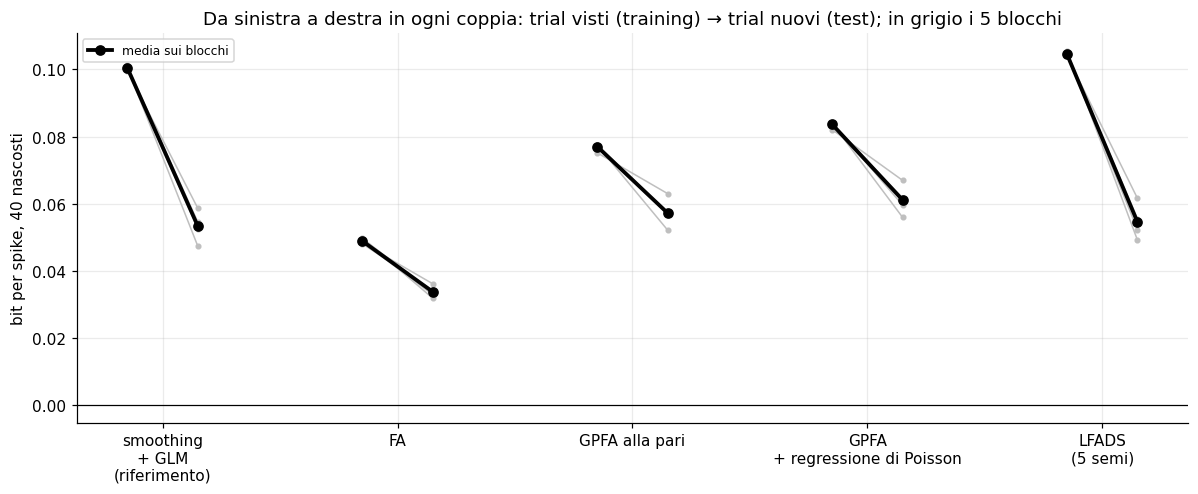

In [88]:
fig, ax = plt.subplots(figsize=(11, 4.6))
for i, (name, v) in enumerate(SN13.items()):
    vb = v.mean(0)                                          # (5 blocchi, 2): per LFADS media sui semi
    for k in range(5):
        ax.plot([i - 0.15, i + 0.15], vb[k], color="0.75", lw=1, marker="o", ms=3)  # un blocco: dai trial visti ai nuovi
    ax.plot([i - 0.15, i + 0.15], vb.mean(0), color="k", lw=2.5, marker="o", ms=6, label="media sui blocchi" if i == 0 else None)
ax.axhline(0, color="k", lw=0.8)
ax.set(xticks=range(len(SN13)), xticklabels=[n_.replace(" (", "\n(").replace(" + ", "\n+ ") for n_ in SN13],
       ylabel="bit per spike, 40 nascosti", title="Da sinistra a destra in ogni coppia: trial visti (training) → trial nuovi (test); in grigio i 5 blocchi")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_overfit.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Tutti i modelli vanno meglio sui trial visti**, ma non allo stesso modo. Sui trial nuovi resta:
  - circa due terzi del voto per FA (0.68), GPFA alla pari (0.66) e GPFA con la regressione di Poisson
    (0.64);
  - meno della metà per lo smoothing + GLM (0.44) e per LFADS (0.40 [0.39, 0.41]).
- **LFADS ha la differenza più grande** (0.0527 bit per spike, contro 0.0482 dello smoothing + GLM e 0.0197
  della GPFA alla pari) e il voto più alto sui trial visti (0.0882): è quello che impara di più dai trial
  di training, e la parte che non si ripete nei trial nuovi è la più grande. È la memorizzazione già vista
  al §11, ora su 5 blocchi e su trial di test.
- **La memorizzazione non spiega da sola la classifica**: lo smoothing + GLM memorizza quasi quanto LFADS,
  eppure sui trial nuovi va meglio (0.0383 contro 0.0355, medie sui blocchi). La GPFA memorizza meno e sui
  trial nuovi è alla pari con il riferimento (0.0389).
- **La figura**: in ogni coppia di punti, il primo è il voto sui trial visti e il secondo quello sui nuovi;
  le linee grigie dei 5 blocchi sono tutte vicine alla media, quindi il quadro è lo stesso in ogni blocco.
- **Che cosa non dice**: se con più trial di training la distanza si chiude (§13b, quanti trial servono);
  e i trial visti qui sono quelli i cui canali nascosti sono serviti a stimare il modello, quindi il loro
  voto non è una misura di generalizzazione.

### 13.3 · Il gemello di Poisson

**La domanda**: il 46.5% di LFADS sul riconoscimento della fase viene davvero dal legame tra attività e
task, o la catena LFADS → ricucitura → metro comune lo crea da sola? Un punto delicato: i pezzi ripartono a
ogni inizio di trial, e il solo tempo dall'inizio del trial riconosce la fase al 48.5% (l'orologio,
§5.3). Se i fattori ricuciti portassero con sé quell'orologio, il riconoscimento resterebbe alto anche su
dati senza alcun legame con il task.

**Il gemello di Poisson.** Partiamo dalle frequenze smussate (σ = 50 ms) dei 160 canali, ne prendiamo la
radice e le passiamo al gemello della parte A (§5.1): stesse ampiezze di Fourier, fasi casuali, **le stesse
per tutti i canali**. Poi torniamo al quadrato ed estraiamo i conteggi a caso con la distribuzione di Poisson.
Il gemello conserva:

- la frequenza media di ogni canale (calcolo a mano: le fasi casuali non cambiano né la media né la varianza
  della radice, e la media del quadrato è media² + varianza);
- le correlazioni tra i canali (stesse fasi per tutti) e la velocità con cui l'attività cambia nel tempo;
- i confini dei trial e i pezzi da 600 ms, che sono gli stessi;

ma l'attività non ha più nessun legame con le fasi del task. La radice serve a tornare a frequenze positive
(il gemello della radice può scendere sotto zero; il suo quadrato no).

Su 3 gemelli (semi 0-2) alleniamo LFADS come al §12a (12 trial di training per blocco, 200 epoche, seme di
LFADS = seme del gemello): 15 allenamenti. Sul gemello 0 anche la GPFA alla pari (5 stime) e, come
termine di confronto, il classificatore direttamente sulle frequenze del gemello. Le etichette di fase sono
quelle vere: **il riconoscimento deve scendere al caso** (12.5%).

In [89]:
TW_SEEDS = range(3)                                         # 3 gemelli
def poisson_twin(seed):                                     # gemello di Poisson: radice delle frequenze smussate a fasi casuali, al quadrato, poi conteggi a caso
    R_tw = phase_randomize(np.sqrt(SM_RATE), seed) ** 2     # frequenze del gemello (Hz), sempre positive
    return np.random.default_rng(1000 + seed).poisson(R_tw * io.BIN_S).astype(np.float32), R_tw  # conteggi per bin da 20 ms

TWIN13 = {sd: poisson_twin(sd) for sd in TW_SEEDS}
C_tw, R_tw0 = TWIN13[0]
Q_tw0 = phase_randomize(np.sqrt(SM_RATE), 0)                # la radice del gemello 0, prima del quadrato
iu = np.triu_indices(N_CH, 1)
print(f"Frequenza media di ogni canale, gemello contro dati: differenza massima {np.abs(R_tw0.mean(0) - SM_RATE.mean(0)).max():.1e} Hz "
      f"(le frequenze medie vanno da {SM_RATE.mean(0).min():.1f} a {SM_RATE.mean(0).max():.1f} Hz)")
print(f"Covarianze tra i canali della radice, gemello contro dati: differenza massima "
      f"{np.abs(np.cov(Q_tw0.T) - np.cov(np.sqrt(SM_RATE).T)).max():.1e} (la più grande vale {np.abs(np.cov(np.sqrt(SM_RATE).T)).max():.2f})")
print(f"Correlazioni tra coppie di canali delle frequenze: gemello contro dati, correlazione "
      f"{np.corrcoef(np.corrcoef(R_tw0.T)[iu], np.corrcoef(SM_RATE.T)[iu])[0, 1]:.3f}")
print(f"Conteggi: bin a zero {np.mean(C_tw == 0) * 100:.1f}% nel gemello, {np.mean(COUNTS == 0) * 100:.1f}% nei dati; "
      f"spike totali {C_tw.sum() / COUNTS.sum():.3f} volte quelli dei dati")
print(f"Legame con i dati veri: correlazione media, canale per canale, tra frequenze del gemello e frequenze vere "
      f"{np.mean([np.corrcoef(R_tw0[:, c], SM_RATE[:, c])[0, 1] for c in range(N_CH)]):.3f}")

Frequenza media di ogni canale, gemello contro dati: differenza massima 4.5e-06 Hz (le frequenze medie vanno da 0.5 a 69.5 Hz)
Covarianze tra i canali della radice, gemello contro dati: differenza massima 1.2e-07 (la più grande vale 4.49)
Correlazioni tra coppie di canali delle frequenze: gemello contro dati, correlazione 0.945
Conteggi: bin a zero 76.4% nel gemello, 74.2% nei dati; spike totali 1.000 volte quelli dei dati
Legame con i dati veri: correlazione media, canale per canale, tra frequenze del gemello e frequenze vere 0.024


In [90]:
SEGS_TW = {sd: {t: cut_segments(TWIN13[sd][0], t) for t in TRIALS} for sd in TW_SEEDS}  # i pezzi dei conteggi di ogni gemello
RUNS_TW = [(k, sd) for k in range(5) for sd in TW_SEEDS]
res_tw13 = dict(zip(RUNS_TW, run_lfads_cached([lf12_job(sd, train_trials(k), segs=SEGS_TW[sd]) for k, sd in RUNS_TW])))
F_LF_TW = {run: order_by_readout(stitch_all(r["factors"]), r["weights"]["readout.0.weight"]) for run, r in res_tw13.items()}
GP_TW = dict(zip(range(5), gpfa_cached([np.concatenate([SEGS_TW[0][t] for t in train_trials(k)]) for k in range(5)])))  # GPFA sul gemello 0
F_GP_TW = {k: stitch_all([gpfa_infer_segments(SEGS_TW[0][t], GP_TW[k]) for t in TRIALS]) for k in range(5)}
Z_TW = StandardScaler().fit_transform(R_tw0)                # le frequenze del gemello 0, z-scorate: il termine di confronto

rows_tw = {"LFADS sul gemello (3 gemelli)": {"primi 3 fattori": fmt([decode_map(fold_inp(lambda k, sd=sd: F_LF_TW[(k, sd)][:, :3]), emb_none) for sd in TW_SEEDS]),
                                             "tetto: tutte le dimensioni": fmt([decode_map(fold_inp(lambda k, sd=sd: F_LF_TW[(k, sd)]), emb_none) for sd in TW_SEEDS])},
           "GPFA alla pari sul gemello 0": {"primi 3 fattori": fmt(decode_map(fold_inp(lambda k: F_GP_TW[k][:, :3]), emb_none)),
                                            "tetto: tutte le dimensioni": fmt(decode_map(fold_inp(lambda k: F_GP_TW[k]), emb_none))},
           "classificatore sulle frequenze del gemello 0 (160 canali)": {"tetto: tutte le dimensioni": fmt(decode_map(fold_inp(lambda k: Z_TW), emb_none))},
           "per confronto, dati veri: LFADS (§12.2)": {"primi 3 fattori": fmt(ACC12[("LFADS", "primi 3 fattori")]), "tetto: tutte le dimensioni": fmt(acc_lf)},
           "per confronto, dati veri: GPFA alla pari (§12.2)": {"primi 3 fattori": fmt(ACC12[("GPFA alla pari", "primi 3 fattori")]), "tetto: tutte le dimensioni": fmt(acc_gp)}}
display(pd.DataFrame(rows_tw).T.fillna("—").rename_axis("fase riconosciuta (%), a caso 12.5"))

Allenamenti LFADS: 0 eseguiti ora, 15 riletti dal disco


GPFA: 0 stimate ora, 5 rilette dal disco


,primi 3 fattori,tetto: tutte le dimensioni
"fase riconosciuta (%), a caso 12.5",,
LFADS sul gemello (3 gemelli),12.6 (11.5-13.6),13.3 (10.9-15.8)
GPFA alla pari sul gemello 0,14.4,17.5
classificatore sulle frequenze del gemello 0 (160 canali),—,16.9
"per confronto, dati veri: LFADS (§12.2)",19.6 (15.8-23.9),42.5 (39.7-45.2)
"per confronto, dati veri: GPFA alla pari (§12.2)",26.2,42.6


**Lettura.**

- **Il gemello è fatto bene**: conserva la frequenza media di ogni canale (differenza massima 5.4·10⁻⁶ Hz,
  la precisione dei numeri a 32 bit) e le covarianze tra i canali della radice (differenza massima 6.4·10⁻⁸),
  come previsto dal calcolo a mano; le correlazioni tra coppie di canali delle frequenze restano quasi le
  stesse (0.921 tra le due matrici), perché il quadrato le cambia un po'. I conteggi sono simili a quelli
  veri (79.1% di bin a zero contro 77.3%, stesso numero di spike), e il gemello non ha legame con i dati veri
  (correlazione media 0.014).
- **Sul gemello tutto scende al caso**: LFADS 11.0% con tutti i fattori (7.8-13.9 tra i 3 gemelli) e 11.8%
  con i primi 3; la GPFA 13.8% e 15.3%; il classificatore sulle frequenze del gemello 13.8%. Tutti intorno al
  12.5%, con le oscillazioni di qualche punto che ci si aspetta da 1106 punti e 8 classi.
- **Quindi il 46.5% di LFADS viene dal legame tra attività e task**, non dalla catena LFADS → ricucitura →
  metro comune. In particolare i fattori ricuciti **non** portano con sé l'orologio dall'inizio del trial: i
  pezzi e i confini dei trial nel gemello sono gli stessi dei dati veri, e l'orologio da solo varrebbe il
  48.5%.
- **Che cosa non dice**: il gemello è gaussiano sulla radice e poi Poisson, quindi esclude una struttura
  qualsiasi che abbia le stesse correlazioni e la stessa velocità dei dati, non ogni possibile struttura
  non lineare; la GPFA è stata provata su un gemello solo.

### 13.4 · I canali nascosti spostati nel tempo

**La domanda**: i bit per spike positivi del §12.4 vengono davvero dalla coordinazione tra i canali, o la
catena (modello, ricucitura, voto) li produce anche senza? Spostiamo nel tempo l'intera registrazione di
ciascuno dei 40 nascosti, di un tratto a caso diverso per ogni canale (tra un quarto e tre quarti della
sessione, cioè tra 61 e 183 s, con rotazione: quello che esce da una parte rientra dall'altra). Ogni
nascosto conserva la sua frequenza media e il suo andamento nel tempo; i visibili restano come sono. Si
perde solo il legame tra i nascosti e i visibili nello stesso istante, cioè proprio quello che serve per
predirli.

Rifacciamo tutto il §12.4 sui dati spostati: LFADS (forma "120 + 40", 3 semi × 5 blocchi), la GPFA alla pari
(5 stime), la FA, lo smoothing + GLM e la GPFA con la regressione di Poisson. **Sui trial nuovi il voto deve
scendere a circa 0.** Sui trial visti invece un modello che memorizza può ancora andare sopra 0.

Un'avvertenza: il task si ripete (un trial ogni 16 s circa), quindi un canale spostato può trovarsi per caso
in una fase simile del task e conservare un po' di legame con i visibili.

In [91]:
rng_sh = np.random.default_rng(0)                           # seme fisso: gli stessi spostamenti a ogni esecuzione
SHIFT = rng_sh.integers(n_bins // 4, 3 * n_bins // 4, size=len(HIDDEN))  # di quanti bin si sposta ciascun nascosto
COUNTS_SH = COUNTS.copy()
COUNTS_SH[:, HIDDEN] = np.column_stack([np.roll(COUNTS[:, h], sh) for h, sh in zip(HIDDEN, SHIFT)])  # rotazione nel tempo, canale per canale
Y_SH = COUNTS_SH[:, HIDDEN].astype(float)                   # i nascosti spostati: ciò che i modelli devono predire
SEGS_SH = {t: cut_segments(COUNTS_SH, t) for t in TRIALS}   # i pezzi dei dati spostati, canali nell'ordine originale (GPFA)
SEGS_SH_HID = {t: SEGS_SH[t][..., ORDER_HID] for t in TRIALS}  # e con prima i 120 visibili, poi i 40 nascosti (LFADS)
SM_SH = io.smooth_rates(COUNTS_SH.astype(float), sigma_ms=50)  # firing rate smussati dei dati spostati, per il controllo qui sotto
R_sh = np.corrcoef(SM_SH.T)
print(f"Spostamenti: da {SHIFT.min() * io.BIN_S:.0f} a {SHIFT.max() * io.BIN_S:.0f} s. Correlazione più alta di un nascosto con un "
      f"visibile: mediana {np.median(R_sh[np.ix_(HIDDEN, HELD_IN)].max(1)):.2f} (prima: {np.median(best_vis):.2f})")

RUNS_SH = [(k, sd) for k in range(5) for sd in range(3)]
res_sh = dict(zip(RUNS_SH, run_lfads_cached([lf12_job(sd, train_trials(k), hp=LF_HID_HP, segs=SEGS_SH_HID, rate_cols=HID_COLS)
                                             for k, sd in RUNS_SH])))
GP_SH = dict(zip(range(5), gpfa_cached([np.concatenate([SEGS_SH[t] for t in train_trials(k)]) for k in range(5)])))
FULL_SH = {"smoothing + GLM (riferimento)": [[smooth_glm_rates(train_trials(k), 0.1, C=COUNTS_SH)] for k in range(5)],
           "FA": [[fa_hidden(train_trials(k), C=COUNTS_SH)] for k in range(5)],
           "GPFA alla pari": [[np.concatenate([stitch(gpfa_hidden(SEGS_SH[t], GP_SH[k])[0], t) for t in TRIALS])] for k in range(5)],
           "GPFA + regressione di Poisson": [[gpfa_glm(k, segs=SEGS_SH, gp=GP_SH, C=COUNTS_SH)] for k in range(5)],
           "LFADS (3 semi)": [[stitch_all(res_sh[(k, sd)]["rates"]) for sd in range(3)] for k in range(5)]}
SN_SH = {name: seen_new(full, Y_SH) for name, full in FULL_SH.items()}
REAL_NAME = {"LFADS (3 semi)": "LFADS (5 semi)", "GPFA + regressione di Poisson": "variante: GPFA + regressione di Poisson"}
display(pd.DataFrame({name: {"dati veri, trial nuovi (§12.4)": fmt4(BPS12[(REAL_NAME.get(name, name), "tutta la sessione")]),
                             "spostati, trial nuovi (tutta la sessione)": fmt4([bits_per_spike(test_only([full[k][i] for k in range(5)]), Y_SH)
                                                                              for i in range(len(full[0]))]),
                             "spostati, trial visti (media sui blocchi)": fmt4(SN_SH[name][:, :, 0].mean(1))}
                      for name, full in FULL_SH.items()}).T.rename_axis("bit per spike, 40 nascosti"))

Spostamenti: da 61 a 178 s. Correlazione più alta di un nascosto con un visibile: mediana 0.07 (prima: 0.15)


Allenamenti LFADS: 0 eseguiti ora, 15 riletti dal disco
GPFA: 0 stimate ora, 5 rilette dal disco


,"dati veri, trial nuovi (§12.4)","spostati, trial nuovi (tutta la sessione)","spostati, trial visti (media sui blocchi)"
"bit per spike, 40 nascosti",,,
smoothing + GLM (riferimento),0.0563,-0.0229,0.0380
FA,0.0368,-0.0050,0.0062
GPFA alla pari,0.0602,-0.0199,0.0196
GPFA + regressione di Poisson,0.0642,-0.0112,0.0245
LFADS (3 semi),"0.0575 [0.0572, 0.0579]","-0.0169 [-0.0171, -0.0166]","0.0529 [0.0512, 0.0544]"


**Lettura.**

- **Lo spostamento toglie il legame tra nascosti e visibili**: la correlazione più alta di un nascosto con
  un visibile scende da 0.18 a 0.07 (mediane). Gli spostamenti estratti vanno da 61 a 180 s.
- **Sui trial nuovi tutti scendono sotto zero**: smoothing + GLM −0.0234, LFADS −0.0179 [−0.0190, −0.0162],
  GPFA alla pari −0.0122, GPFA con la regressione di Poisson −0.0109, FA −0.0044. Senza coordinazione tra i
  canali nessun modello guadagna qualcosa sulla frequenza media: i voti positivi del §12.4 vengono davvero
  dalla struttura comune della popolazione.
- **Sotto zero, non a zero**: ogni modello ha imparato dai trial di training un legame che nei trial nuovi
  non c'è, e lo applica lo stesso, facendo peggio che dire la frequenza media. Chi ha più libertà (lo
  smoothing + GLM, una regressione con 120 ingressi per canale, e LFADS) perde di più.
- **Sui trial visti la memorizzazione si vede da sola**: con i nascosti spostati LFADS arriva a 0.0398 e lo
  smoothing + GLM a 0.0352, quanto (o più di) quello che LFADS fa sui trial nuovi con i dati veri (0.0388).
  Un voto sui trial visti non dice quindi nulla sulla struttura; la GPFA (0.0143) e la FA (0.0055) ne
  inventano molto meno.
- **Che cosa non dice**: uno spostamento solo (seme 0) e 3 semi di LFADS invece di 5; e la ripetizione
  del task (un trial ogni 16 s circa) potrebbe lasciare un po' di legame residuo, che però qui non basta a
  portare sopra zero nessun modello.

### Riepilogo del §13a

| controllo | risultato | dove |
|---|---|---|
| le distanze LFADS-GPFA reggono al cambio di seme? | **sì**: la GPFA è sopra il seme migliore di LFADS (3.7 punti sulla fase, 0.0029 bit per spike sui nascosti) | §13.1 |
| i fattori di LFADS sono stabili tra i semi? | i 25 insieme sì (R² 88.7%); i primi 3 ordinati no (40.4%) | §13.1 |
| LFADS e GPFA descrivono la stessa cosa? | in gran parte: la GPFA spiega l'85.8% di LFADS, LFADS il 66.5% della GPFA | §13.1 |
| LFADS memorizza? | **sì**, come lo smoothing + GLM: sui trial nuovi resta il 40% del voto dei trial visti (GPFA 66%) | §13.2 |
| la catena crea il riconoscimento della fase dal nulla? | **no**: sul gemello di Poisson tutto al caso (LFADS 11.0%) | §13.3 |
| crea voti positivi sui nascosti senza coordinazione? | **no**: con i nascosti spostati nel tempo tutti sotto zero sui trial nuovi | §13.4 |

**Che cosa non abbiamo verificato**: se con più dati LFADS raggiunge o supera la GPFA (§13b); un solo
spostamento dei nascosti e un gemello solo per la GPFA.

In [92]:
# REPLICA: solo le definizioni della cella tolta 190
from itertools import zip_longest

SIZES13 = (4, 7, 10, 12)

def trial_order(k):                                         # l'ordine in cui si aggiungono i 12 trial di training del blocco k
    rng_ = np.random.default_rng(100 + k)                   # seme fisso, diverso per ogni blocco
    odd = [int(t) for t in rng_.permutation([t for t in train_trials(k) if t % 2 == 1])]  # i dispari, in ordine casuale
    even = [int(t) for t in rng_.permutation([t for t in train_trials(k) if t % 2 == 0])]  # i pari, in ordine casuale
    first, second = (odd, even) if k % 2 == 0 else (even, odd)  # nei blocchi 0, 2, 4 si comincia da un dispari, negli altri da un pari
    return [t for pair in zip_longest(first, second) for t in pair if t is not None]

def subset(k, n):                                           # i primi n trial di quell'ordine, rimessi in ordine di tempo (n = 12: train_trials(k))
    return sorted(TRIAL_ORDER[k][:n])

def n_batch(trs):                                           # gruppi da 64 pezzi in un'epoca di allenamento (l'ultimo può essere più piccolo)
    return int(np.ceil(n_seg(trs) / 64))

def ep_same_steps(k, n):                                    # le epoche con cui n trial fanno almeno i passi del §12 (200 epoche con i 12 trial)
    return int(np.ceil(N_EP_LF * n_batch(train_trials(k)) / n_batch(subset(k, n))))

def mm(v):                                                  # "minimo-massimo" di una serie di numeri interi (un numero solo se sono tutti uguali)
    return f"{min(v)}" if min(v) == max(v) else f"{min(v)}-{max(v)}"

In [93]:
# REPLICA: solo le definizioni della cella tolta 191
def job13(form, n, k, sd, rule):                            # un allenamento: forma, quanti trial, blocco, seme, regola
    j_ = lf12_job(sd, subset(k, n), **FORMS13[form])        # come al §12, ma sui trial ridotti
    if rule == "passi del §12":                             # il controllo: più epoche, finché i passi sono quelli del §12
        j_.update(max_epochs=ep_same_steps(k, n), patience=ep_same_steps(k, n))
    return j_

In [94]:
# REPLICA: solo le definizioni della cella tolta 193
GET13 = {}

NAME12 = {"FA": "FA", "GPFA alla pari": "GPFA alla pari", "LFADS (3 semi)": "LFADS"}

def fmt1s(v):                                               # "media [minimo, massimo]" con un decimale (le parentesi quadre perché può essere negativo)
    v = np.atleast_1d(v)
    return f"{v.mean():.1f}" if len(v) == 1 else f"{v.mean():.1f} [{v.min():.1f}, {v.max():.1f}]"

NAMES_PH13 = ["FA", "GPFA alla pari", "LFADS (3 semi)", "LFADS, passi del §12"]

In [95]:
# REPLICA: solo le definizioni della cella tolta 195
def gpfa_hidden_test(gp_of):                                # conte attese dei nascosti di ogni trial di test, dalla GPFA del suo blocco (gp_of: blocco -> parametri)
    pieces = {int(t): gpfa_hidden(SEGS[t], gp_of(k))[0] for k in range(5) for t in TEST_TRIALS[k]}
    return np.concatenate([stitch(pieces[int(t)], t) for t in TRIALS])

PRED13 = {}

NAME12B = {"smoothing + GLM (riferimento)": "smoothing + GLM (riferimento)", "FA": "FA", "GPFA alla pari": "GPFA alla pari",
           "GPFA + regressione di Poisson": "variante: GPFA + regressione di Poisson", "LFADS (3 semi)": "LFADS (5 semi)"}

def bps_blocks(P):                                          # bit per spike sui 3 trial di test di ogni blocco: (semi, 5 blocchi)
    return np.array([[bits_per_spike(p_[np.isin(trial, TEST_TRIALS[k])], Y_HID[np.isin(trial, TEST_TRIALS[k])]) for k in range(5)] for p_ in P])

In [96]:
# REPLICA: solo le definizioni della cella tolta 196
COL13 = {"smoothing + GLM (riferimento)": "0.45", "FA": "C1", "GPFA alla pari": "C0", "GPFA + regressione di Poisson": "C2", "LFADS (3 semi)": "C3"}

In [97]:
# REPLICA: solo le definizioni della cella tolta 200
def job14(var, form, k, sd):                                # un allenamento: variante, forma, blocco, seme; il resto come al §12
    hp_, data_ = FORMS14[form]
    return lf12_job(sd, train_trials(k), hp=dict(hp_, **VARIANTS14A[var]), **data_)

def shapes(w):                                              # le grandezze di un modello lette dai suoi pesi: fattori, generatore
    return w["readout.0.weight"].shape[1], w["decoder.rnn.cell.gen_cell.weight_hh"].shape[1]

In [98]:
# REPLICA: solo le definizioni della cella tolta 202
def acc14(get):                                             # fase riconosciuta: (tetto, primi 3) per una funzione blocco -> fattori
    return decode_map(fold_inp(get), emb_none), decode_map(fold_inp(lambda k: get(k)[:, :3]), emb_none)

def full_lf14(var):                                         # [blocco][seme] -> conte attese dei 40 nascosti in tutta la sessione (forma 120 + 40)
    return [[stitch_all(res14a[(var, "120 + 40", k, sd)]["rates"]) for sd in SEEDS14] for k in range(5)]

def full_gp14(d_):                                          # lo stesso per la GPFA alla pari con d_ fattori (un solo modello per blocco)
    if d_ == K_PCA:
        return FULL13["GPFA alla pari"]                     # con 25 fattori: già calcolata al §13.2
    return [[np.concatenate([stitch(gpfa_hidden(SEGS[t], GP14[d_][k])[0], t) for t in TRIALS])] for k in range(5)]

def fmt2(v):                                                # "media [minimo, massimo]" con 2 decimali
    v = np.atleast_1d(v)
    return f"{v.mean():.2f}" if len(v) == 1 else f"{v.mean():.2f} [{v.min():.2f}, {v.max():.2f}]"

M14 = {}

In [99]:
# REPLICA: solo le definizioni della cella tolta 206
LENS14 = {"pezzi da 400 ms": 20, "pezzi da 1 s": 50}

def starts_L(t, L):                                         # come segment_starts (§9.2), per pezzi di L bin che si sovrappongono di 10
    a0, a1 = TRIAL_SPAN[t]
    st = list(range(a0, a1 - L + 1, L - OVL14))             # un pezzo ogni L − 10 bin...
    if st[-1] != a1 - L:
        st.append(a1 - L)                                   # ...più un ultimo pezzo che finisce esattamente con il trial
    return np.array(st)

def cut_L(X, t, L):                                         # come cut_segments: i pezzi da L bin del trial t di un segnale X
    return np.stack([X[a:a + L] for a in starts_L(t, L)])

def stitch_L(Y_seg, t, L):                                  # come stitch: media pesata, con le rampe di AutoLFADS sui 10 bin in comune
    a0, a1 = TRIAL_SPAN[t]
    W = np.ones((len(Y_seg), L))                            # 1 dove il pezzo è da solo
    W[1:, :OVL14] = RAMP_IN                                 # rampa in salita all'inizio (tranne il primo pezzo del trial)
    W[:-1, -OVL14:] = RAMP_OUT                              # rampa in discesa alla fine (tranne l'ultimo)
    num, den = np.zeros((a1 - a0, Y_seg.shape[2])), np.zeros((a1 - a0, 1))
    for a, y, w in zip(starts_L(t, L) - a0, Y_seg, W):
        num[a:a + L] += w[:, None] * y                      # somma dei valori pesati...
        den[a:a + L] += w[:, None]                          # ...e dei pesi
    return num / den

def stitch_all_L(per_trial, L):                             # come stitch_all: i 15 trial ricuciti e messi in fila
    return np.concatenate([stitch_L(y_, t, L) for t, y_ in zip(TRIALS, per_trial)])

In [100]:
# REPLICA: solo le definizioni della cella tolta 207
def make_lfads_co(hp):
    """Come make_lfads (§10.3), ma con il controller: un secondo encoder, il controller e 4 ingressi inferiti. Si chiama nel processo separato."""
    import numpy as np                                      # numpy PRIMA di torch (§10.3)
    import torch
    from torch import nn
    from lfads_torch.model import LFADS                     # il modello della libreria
    from lfads_torch.modules import augmentations           # il coordinated dropout (qui a 0, come al §12)
    from lfads_torch.modules.priors import AutoregressiveMultivariateNormal, MultivariateNormal  # priori degli ingressi e della condizione iniziale
    from lfads_torch.modules.recons import Poisson          # il modello del rumore: Poisson
    from lfads_torch.modules.readin_readout import FanInLinear  # l'uscita lineare dai fattori alle log-frequenze
    cd = augmentations.CoordinatedDropout(cd_rate=hp["cd_rate"], cd_pass_rate=0.0, ic_enc_seq_len=0)
    return LFADS(encod_data_dim=hp["n_in"], encod_seq_len=hp["seg_len"], recon_seq_len=hp["seg_len"],  # forma dei dati
                 ext_input_dim=0, ic_enc_seq_len=0,         # nessun ingresso esterno; l'encoder legge tutto il pezzo
                 ic_enc_dim=hp["enc_dim"], ci_enc_dim=hp["ci_enc_dim"], ci_lag=1, con_dim=hp["con_dim"], co_dim=hp["co_dim"],  # il controller è acceso
                 ic_dim=hp["ic_dim"], gen_dim=hp["gen_dim"], fac_dim=hp["fac_dim"], dropout_rate=hp["dropout"],
                 reconstruction=nn.ModuleList([Poisson()]), variational=True,
                 co_prior=AutoregressiveMultivariateNormal(tau=hp["co_tau"], nvar=hp["co_nvar"], shape=hp["co_dim"]),  # priori degli ingressi
                 ic_prior=MultivariateNormal(mean=0.0, variance=hp["ic_prior_var"], shape=hp["ic_dim"]),
                 ic_post_var_min=hp["ic_post_var_min"], cell_clip=hp["cell_clip"],
                 train_aug_stack=augmentations.AugmentationStack([cd], batch_order=[0], loss_order=[0]),
                 infer_aug_stack=augmentations.AugmentationStack(),
                 readin=nn.ModuleList([nn.Identity()]), readout=nn.ModuleList([FanInLinear(hp["fac_dim"], hp["n_out"])]),
                 loss_scale=hp["loss_scale"], recon_reduce_mean=True,
                 lr_scheduler=False, lr_init=hp["lr"], lr_stop=1e-5, lr_decay=0.95, lr_patience=6,
                 lr_adam_beta1=0.9, lr_adam_beta2=0.999, lr_adam_epsilon=1e-8, weight_decay=0.0,
                 l2_start_epoch=0, l2_increase_epoch=hp["ramp_epochs"], l2_ic_enc_scale=hp["l2_ic_enc_scale"],
                 l2_ci_enc_scale=hp["l2_ci_enc_scale"], l2_gen_scale=hp["l2_gen_scale"], l2_con_scale=hp["l2_con_scale"],
                 kl_start_epoch=0, kl_increase_epoch=hp["ramp_epochs"], kl_ic_scale=hp["kl_ic_scale"], kl_co_scale=hp["kl_co_scale"])

def run_lfads_cached_co(jobs):                              # run_lfads_cached (§10.5) con il modello del controller
    global make_lfads                                       # durante la chiamata il nome make_lfads indica make_lfads_co: così lfads_fit,
    orig = make_lfads                                       # nel processo separato, costruisce il modello con il controller, e l'impronta
    make_lfads = make_lfads_co                              # di ogni modello (lf_key) contiene il codice di make_lfads_co
    try:
        return run_lfads_cached(jobs)
    finally:
        make_lfads = orig

def co_prior_check(tau, nvar, seed):                        # log-probabilità di alcune sequenze sotto la priori autoregressiva della libreria (processo separato)
    import numpy as np                                      # numpy PRIMA di torch
    import torch
    from lfads_torch.modules.priors import AutoregressiveMultivariateNormal
    torch.manual_seed(seed)
    prior = AutoregressiveMultivariateNormal(tau=tau, nvar=nvar, shape=4)  # 4 ingressi, come in CO14
    x = torch.randn(3, 30, 4)                               # 3 pezzi da 30 bin, 4 ingressi: valori a caso
    with torch.no_grad():
        return x.numpy().astype(np.float64), prior.log_prob(x).numpy().astype(np.float64)

In [101]:
# REPLICA: solo le definizioni della cella tolta 208
def job14b(var, form, k, sd):                               # un allenamento del §14b: variante, forma, blocco, seme; il resto come al §12
    hp_, data_ = FORMS14[form]                              # configurazione e dati delle due forme (§14a)
    if var == "controller":
        return lf12_job(sd, train_trials(k), hp=dict(hp_, **CO14), **data_)  # pezzi da 600 ms, con il controller
    L = LENS14[var]
    hp_L = dict(hp_, seg_len=L, kl_ic_scale=hp_["kl_ic_scale"] * SEG_LEN / L)  # peso del KL: 0.3 / (L × 160)
    if form == "tutti i canali":
        return lf12_job(sd, train_trials(k), hp=hp_L, segs=SEGS14[L])
    return lf12_job(sd, train_trials(k), hp=hp_L, segs=SEGS14_HID[L], rate_cols=HID_COLS)

def co_dim_of(w):                                           # quanti ingressi inferiti ha un modello, letto dai pesi (0 = niente controller)
    return next((v.shape[0] // 2 for k_, v in w.items() if k_.endswith("co_linear.weight")), 0)

In [102]:
# REPLICA: solo le definizioni della cella tolta 210
def fac14b(v, k, sd):                                       # fattori ordinati della variante v (forma con tutti i canali), tutta la sessione
    r = RES14B[(v, "tutti i canali", k, sd)]
    return order_by_readout(stitch_all_L(r["factors"], GEOM14B[v]), r["weights"]["readout.0.weight"])

M14B = {}

GP_SAME14B = {"principale (§12)": "GPFA alla pari, pezzi da 600 ms", "pezzi da 400 ms": "GPFA alla pari, pezzi da 400 ms",
              "pezzi da 1 s": "GPFA alla pari, pezzi da 1 s", "controller": "GPFA alla pari, pezzi da 600 ms"}

In [103]:
# REPLICA: solo le definizioni della cella tolta 211
def co_inputs(hp, model_path, X):                           # gli ingressi inferiti di un modello con il controller salvato su disco, sui pezzi X (processo separato)
    import numpy as np                                      # numpy PRIMA di torch
    import torch
    from lfads_torch.tuples import SessionBatch
    torch.set_num_threads(1)
    model = make_lfads_co(hp)
    model.load_state_dict(torch.load(model_path))           # i pesi della versione tenuta
    model.eval()                                            # niente dropout
    Xt = torch.tensor(X, dtype=torch.float32)
    sb = SessionBatch(encod_data=Xt[..., :hp["n_in"]], recon_data=Xt, ext_input=torch.zeros(len(Xt), Xt.shape[1], 0),
                      truth=torch.zeros(0), sv_mask=torch.ones_like(Xt))
    with torch.no_grad():
        out = model({0: sb}, sample_posteriors=False, output_means=False)[0]  # con la media a posteriori, come per i fattori
    return out.co_means.numpy(), out.co_stds.numpy()

In [104]:
# REPLICA: solo le definizioni della cella tolta 214
def job14b_sh(k, sd):                                       # il controller, forma 120 + 40, sui dati con i nascosti spostati nel tempo (§13.4)
    return lf12_job(sd, train_trials(k), hp=dict(LF_HID_HP, **CO14), segs=SEGS_SH_HID, rate_cols=HID_COLS)

def share18_rates(P, L=50, step=25):                        # quota della variazione tra 16 e 20 Hz nelle frequenze previste (media sui canali), finestre da 1 s
    win = np.hanning(L)                                     # la stessa finestra del §11.3
    S = np.mean([np.abs(np.fft.rfft((P[a:a + L] - P[a:a + L].mean(0)) * win[:, None], axis=0)) ** 2 for a in range(0, len(P) - L, step)], axis=0)
    f_ = np.fft.rfftfreq(L, io.BIN_S)                       # da 0 a 25 Hz, ogni 1 Hz
    return float(np.mean(S[(f_ >= 16) & (f_ <= 20)].sum(0) / S[1:].sum(0)))

def glm_sigma(sg, k):                                       # lo smoothing + GLM del §11a con un'altra σ, stimato sui 12 trial di training del blocco k
    fit_ = np.isin(trial, train_trials(k))
    F = StandardScaler().fit(SMV[sg][fit_]).transform(SMV[sg])
    return np.column_stack([PoissonRegressor(alpha=0.1, max_iter=500).fit(F[fit_], COUNTS[fit_, h]).predict(F) for h in HIDDEN])

In [105]:
# REPLICA: solo le definizioni della cella tolta 217
def job14c(form, k, sd):                                    # un allenamento del VAE per bin: forma, blocco, seme; il resto come al §12
    hp_, _ = FORMS14[form]
    hp1 = dict(hp_, seg_len=1, kl_ic_scale=hp_["kl_ic_scale"] * SEG_LEN)  # pezzi di un bin; peso del KL 0.3 / (1 × 160)
    if form == "tutti i canali":
        j_ = lf12_job(sd, train_trials(k), hp=hp1, segs=SEGS1)
    else:
        j_ = lf12_job(sd, train_trials(k), hp=hp1, segs=SEGS1_HID, rate_cols=HID_COLS)
    j_["apply"] = j_["apply"] + [j_["apply"][list(TRIALS).index(T_SHUF)][PERM]]  # in più: il trial del controllo, rimescolato
    return j_

In [106]:
# REPLICA: solo le definizioni della cella tolta 218
def fac14c(k, sd):                                          # fattori ordinati del VAE per bin (forma con tutti i canali), tutta la sessione
    r = res14c[("tutti i canali", k, sd)]
    return order_by_readout(np.concatenate([f_[:, 0, :] for f_ in r["factors"][:len(TRIALS)]]), r["weights"]["readout.0.weight"])

In [107]:
# REPLICA: solo le definizioni della cella tolta 220
def lfads_glm(k, sd):                                       # regressione di Poisson dai 25 fattori di LFADS (forma 120 + 40) ai 40 nascosti, nel blocco k
    lat = stitch_all(res12b[(k, sd)]["factors"])            # i fattori di tutta la sessione, ricavati dai soli 120 visibili
    fit_ = np.isin(trial, train_trials(k))                  # la regressione si stima sui 12 trial di training
    F = StandardScaler().fit(lat[fit_]).transform(lat)
    return np.column_stack([PoissonRegressor(alpha=0.1, max_iter=500).fit(F[fit_], COUNTS[fit_, h]).predict(F) for h in HIDDEN])

def ratio(sn_):                                             # nuovi / visti, seme per seme, da un array (semi, 5 blocchi, 2) di seen_new
    return list(sn_[:, :, 1].mean(1) / sn_[:, :, 0].mean(1))

In [108]:
# REPLICA: solo le definizioni della cella tolta 221
names_ph = ["FA", "VAE per bin (3 semi)", "GPFA alla pari", "LFADS (principale, semi 0-2)"]

cols_ph = ["C1", "C5", "C0", "C3"]

In [109]:
# REPLICA: solo le definizioni della cella tolta 224
EXTRA_SID = ("19250108T111022", "19250108T111455")

pieces_ex, inside_ex = [], []

In [110]:
# REPLICA: solo le definizioni della cella tolta 225
def job14d(form, k, sd):                                    # come al §12, con i pezzi delle sessioni nuove aggiunti ai pezzi di training
    hp_, data_ = FORMS14[form]
    j_ = lf12_job(sd, train_trials(k), hp=hp_, **data_)
    j_["train"] = j_["val"] = np.concatenate([j_["train"], SEGS_EX if form == "tutti i canali" else SEGS_EX_HID])
    return j_

def job14d_co(form, k, sd):                                 # lo stesso, con il controller del §14b
    j_ = job14d(form, k, sd)
    j_["hp"] = dict(j_["hp"], **CO14)
    return j_

In [111]:
# REPLICA: solo le definizioni della cella tolta 227
def fa_extra(k, extra=True):                                # FA con 25 fattori sui 12 trial di training (e sulle sessioni nuove): fattori ordinati e nascosti
    Y = np.sqrt(COUNTS.astype(float))
    Y_fit = np.concatenate([Y[np.isin(trial, train_trials(k))]] + ([np.sqrt(x_.astype(float)) for x_ in X_EX.values()] if extra else []))
    fa_ = FactorAnalysis(n_components=K_PCA, svd_method="lapack", random_state=0).fit(Y_fit)
    L, psi, m = fa_.components_.T, fa_.noise_variance_, fa_.mean_  # come fa_hidden (§12.4)
    Lv, Lh = L[HELD_IN], L[HIDDEN]
    S = np.linalg.inv(np.eye(K_PCA) + Lv.T @ (Lv / psi[HELD_IN, None]))
    X = ((Y[:, HELD_IN] - m[HELD_IN]) / psi[HELD_IN]) @ Lv @ S  # fattori di ogni bin dai soli visibili
    return order_by_readout(fa_.transform(Y), L), (X @ Lh.T + m[HIDDEN]) ** 2 + psi[HIDDEN] + np.einsum("hi,ij,hj->h", Lh, S, Lh)

def glm_extra(k, extra=True):                               # smoothing + GLM (§11a) stimato sui 12 trial di training (e sulle sessioni nuove)
    fit_ = np.isin(trial, train_trials(k))
    F_fit = np.concatenate([SM_VIS[fit_]] + (SM_VIS_EX if extra else []))
    C_fit = np.concatenate([COUNTS[fit_]] + (list(X_EX.values()) if extra else []))
    sc = StandardScaler().fit(F_fit)
    return np.column_stack([PoissonRegressor(alpha=0.1, max_iter=500).fit(sc.transform(F_fit), C_fit[:, h]).predict(sc.transform(SM_VIS))
                            for h in HIDDEN])

def glm_on(lat, k):                                         # regressione di Poisson da fattori qualsiasi (tutta la sessione) ai nascosti, sui 12 trial di training del blocco k
    fit_ = np.isin(trial, train_trials(k))
    F = StandardScaler().fit(lat[fit_]).transform(lat)
    return np.column_stack([PoissonRegressor(alpha=0.1, max_iter=500).fit(F[fit_], COUNTS[fit_, h]).predict(F) for h in HIDDEN])

In [112]:
# REPLICA: solo le definizioni della cella tolta 232
def fin_row(lab, a2=None, a3=None, a7=None, tetto=None):    # una riga nuova, nello stesso formato della tabella del §8
    return {"etichette": lab, "2 coordinate libere": fmt(a2) if a2 is not None else "", "3 coordinate libere": fmt(a3) if a3 is not None else "",
            "7 coordinate libere": fmt(a7) if a7 is not None else "", "tutte le dimensioni": fmt(tetto) if tetto is not None else ""}

ORDER15 = ["PCA", "Isomap", "UMAP", "CEBRA-Time (3, 4 e 8 dimensioni)", "FA (primi fattori ordinati)", "GPFA (primi fattori)",
           "GPFA alla pari (primi fattori ordinati)", "LFADS (primi fattori ordinati, 5 semi)", "LFADS con il controller (primi fattori ordinati, 3 semi)",
           "VAE per bin (primi fattori ordinati, 3 semi)",
           "UMAP sui fattori della GPFA alla pari", "UMAP sui fattori di LFADS (5 semi)"]

In [113]:
# REPLICA: solo le definizioni della cella tolta 233
COL15 = {"PCA": "C1", "Isomap": "C9", "UMAP": "C2", "CEBRA-Time (4 dimensioni)": "C6", "FA": "C1", "VAE per bin": "C5",
         "GPFA alla pari": "C0", "LFADS": "C3", "LFADS con il controller": "C4"}

In [114]:
# ===== REPLICA (aggiunta): salva i numeri e le tabelle del notebook =====
import pickle, numbers
_num = {k: float(v) for k, v in globals().items() if not k.startswith("_") and isinstance(v, numbers.Real) and not isinstance(v, bool)}
_tabs = {k: v for k, v in globals().items() if not k.startswith("_") and isinstance(v, pd.DataFrame)}
_arrs = {k: v for k, v in globals().items() if not k.startswith("_") and isinstance(v, np.ndarray) and v.size <= 2_000_000}
_dicts = {}
for k, v in globals().items():                               # dizionari di risultati (accuratezze, misure): solo se si salvano
    if not k.startswith("_") and isinstance(v, dict) and k.isupper():
        try:
            pickle.dumps(v); _dicts[k] = v
        except Exception:
            pass
with open(REP / f"{OUT_NAME}.pkl", "wb") as f:
    pickle.dump(dict(numbers=_num, tables=_tabs, arrays=_arrs, dicts=_dicts), f)
print(f"salvati {len(_num)} numeri, {len(_tabs)} tabelle, {len(_arrs)} array, {len(_dicts)} dizionari in {REP / (OUT_NAME + '.pkl')}")


salvati 72 numeri, 10 tabelle, 109 array, 64 dizionari in /Users/valerio/tesi_h1_work/rep/19250120T115044/04_rep.pkl
